# STELES PIPELINE 

## Part II - Wavelength Solution, Spatial Distortion and Blaze correction, and 1d extraction

by Felipe Navarete (LNA/MCTI)

*VERSION FOR DATA TAKEN AFTER MISSION 14 - 2026-01-28 OR LATER*

In [1]:
import logging
import json
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import time
import webbrowser

# local packages
import steles_pipeline_spec as steles_spec
    
from astropy.io import fits
from datetime import datetime, UTC
from scipy.signal import savgol_filter
from scipy.interpolate import UnivariateSpline
    
print("LOADED")

LOADED


In [19]:
class STELES_Pipeline_PartII:

    def __init__(self, config):
        self.cfg = config
        
        self._setup_logging()
        self._setup_directories()

        self._identify_channel()
        self._get_channel_parameters()
        
        # Data containers
        self.arc_cube  = None
        self.flat_cube = None
        self.sci_cube  = None

        self.wave1d  = None
        self.blaze1d = None
        
        #self.wavelength_info = pd.read_excel(self.cfg["wavelength_file"])
        self.wavelength_info = pd.read_excel(self.wavelength_file)
        
    # =========================================================
    # Checkpointing System
    # =========================================================
        
    def _check_done(self, outputs):
        """Check if all output files exist"""
        #return all(os.path.exists(f) for f in outputs) 
        return all(os.path.isfile(f) and os.path.getsize(f) > 0 for f in outputs)
    
    #=========================================================
    # 1. Setup
    #========================================================= 
    def _setup_logging(self):
        logging.basicConfig(level=logging.INFO,
                            format='[%(levelname)s] %(message)s')
        self.log = logging.getLogger("STELES-PartII")
        
    def _create_directory(self, directory):
        
        if not os.path.isdir(directory):
            self.log.info(f"Creating new directory at {directory}")
            os.mkdir(directory)
        else:
            self.log.info(f"Directory '{directory}' already exists.")

    def _setup_directories(self):
        
        raw = self.cfg["raw_directory"]

        if not os.path.exists(raw):
            raise ValueError("<ERROR> Raw directory does not exist.")

        self.red       = os.path.join(raw, "RED/")        
        
        self.wave_dir = os.path.join(self.red, "db_wavelength/")
        self.dist_dir = os.path.join(self.red, "db_distortion/")
        self.plot_dir = os.path.join(self.red, "plots")
        
        self._create_directory(self.wave_dir)
        self._create_directory(self.dist_dir)
        self._create_directory(self.plot_dir)   
                 
            
    def _timeit(self, func, name):
        t0 = time.time()
        func()
        dt = time.time() - t0
        self.log.info(f"{name} completed in {dt:.2f}s")
        
    def _get_bool(self, key, default=False):
        val = self.cfg.get(key, default)

        if isinstance(val, bool):
            return val

        if isinstance(val, str):
            return val.lower() in ["true", "1", "yes"]

        return bool(val)

    def _identify_channel(self):
        """ get channel based on the scientific data """
    
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: _identify_channel()")
            return
        
        self.log.info("Identifying channel")
        
        # check the master science frame
        try:
            sci_files  = [os.path.join(self.red, self.cfg["fileout_sci"] + ".fits")]
        # or the first raw science frame
        except:
            sci_files  = self._resolve("sci_list",  "sci_prefix")
        
        with fits.open(sci_files[0]) as hdul:
            steles_header = hdul[0].header
        
        try:
            self.channel = 'red' if steles_header['FPA'] == "RED" else 'blue'
        except:
            self.channel = 'red' if ( "RED" in steles_header['FIRMWARE'] ) else 'blue'
        
    def _get_channel_parameters(self):
        """
          get default parameters based on the channel - simplifies the config dictionary
        
            gain_per_amplifier (list): relative gain values for each amplifier to apply before merging them
            gain              (float): average gain of the detector (in e-/ADU)
            rdnoise           (float): read noise of the detector (in e-)
            transpose          (bool): transpose frame axis (True for Blue channel, False for Red channel)
            aperture_orders    (list): orders used for creating QC plot showing the apertures before extraction
            y_range            (list): pixel interval in the y-axis (dispersion) to extract the spectrum
            wavelength_file     (str): full path of the wavelength database for the corresponding channel
            x_guesses          (list): central position in the x-axis of each spectral order for each channel
        
        """

        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: get_channel_parameters()")
            return
        
        self.log.info(f"Retrieving parameters for the {self.channel} channel")
        
        self.gain_per_amplifier = [1.034, 1.0]        if self.channel == 'blue' else [1.035, 1.00]
        self.gain               = 2.23                if self.channel == 'blue' else 2.36
        self.rdnoise            = 6.38                if self.channel == 'blue' else 8.47
        self.transpose          = True                if self.channel == 'blue' else False
        self.y_range            = [0, 2047]           if self.channel == 'blue' else [500,3250]
        
        self.wavelength_file = f"./db/{self.channel}_wavelength_solution_2026-01.xlsx"
        
        # center of each order per channel
        if self.channel == 'blue':
            self.x_guesses = [ 56,  165,  270,  373,  473,  571,  665,  758,  848,  936, 1022, 1106, 1187, 1267, 1345, 1421, 1495, 1568, 1639, 1709, # 20
                             1776, 1843, 1907, 1971, 2034, 2095, 2155, 2213, 2271, 2327, 2383, 2436, 2489, 2541, 2593, 2643, 2691, 2740, 2787, 2834, # 40
                             2880, 2925, 2969, 3013, 3055, 3097, 3139, 3179, 3219, 3258, 3297, 3335, 3373, 3409, 3445, 3480, 3515, 3550, 3583, 3616, # 60
                             3650, 3682, 3713, 3745, 3776, 3806, 3836] # 67 - last with good wavelength solution
                             #3650, 3682, 3713, 3745, 3776, 3806, 3836, 3866, 3894, 3923, 3950, 3978, 4005, 4032]                                     # 74
        else:
            self.x_guesses= [  72,  155,  235,  311,  384,  454,  521,  586,  648,  708,  765,  820,  873,  925,  975, 1023, 1069, 1115, 1158, 1200, # 20
                             1241, 1280, 1319, 1356, 1392, 1427, 1460, 1494, 1526, 1558, 1588, 1617, 1647, 1675, 1702, 1728, 1754, 1779, 1804, 1828, # 40
                             1851, 1874, 1895, 1917, 1938, 1958, 1978, 1997]                                                                   # 48

        self.n_orders = len(self.x_guesses)
        
        print_results = False
        if print_results:
            print("  gain_per_ampl=",self.gain_per_amplifier)
            print("           gain=",self.gain)
            print("        rdnoise=",self.rdnoise)
            print("      transpose=",self.transpose)
            print("        y_range=",self.y_range)
            print("       n_orders=",self.n_orders)
            print("      x_guesses=",self.x_guesses)
            print("wavelength_file=",self.wavelength_file)          
    
    #=========================================================
    # 2. Load Products from Part I
    #========================================================= 
    def load_rectified_products(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: load_rectified_products()")
            return

        self.log.info("Loading linearized products")

        def load(name):
            return steles_spec.steles_read_file(
                os.path.join(self.red, name + "_rectified.fits")
            )

        self.flat_cube, _, _ = load(self.cfg["fileout_flat"])
        self.arc_cube,  _, _ = load(self.cfg["fileout_arc"])
        self.sci_cube,  _, _ = load(self.cfg["fileout_sci"])

        self.n_orders, self.n_spat, self.n_spec = self.arc_cube.shape        
        
    #=========================================================
    # 3. Wavelength solution
    #========================================================= 
    def _write_fits(self, data, header, output_path, overwrite=True):
        hdu = fits.PrimaryHDU(data, header=header)
        hdul = fits.HDUList([hdu])
        hdul.writeto(output_path, overwrite=overwrite)
    
    def create_arc1d(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: create_arc1d()")
            return
        
        output = os.path.join(self.red, self.cfg["fileout_arc"] + "_rectified_1d.fits")
        
        if self._check_done([output]) and not self.cfg["overwrite"]:
            self.log.info("Skipping creating 1d arc spectrum")
            return        

        self.log.info("Creating the 1d arc spectrum for wavelength solution")

        # Collapse arc
        ymid = int(0.5 * self.n_spat)
        y_range = [ymid-1, ymid+1]

        arc1d = steles_spec.collapse_spectrum2d(self.arc_cube,
                                           row_range=y_range,
                                           return_average=True)

        # --- Write output ---
        self._write_fits(arc1d, None, output)
        
        self.arc1d = arc1d
    
    def load_arc1d(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: load_arc1d()")
            return
        
        self.log.info("Loading arc1d frame")

        def load(name):
            return steles_spec.steles_read_file(os.path.join(self.red, name + "_rectified_1d.fits"))

        self.arc1d, _, _ = load(self.cfg["fileout_arc"])

    def save_wavelength_qc_table(self):

        rows = []
        for s in self.wavesol_stats:
            rows.append({
                "order":      s["order"],
                "n_lines":    s["n_lines"],
                "dispersion": s["dispersion"],
                "rms":        s["rms"],
                "residuals":  s["residuals"],
                "min_wave":   s["min_wave"],
                "mid_wave":   s["mid_wave"],
                "max_wave":   s["max_wave"]
            })

        df = pd.DataFrame(rows)

        out = os.path.join(self.red, self.cfg["fileout_arc"]+"_wavelength_qc.csv")
        
        df.to_csv(out, index=False)

        self.log.info(f"Saved wavelength QC table: {out}")        
        

    def load_wavelength_qc_table(self):

        out = os.path.join(self.red, self.cfg["fileout_arc"]+"_wavelength_qc.csv")
                
        df = pd.read_csv(out)
        
        self.wavesol_stats = df.to_dict(orient="records")

        self.log.info(f"Loaded wavelength QC table: {out}")                

    def wavelength_solution(self):
        
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: wavelength_solution()")
            return
        
        output = os.path.join(self.red, self.cfg["fileout_arc"] + "_wavelength_solution.fits")
        
        if self._check_done([output]) and not self.cfg["overwrite"]:
            self.log.info("Skipping computing wavelength solution")
            return
        
        self.log.info("Computing wavelength solution")

        self.load_arc1d()
        wave1d = self.arc1d.copy()
        log_lines = []
        wavelength_info = self.wavelength_info
        
        self.wavesol_stats = []

        for order in range(1, self.n_orders + 1):

            spec = self.arc1d[order-1]

            info = wavelength_info[wavelength_info['order'] == order]
            wl = info['wavelength'].to_numpy()
            px = info['pixel'].to_numpy()
            
            px += self.cfg["wavelength_pixel_offset"]

            if not np.isnan(px).any():
                
                file_out = os.path.join(self.wave_dir, self.cfg["fileout_arc"] + f"_n{order:02d}_" )

                w_axis, rms, poly, refined_peak_positions = steles_spec.fit_wavelength_solution(
                    spec, wl, px, order,
                    fit_window=self.cfg["window_fit_peak"],
                    max_fwhm_threshold=self.cfg["max_fwhm_threshold"],
                    wavesolution_ndeg=self.cfg["wavesolution_ndeg"],
                    wavesolution_niter=self.cfg["wavesolution_niter"],
                    wavesolution_rms_threshold=self.cfg["wavesolution_rms_threshold"],
                    save_plots=True,
                    plot_directory=self.wave_dir,
                    plot_prefix=file_out,
                    plot_extension='.png',
                    displ_percent_max=99,
                    ref_thar_directory="./db/",
                    ref_thar_file="ThAr_atlas_3000_10600_75k"
                )
                
                # model prediction at peak pixels
                model_wavelength = poly(refined_peak_positions)
                residuals = model_wavelength - wl
                
                # compute dispersion per order
                dispersion = np.abs(np.diff(w_axis))
                disp_med = np.nanmedian(dispersion)
                n_lines =  len(refined_peak_positions)
                # central, min and max wavelength (in A)
                mid_wave = w_axis[int(0.5*len(w_axis))]
                min_wave = np.nanmin(w_axis)
                max_wave = np.nanmax(w_axis)

            else:
                w_axis = np.arange(len(spec))
                rms = np.nan
                residuals = np.array([])
                disp_med = np.nan
                n_lines =  0
                # central, min and max wavelength (in A)
                mid_wave = np.nan
                min_wave = np.nan
                max_wave = np.nan
  
            wave1d[order-1] = w_axis
            log_lines.append((order, rms))
            
            self.wavesol_stats.append({
                "order": order,
                "min_wave": min_wave,
                "mid_wave": mid_wave,
                "max_wave": max_wave,
                "rms": rms,
                "dispersion": disp_med,
                "n_lines": n_lines,
                "residuals": residuals
            })
        
        
        # show orders with relatively high RMS > 0.5 - should be set by the user?
        bad_orders = [s for s in self.wavesol_stats if s["rms"] > 0.5]
        if len(bad_orders) > 0:
            self.log.warning(f"{len(bad_orders)} orders have large RMS")

        # save the wavelength solution
        self.wave1d = wave1d
        #steles_spec.save_spectrum_to_fits(wave1d, output, overwrite=True)
        self._write_fits(wave1d, None, output, overwrite=True)
        
        self.save_wavelength_qc_table()

    def load_wavelength_solution(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: load_wavelength_solution()")
            return
        
        self.log.info("Loading wavelength solution file")

        def load(name):
            return steles_spec.steles_read_file(os.path.join(self.red, name + ".fits"))
        
        self.wave1d, _, _ = load(self.cfg["fileout_arc"] + "_wavelength_solution")

    def qc_wavelength_rms(self):

        if self._get_bool("dry_run"):
            self.log.info("[DRY RUN] Would execute: qc_wavelength_rms()")
            return
        
        rms = [s["rms"] for s in self.wavesol_stats if np.isfinite(s["rms"])]
        rms = np.asarray(rms)
        rms *= 1000 # in mA
        
        qc_figsize = (10,4)
        qc_dpi     = 300
        qc_nbins = 20
        
        plt.figure(figsize=qc_figsize)
        
        hist_bins = np.linspace(0,np.nanmax(rms), num=qc_nbins)
        plt.hist(rms, bins=hist_bins)
        rms_stat = np.nanpercentile(rms, [15.9,50,84.1])
        plt.axvline(rms_stat[0], ls=':',  color='black', label=r"RMS$_{16\%}$="+f"{rms_stat[0]:.2f}"+r"m$\AA$")
        plt.axvline(rms_stat[1], ls='--', color='black', label=r"RMS$_{50\%}$="+f"{rms_stat[1]:.2f}"+r"m$\AA$")
        plt.axvline(rms_stat[2], ls='-.', color='black', label=r"RMS$_{84\%}$="+f"{rms_stat[2]:.2f}"+r"m$\AA$")
        plt.xlim(0,)
        plt.xlabel(r"RMS per order ($m\AA$)")
        plt.ylabel("Number of orders")
        plt.title("Wavelength Solution RMS")
        plt.legend(fontsize=9)

        out = os.path.join(self.plot_dir, "qc_rms_hist.png")
        plt.tight_layout()
        plt.savefig(out, dpi=qc_dpi)
        plt.close()

        self.log.info(f"Saved RMS histogram: {out}")     
        
    def qc_line_residuals(self):

        if self._get_bool("dry_run"):
            self.log.info("[DRY RUN] Would execute: qc_line_residuals()")
            return

        qc_figsize = (10,4)
        qc_dpi     = 300
        
        plt.figure(figsize=qc_figsize)

        for s in self.wavesol_stats:
            res = s["residuals"]
            if isinstance(res, str):
                res = [float(x) for x in res.strip("[]").split()]

            if len(res) == 0:
                continue

            plt.scatter(
                np.full_like(res, s["order"]),
                res,
                s=10,
                alpha=0.6
            )

        plt.axhline(0, color='black', lw=1)

        plt.xlim(0,self.n_orders+1)
        
        plt.xlabel("Order")
        plt.ylabel(r"Residual ($\AA$)")
        plt.title("Line Residuals")

        out = os.path.join(self.plot_dir, "qc_residuals.png")
        plt.tight_layout()
        plt.savefig(out, dpi=qc_dpi)
        plt.close()

        self.log.info(f"Saved residuals plot: {out}")        

    def qc_dispersion_stability(self):

        if self._get_bool("dry_run"):
            self.log.info("[DRY RUN] Would execute: qc_dispersion_stability()")
            return

        orders = [s["order"]      for s in self.wavesol_stats]
        wave_c = [s["mid_wave"]   for s in self.wavesol_stats]
        disp   = [s["dispersion"] for s in self.wavesol_stats]

        #qc_figsize = (10,4)
        qc_figsize = (10,6)
        qc_dpi     = 300
        
        plt.figure(figsize=qc_figsize)
        
        ################################################
        plt.subplot(211)
        plt.plot(orders, disp, 'o-')
        plt.xlim(0, self.n_orders+1)

        plt.xlabel("Order")
        plt.ylabel(r"Dispersion ($\AA$/pix)")
        plt.suptitle("Dispersion Stability")
        
        ################################################
        plt.subplot(212)
        plt.plot(wave_c, disp, 'o-')
        plt.xlim(np.nanmin(wave_c), np.nanmax(wave_c))

        plt.xlabel(r"Central Wavelength per order ($\AA$)")
        plt.ylabel(r"Dispersion ($\AA$/pix)")

        out = os.path.join(self.plot_dir, "qc_dispersion.png")
        plt.tight_layout()
        plt.savefig(out, dpi=qc_dpi)
        plt.close()

        self.log.info(f"Saved dispersion plot: {out}")        

    def qc_rms_over_dispersion(self, velocity_scale=True):

        if velocity_scale:
            vals = [
                 (s["rms"] / s["mid_wave"] ) * 299792 # in km/s
                for s in self.wavesol_stats
                if s["dispersion"] > 0
            ]
        else:
            vals = [
                s["rms"] / s["dispersion"]
                for s in self.wavesol_stats
                if s["dispersion"] > 0
            ]

        wave_c = [s["mid_wave"]   for s in self.wavesol_stats if s["dispersion"] > 0]
        orders = [s["order"]      for s in self.wavesol_stats if s["dispersion"] > 0]

        orders = np.array(orders)
        wave_c = np.array(wave_c)
        vals   = np.array(vals)
        
        qc_figsize = (10,4)
        qc_dpi     = 300
        
        vals_stat = np.nanpercentile(vals,[16,50,84.1])
        rms_med = vals_stat[1]
        rms_sigma = abs(vals_stat[2]-vals_stat[1])
        
        idx_good   = ( vals <  ( rms_med + 1*rms_sigma ) )
        idx_1sigma = ( vals >= ( rms_med + 1*rms_sigma ) ) * ( vals < ( rms_med + 3*rms_sigma ) )
        idx_3sigma = ( vals >= ( rms_med + 3*rms_sigma ) )
        
        

        plt.figure(figsize=qc_figsize)
        #plt.plot(orders, vals, 'o', label=f'<RMS>={vals_stat[1]:.2f}')
        plt.plot(orders[idx_good],   vals[idx_good],   '+', color='green',  ms=8, zorder=1, label=fr'RMS < 1$\sigma$ ({np.sum(idx_good)}/{len(vals)})')
        plt.plot(orders[idx_1sigma], vals[idx_1sigma], '*', color='orange', ms=5, zorder=1, label=fr'1$\sigma$ < RMS < 3$\sigma$ ({np.sum(idx_1sigma)}/{len(vals)})')
        plt.plot(orders[idx_3sigma], vals[idx_3sigma], 'x', color='red',    ms=5, zorder=1, label=fr'RMS > 3$\sigma$ ({np.sum(idx_3sigma)}/{len(vals)})')
        
        
        plt.axhline(rms_med,
                    ls="--", lw=1, color='black',  zorder=0, alpha=0.5,  label=r'RMS$_{50\%}$='+f'{vals_stat[1]:.2f} km/s')
        plt.axhline(rms_med+1*rms_sigma,
                    ls="-.", lw=1, color='orange', zorder=0, alpha=0.5, label=fr'1$\sigma$={rms_sigma:.2f}')
        plt.axhline(rms_med+3*rms_sigma,
                    ls=":",  lw=1, color='red',    zorder=0, alpha=0.5, label=r'3$\sigma$')
        
        dvals = np.nanmax(vals) - np.nanmin(vals)
        
        # add order number for bad fittings
        for i,idx in enumerate(idx_1sigma):
            if idx:
                #plt.text(orders[i], vals[i]+0.04*dvals, orders[i], verticalalignment='center', horizontalalignment='center', fontsize=10, color='white', weight="bold")
                plt.text(orders[i], vals[i]+0.04*dvals, orders[i], verticalalignment='center', horizontalalignment='center', fontsize=10, color='orange', zorder=2)
        
        # add order number for bad fittings
        for i,idx in enumerate(idx_3sigma):
            if idx:
                #plt.text(orders[i], vals[i]-0.06*dvals, orders[i], verticalalignment='center', horizontalalignment='center', fontsize=10, color='white', weight="bold")
                plt.text(orders[i], vals[i]-0.06*dvals, orders[i], verticalalignment='center', horizontalalignment='center', fontsize=10, color='red', zorder=2)
        
        
        plt.xlabel("Order")
        if velocity_scale:
            plt.ylabel("RMS (km/s)")
        else:
            plt.ylabel("RMS / Dispersion (pix)")
        
        plt.ylim(0,)
        plt.xlim(0,self.n_orders+1)
        plt.legend(fontsize=9, framealpha=0.5)
        plt.title("Wavelength Solution Quality")

        out = os.path.join(self.plot_dir, "qc_rms_over_disp.png")
        plt.tight_layout()
        plt.savefig(out, dpi=qc_dpi)
        plt.close()        
        
    #=========================================================
    # 4. Fit Spatial Distortion
    #========================================================= 

    def _save_polyfits_csv(self, ThAr_peak_pixels, polyfits_x_along_y, output_csv, write_ThAr_peak_pixels=False): #, show_messages=False):

        """
        Save Polynomial1D coefficients to CSV.
        Handles missing/invalid fits by filtering them out.
        """

        # --- Ensure array ---
        polyfits = np.array(polyfits_x_along_y)

        # =====================================================
        # Case 1: 2D (multiple spatial rows × spectral lines)
        # =====================================================
        if polyfits.ndim > 1:

            valid_cols = []

            # --- detect valid spectral lines ---
            for j in range(polyfits.shape[1]):
                try:
                    coeffs = polyfits[0, j].parameters
                    if not np.isnan(coeffs).any():
                        valid_cols.append(j)
                except:
                    continue

            if len(valid_cols) == 0:
                raise RuntimeError("No valid spatial distortion fits to save.")

            # --- filter ---
            pixel_array = ThAr_peak_pixels[valid_cols]
            polyfits = polyfits[:, valid_cols]

            # --- allocate string array ---
            string_array = np.empty(polyfits.shape, dtype=object)

            for i in range(polyfits.shape[0]):   # spatial
                for j in range(polyfits.shape[1]):  # spectral lines
                    coeffs = polyfits[i, j].parameters
                    string_array[i, j] = np.array2string(coeffs, separator=',')

            if write_ThAr_peak_pixels:
                # --- reshape pixel row properly ---
                pixel_array = pixel_array.reshape(1, -1)

                # --- stack ---
                string_array = np.vstack((pixel_array, string_array))

        # =====================================================
        # Case 2: 1D (single fit)
        # =====================================================
        else:

            valid_idx = []

            for i, p in enumerate(polyfits):
                try:
                    if not np.isnan(p.parameters).any():
                        valid_idx.append(i)
                except:
                    continue

            if len(valid_idx) == 0:
                raise RuntimeError("No valid polynomial fits to save.")

            polyfits = polyfits[valid_idx]

            string_array = np.empty(len(polyfits), dtype=object)

            for i in range(len(polyfits)):
                coeffs = polyfits[i].parameters
                string_array[i] = np.array2string(coeffs, separator=',')

            if write_ThAr_peak_pixels:
                pixel_array = np.array([1])
                string_array = np.concatenate((pixel_array, string_array))

        # =====================================================
        # Save
        # =====================================================
        np.savetxt(output_csv, string_array, fmt='%s', delimiter=';')

        #if show_messages:
        #    print(f'File {output_csv} was created.')    
    
    def _write_spatial_distortion_polynomials(self, order, px, polyfits):
        
        # --- Write output ---
        output_csv = os.path.join(self.dist_dir, self.cfg["fileout_arc"] + f"_n{order:02d}_spatdist_polynomials.csv")
        
        # store the distortion coefficients on the database directory
        self._save_polyfits_csv(px, polyfits, output_csv, write_ThAr_peak_pixels=True) #, show_messages=False)
        

    
    def fit_spatial_distortion(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: fit_spatial_distortion()")
            return

        self.log.info("Fitting spatial distortion")

        wavelength_info = self.wavelength_info

        for order in range(1, self.n_orders + 1):
        #for order in range(29, 30 + 1):
            self.log.info(f"[{order}/{self.n_orders}] Fitting spatial distortion")

            data = self.arc_cube[order-1]

            info = wavelength_info[wavelength_info['order'] == order]
            px = info['pixel'].to_numpy()

            if np.isnan(px).any():
                continue

            file_out = os.path.join(self.dist_dir, self.cfg["fileout_arc"] + f"_n{order:02d}_spatdist.png")
            
            return_average_distortion=True  # use "average" fitting considering all features.
            #return_average_distortion=False  # use "average" fitting considering all features.
            
            spat_rows, polyfits = steles_spec.fit_spatial_distortion(
                data,
                px,
                order,
                window=30,
                n_pix_step=1,
                ndeg=self.cfg["ndeg_distortion"],
                fitting_sigma_threshold=self.cfg["fitting_sigma_threshold"],
                fitting_niter=3,
                saturation_threshold=self.cfg["saturation_threshold_for_spatial_distortion"],
                #sigma_threshold=self.cfg["sigma_threshold"],
                sigma_threshold = self.cfg["distortion_sigma_init"],
                sigma_min       = self.cfg["distortion_sigma_min"],
                sigma_step      = self.cfg["distortion_sigma_step"],
                single_fit=return_average_distortion,
                n_col=6,
                output=file_out
            )
            
            # if the fitting was successful, save csv and apply correction
            if ( ~np.isnan(polyfits[0][0].c0.value).any() ):
                self._write_spatial_distortion_polynomials(order, px, polyfits)
            else:
                self.log.info(f"No polynomials fitted for order n={order}, no csv file saved.")

    def _read_spatial_distortion_polynomials(self, order):
        
        # --- Write output ---
        output_csv = os.path.join(self.dist_dir, self.cfg["fileout_arc"] + f"_n{order:02d}_spatdist_polynomials.csv")

        if os.path.isfile(output_csv):
            px, polyfits = steles_spec.read_polyfits_csv(output_csv)
        else:
            self.log.info(f"No csv file to load for order n={order}")
            px, polyfits = np.nan, np.nan
        
        return px, polyfits
        
    #=========================================================
    # 5. Apply Wavelength and Distortion corrections
    #========================================================= 
    def _apply_wave_spat_correction(self,
                                    data2d,
                                    data2d_header,
                                    n_orders,
                                    wave1d,
                                    wavelength_info,
                                    spat_rows,
                                    wave_pixel_reference, 
                                    spatdist_file, 
                                    file_out_prefix, 
                                    wavelength_pixel_offset=0,
                                    file_suffix="_spatdist", 
                                    file_extension=".fits"
                                   ):

        """ Wrapper for applying the wavelength solution and spatial distortion correct the data in a single shot! """

        # create new array for saving the corrected data
        data2d_distcor = np.empty(data2d.shape)

        file_distcor_2d_out = file_out_prefix.replace(file_extension, file_suffix +         file_extension)
        file_distcor_1d_out = file_out_prefix.replace(file_extension, file_suffix + "_1d" + file_extension)

        # start the loop
        spat_corrected_any = False
        for order in np.arange(1,n_orders+1):

            #print(f"Working on order={order}...")

            # now extract the data
            spectrum = data2d[order-1,:]

            # get information for wavelength solution 
            wave_info_order = wavelength_info[wavelength_info['order'] == order]

            # get central wavelength of the lines and the corresponding pixel position
            ThAr_peak_pixels = wave_info_order['pixel'].to_numpy()
            ThAr_peak_pixels += wavelength_pixel_offset # add a constant offset to match the pixel position

            # store the distortion coefficients on the database directory

            # 6.3 apply spatial distortion correction
            px, polyfits = self._read_spatial_distortion_polynomials(order)
            #print(px)
            #print(isinstance(px, np.ndarray))
            
            #if isinstance(px, np.ndarray) and np.all(np.isfinite(px)):
            if np.isfinite(px):
                
                spec_corrected = steles_spec.correct_spatial_distortion(spectrum, spat_rows, polyfits, px, order, y_ref=None,
                                                                    show_plot=False, figsize=(20,12),
                                                                    wave_pixel_reference = wave_pixel_reference, max_displ_percent=99,
                                                                    output=None)
                data2d_distcor[order-1,:,:] = spec_corrected
                
                spat_corrected_any = True
                
            else:
                print(f"No spatial correction solution for order n={order:02d}.")
                data2d_distcor[order-1,:,:] = spectrum

        # add header keywords - 2d data
        data2d_distcor_header = data2d_header.copy()
        
        if spat_corrected_any:
            data2d_distcor_header.set("ST_SPATD", value=True, comment="Spatial distortion corrected")
            data2d_distcor_header.set("ST_FSPAT", value=spatdist_file, comment="Ref file for spatial distortion")
        else:
            data2d_distcor_header.set("ST_SPATD", value=False, comment="Spatial distortion corrected")
            data2d_distcor_header.set("ST_FSPAT", value="NaN", comment="Ref file for spatial distortion")

        # save the extracted orders after correcting for spatial distortion
        #steles_spec.save_spectrum_to_fits(data2d_distcor, file_distcor_2d_out, header=data2d_distcor_header, overwrite=True)
        self._write_fits(data2d_distcor, data2d_distcor_header, file_distcor_2d_out, overwrite=True)

        # add header keywords - 1d data
        data1d_distcor_header = data2d_distcor_header.copy()
        data1d_distcor_header.set("ST_EXT1", value="Integrated Flux", comment="Extension 1")
        data1d_distcor_header.set("ST_EXT2", value="Wavelength",      comment="Extension 2")
        # sum the flux along the slit to create a 1d spectrum
        data1d_distcor = steles_spec.collapse_spectrum2d(data2d_distcor)
        
        #data1d_distcor = np.array([data1d_distcor,wave1d], dtype='float32')
        data1d_distcor = np.asarray([data1d_distcor,wave1d], dtype=np.float64)
        # save the extracted orders after correcting for spatial distortion
        #steles_spec.save_spectrum_to_fits(data1d_distcor,file_distcor_1d_out, header=data1d_distcor_header, overwrite=True)
        self._write_fits(data1d_distcor, data1d_distcor_header, file_distcor_1d_out, overwrite=True)

    def apply_calibration_solution(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: apply_calibration_solution()")
            return

        self.log.info("Applying wavelength + distortion solution")

        spat_rows = np.arange(
            self.cfg["n_pix_step"],
            self.n_spat - self.cfg["n_pix_step"],
            self.cfg["n_pix_step"]
        )

        datasets = [
            ("flat", self.cfg["fileout_flat"]),
            ("arc",  self.cfg["fileout_arc"]),
            ("sci",  self.cfg["fileout_sci"])
        ]

        for kind, name in datasets:

            self.log.info(f"Applying calibration to {kind}")

            file_in = os.path.join(self.red, name + "_rectified.fits")

            with fits.open(file_in) as hdul:
                data = hdul[0].data
                header = hdul[0].header

            self._apply_wave_spat_correction(
                data,
                header,
                self.n_orders,
                self.wave1d,
                self.wavelength_info,
                spat_rows,
                self.cfg["wave_pixel_reference"],
                self.cfg["fileout_arc"],
                file_in,
                wavelength_pixel_offset=self.cfg["wavelength_pixel_offset"],
                file_suffix="_spatdist",
                file_extension=".fits"
            )
        
    #=========================================================
    # 6. Blaze Function
    #========================================================= 

    def load_blaze_solution(self):
        
        self.log.info("Loading blaze solution file")

        def load(name):
            return steles_spec.steles_read_file(os.path.join(self.red, name + ".fits"))
        
        blaze1d, _, _ = load(self.cfg["fileout_flat"] + "_blaze_function")
        
        self.blaze1d = blaze1d#[0,:,:] # get first extension only

    
    def compute_blaze_function(self):   
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: compute_blaze_function()")
            return
        
        output = os.path.join(self.red, self.cfg["fileout_flat"] + "_blaze_function.fits")
        
        if self._check_done([output]) and not self.cfg["overwrite"]:
            self.log.info("Skipping computing blaze function")
            return
        
        self.log.info("Computing blaze function")
        
        if not hasattr(self, "wave1d") or self.wave1d is None:
            self.log.info("Loading wavelength solution")
            self.load_wavelength_solution() 

        flat_file = os.path.join(
            self.red,
            self.cfg["fileout_flat"] + "_rectified_spatdist_1d.fits"
        )

        blaze = steles_spec.fit_quartz(
            flat_file,
            nmin=self.cfg["blaze_min_deg"],
            nmax=self.cfg["blaze_max_deg"],
            sigma_clip_thresh=self.cfg["blaze_sigma"],
            n_cols = self.cfg["blaze_ncols"],
            output_blaze =  os.path.join(self.plot_dir, self.cfg["fileout_flat"] + "_blaze_function.png")
        )
        
        
        self._write_fits(np.asarray([blaze, self.wave1d], dtype=np.float64), None, output, overwrite=True)
        
        #steles_spec.save_spectrum_to_fits(
        #    np.asarray([blaze, self.wave1d], dtype=np.float64),
        #    output,
        #    overwrite=True
        #)        
        
    def apply_blaze(self,
                    file_in,
                    blaze_orders,
                    smooth_blaze=True,
                    smooth_window=31,
                    smooth_poly=3,
                    epsilon=1e-6,
                    renormalize=True):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: apply_blaze()")
            return

        # --- Load data ---
        try:
            with fits.open(file_in) as hdul:
                data = hdul[0].data
        except:
            data = file_in

        # --- Shape handling ---
        if data.ndim == 2:
            n_orders, nx = data.shape
            ny = None
        elif data.ndim == 3:
            n_orders, ny, nx = data.shape
        else:
            raise ValueError("Data format is not allowed.")

        data_corr = data.copy()

        xarr = np.arange(nx)

        # --- Loop over orders ---
        for n in range(n_orders):

            blaze = blaze_orders[0,n,:].copy()
            
            # --------------------------------------------------
            # 1) Normalize blaze (CRITICAL)
            # --------------------------------------------------
            med = np.nanmedian(blaze)
            if med == 0 or np.isnan(med):
                raise RuntimeError(f"Invalid blaze normalization for order {n}")
            blaze /= med

            # --------------------------------------------------
            # 2) Smooth blaze (optional but recommended)
            # --------------------------------------------------
            if smooth_blaze:
                try:

                    # Ensure window is valid (odd and < nx)
                    win = min(smooth_window, nx - 1 if nx % 2 == 0 else nx)
                    if win % 2 == 0:
                        win -= 1

                    if win > smooth_poly:
                        blaze = savgol_filter(blaze, win, smooth_poly)

                #except Exception:
                #    pass  # fail silently → safe fallback
                except Exception as e:
                    self.log.warning(f"Blaze smoothing failed: {e}")

            # --------------------------------------------------
            # 3) Avoid division by small values
            # --------------------------------------------------
            blaze_safe = blaze.copy()
            blaze_safe[blaze_safe < epsilon] = np.nan

            # --------------------------------------------------
            # 4) Apply correction
            # --------------------------------------------------
            if data.ndim == 2:

                yvals = data[n, :]
                ycorr = yvals / blaze_safe

                # --------------------------------------------------
                # 5) Renormalize per order (stabilizes flux scale)
                # --------------------------------------------------
                if renormalize:
                    med_corr = np.nanmedian(ycorr)
                    if med_corr > 0 and not np.isnan(med_corr):
                        ycorr /= med_corr

                data_corr[n, :] = ycorr

            else:
                for y in range(ny):

                    yvals = data[n, y, :]
                    ycorr = yvals / blaze_safe

                    if renormalize:
                        med_corr = np.nanmedian(ycorr)
                        if med_corr > 0 and not np.isnan(med_corr):
                            ycorr /= med_corr

                    data_corr[n, y, :] = ycorr

        return data_corr        

    def apply_blaze_continuum(self,
        data_in,
        blaze_orders,
        smooth_blaze=True,
        smooth_window=31,
        smooth_poly=3,
        epsilon=1e-6,
        fit_method="spline",   # "poly" or "spline"
        poly_degree=5,
        spline_smooth=0.001,
        sigma_clip=3.0,
        n_iter=3
    ):

        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: apply_blaze_continuum()")
            return
        

        # --- Load data ---
        if isinstance(data_in, str):
            with fits.open(data_in) as hdul:
                data = hdul[0].data
        else:
            data = data_in

        if data.ndim == 2:
            n_orders, nx = data.shape
            ny = None
        elif data.ndim == 3:
            n_orders, ny, nx = data.shape
        else:
            raise ValueError("Invalid data format")

        data_corr = data.copy()
        x = np.arange(nx)

        # =====================================================
        # Helper: continuum fitting with sigma clipping
        # =====================================================
        def fit_continuum(y):

            mask = np.isfinite(y)

            for _ in range(n_iter):

                if np.sum(mask) < 10:
                    break

                if fit_method == "poly":
                    coeffs = np.polyfit(x[mask], y[mask], poly_degree)
                    model = np.poly1d(coeffs)(x)

                elif fit_method == "spline":
                    spline = UnivariateSpline(
                        x[mask], y[mask],
                        s=spline_smooth * len(x)
                    )
                    model = spline(x)

                else:
                    raise ValueError("fit_method must be 'poly' or 'spline'")

                resid = y - model
                std = np.nanstd(resid[mask])

                new_mask = np.abs(resid) < sigma_clip * std

                mask = mask & new_mask

            return model

        # =====================================================
        # Main loop
        # =====================================================
        for n in range(n_orders):

            blaze = blaze_orders[0,n,:].copy()

            # --- Normalize blaze ---
            #blaze /= np.nanmedian(blaze)
            med = np.nanmedian(blaze)
            if not np.isfinite(med) or med == 0:
                self.log.warning(f"Invalid blaze in order {n}, skipping normalization")
                continue
            blaze /= med

            # --- Smooth blaze ---
            if smooth_blaze:
                try:
                    win = min(smooth_window, nx - 1 if nx % 2 == 0 else nx)
                    if win % 2 == 0:
                        win -= 1
                    if win > smooth_poly:
                        blaze = savgol_filter(blaze, win, smooth_poly)
                #except:
                #    pass
                except Exception as e:
                    self.log.warning(f"Blaze smoothing failed: {e}")

            # --- Safe blaze ---
            blaze_safe = blaze.copy()
            blaze_safe[blaze_safe < epsilon] = np.nan

            # --------------------------------------------------
            # Apply correction
            # --------------------------------------------------
            if data.ndim == 2:

                y = data[n]
                y_corr = y / blaze_safe

                # --- Continuum fit ---
                cont = fit_continuum(y_corr)

                # --- Final correction ---
                y_final = y_corr / cont

                data_corr[n] = y_final

            else:
                for j in range(ny):

                    y = data[n, j, :]
                    y_corr = y / blaze_safe

                    cont = fit_continuum(y_corr)

                    y_final = y_corr / cont

                    data_corr[n, j, :] = y_final

        return data_corr    
    
    #=========================================================
    # 7. Final Extraction
    #========================================================= 
    
    def extract_1d_spectra(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: extract_1d_spectra()")
            return
        
        output = os.path.join(self.red, self.cfg["fileout_sci"] + "_final_1d.fits")
        
        if self._check_done([output]) and not self.cfg["overwrite"]:
            self.log.info("Skipping computing blaze function")
            return

        self.log.info("Extracting final spectra")

        if not hasattr(self, "blaze1d") or self.blaze1d is None:
            self.log.info("Loading blaze solution")
            self.load_blaze_solution() 
        
        sci_file = os.path.join(
            self.red,
            self.cfg["fileout_sci"] + "_rectified_spatdist_1d.fits"
        )

        with fits.open(sci_file) as hdul:
            data = hdul[0].data
            header = hdul[0].header

        flux = data[0]
        wave = data[1]

        # use the blaze + continuum normalization option or not
        if self.cfg.get("blaze_mode", "simple") == "simple":
            flux_corr = self.apply_blaze(flux,
                                         self.blaze1d,
                                         smooth_blaze=True,
                                         smooth_window=31,
                                         smooth_poly=3,
                                         epsilon=1e-6,
                                         renormalize=True)
        else:
            flux_corr = self.apply_blaze_continuum(flux, 
                                                   self.blaze1d,
                                                   smooth_blaze=True,
                                                   smooth_window=31,
                                                   smooth_poly=3,
                                                   epsilon=1e-6,
                                                   fit_method="spline",   # "poly" or "spline"
                                                   poly_degree=5,
                                                   spline_smooth=0.001,
                                                   sigma_clip=3.0,
                                                   n_iter=3
                                                  )

        #out_data = np.array([flux, wave, self.blaze1d[0,:,:], flux_corr],dtype="float32")
        out_data = np.asarray([flux, wave, self.blaze1d[0,:,:], flux_corr], dtype=np.float64)
        

        header["ST_FINAL"] = True

        #steles_spec.save_spectrum_to_fits(out_data, output, header=header)
        self._write_fits(out_data, header, output, overwrite=True)

    def _load_extracted_products(self):

        self.log.info("Loading linearized products")

        def load(name):
            return steles_spec.steles_read_file(
                os.path.join(self.red, name + "_final_1d.fits")
            )

        self.sci_extracted, self.sci_extracted_header, self.sci_extracted_channel = load(self.cfg["fileout_sci"])

    def qc_extracted_products(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: qc_extracted_products()")
            return
        
        if not hasattr(self, "sci_extracted") or self.sci_extracted is None:
            self.log.info("Loading extracted spectrum")
            self._load_extracted_products() 
        
        """
        QC plot for final STELES 2D spectra (flux, wavelength, blaze, corrected flux)
        """
        
        sci_corr    = self.sci_extracted
        object_name = self.sci_extracted_header['OBJECT']
        wave_ext=1
        flux_ext=0
        blaze_ext=2
        bflux_ext=3
        flux_min_threshold=1
        flux_lim=(1.0, 5.5)
        flux_blaze_lim=(-0.5, 0.5)
        plot_vertical=True
        plot_figsize=(20,8)
        plot_fontsize=14
        plot_dpi=300
        plot_output=os.path.join(self.plot_dir, self.cfg["fileout_sci"] + "_final_1d.png")
        show_plot=True

        # --- Extract data safely ---
        plot_flux  = sci_corr[flux_ext].copy()
        plot_wave  = sci_corr[wave_ext].copy()
        plot_blaze = sci_corr[blaze_ext].copy()
        plot_bflux = sci_corr[bflux_ext].copy()
        
        # Flip ALL arrays consistently
        if self.channel == "red":
            plot_wave  = plot_wave[::-1, :]
            plot_flux  = plot_flux[::-1, :]
            plot_blaze = plot_blaze[::-1, :]
            plot_bflux = plot_bflux[::-1, :]

        # --- Layout config ---
        cbar_location    = 'bottom'     if plot_vertical else 'right'
        cbar_orientation = 'horizontal' if plot_vertical else 'vertical'

        plt.rcParams.update({'font.size': plot_fontsize})
        fig = plt.figure(figsize=plot_figsize)

        def get_subplot(i):
            if plot_vertical:
                return plt.subplot(1, 4, i)
            else:
                return plt.subplot(2, 2, i)

        # =========================================================
        # 1) Blaze
        # =========================================================
        ax = get_subplot(1)
        img = ax.imshow(plot_blaze, aspect='auto', origin='lower', vmin=0, vmax=np.percentile(plot_blaze,99.99))
        ax.set_title('Blaze')
        ax.set_xlabel('Dispersion')
        ax.set_ylabel('Orders')
        plt.colorbar(img, ax=ax, label='Blaze', orientation=cbar_orientation)

        # =========================================================
        # 2) Wavelength
        # =========================================================
        ax = get_subplot(2)

        # robust mask: ignore zeros / NaNs
        valid = np.isfinite(plot_wave) & (plot_wave > 0)

        if np.any(valid):
            #wave_min = np.nanpercentile(plot_wave[valid],  0.1)
            #wave_max = np.nanpercentile(plot_wave[valid], 99.9)
            wave_min = np.nanmin(plot_wave[valid])
            wave_max = np.nanmax(plot_wave[valid])
        else:
            wave_min, wave_max = 0, 1

        img = ax.imshow(plot_wave, aspect='auto', origin='lower',
                        vmin=wave_min, vmax=wave_max)

        ax.set_title(r'Wavelength ($\AA$)')
        ax.set_xlabel('Dispersion')
        ax.set_ylabel('Orders')
        plt.colorbar(img, ax=ax, label=r'Wavelength ($\AA$)', orientation=cbar_orientation)

        # =========================================================
        # 3) Raw Flux
        # =========================================================
        ax = get_subplot(3)

        flux_safe = np.where(plot_flux > flux_min_threshold, plot_flux, flux_min_threshold)
        flux_log = np.log10(flux_safe)

        img = ax.imshow(flux_log, aspect='auto', origin='lower',
                        vmin=np.percentile(flux_log,0.1), vmax=np.percentile(flux_log,99.9))

        ax.set_title('Flux')
        ax.set_xlabel('Dispersion')
        ax.set_ylabel('Orders')
        plt.colorbar(img, ax=ax, label='log10(flux)', orientation=cbar_orientation)

        # =========================================================
        # 4) Blaze-corrected Flux
        # =========================================================
        ax = get_subplot(4)

        bflux_safe = np.where(plot_bflux > 0, plot_bflux, 0.001)
        bflux_log = bflux_safe
        #bflux_log = np.log10(bflux_safe)

        img = ax.imshow(bflux_log, aspect='auto', origin='lower',
                        vmin=np.percentile(bflux_log,0.1), vmax=np.percentile(bflux_log,99.9))

        ax.set_title('Flux (Blaze Corrected)')
        ax.set_xlabel('Dispersion')
        ax.set_ylabel('Orders')
        #plt.colorbar(img, ax=ax, label='log10(flux)', orientation=cbar_orientation)
        plt.colorbar(img, ax=ax, label='flux', orientation=cbar_orientation)

        # =========================================================
        # Title + layout
        # =========================================================
        if object_name is not None:
            fig.suptitle(object_name, y=1.02)

        plt.tight_layout()

        # =========================================================
        # Save / show
        # =========================================================
        if plot_output is not None:
            plt.savefig(plot_output, dpi=plot_dpi)

        if show_plot:
            plt.show()
        else:
            plt.close()
            
    def qc_blaze(self):
        """
        QC: Compare extracted spectrum with blaze function
        """

        if self._get_bool("dry_run"):
            self.log.info("[DRY RUN] Would execute: qc_blaze()")
            return

        self.log.info("Generating blaze vs spectrum QC plots")

        # --------------------------------------------------
        # Ensure data is loaded
        # --------------------------------------------------
        if not hasattr(self, "sci_extracted") or self.sci_extracted is None:
            self.log.info("Loading extracted products")
            self._load_extracted_products()

        sci1d = self.sci_extracted

        n_orders = sci1d.shape[1]

        n_panels = self.cfg["qc_blaze_n_panels"]
        n_per_panel = int(np.ceil(n_orders / n_panels))

        for ipanel in range(n_panels):

            start = ipanel * n_per_panel
            end   = min((ipanel + 1) * n_per_panel, n_orders)

            if start >= n_orders:
                break

            orders = np.arange(start, end)

            fig, axes = plt.subplots(len(orders), 1,
                                     figsize=(10, 15),
                                     gridspec_kw={"hspace": 0.35})

            if len(orders) == 1:
                axes = [axes]

            for i, n in enumerate(orders):

                wave  = sci1d[1, n, :]
                flux  = sci1d[0, n, :]
                blaze = sci1d[2, n, :]

                valid = (
                    np.isfinite(wave) &
                    np.isfinite(flux) &
                    np.isfinite(blaze) &
                    (blaze > 0)
                )

                if np.sum(valid) < 20:
                    continue

                w = wave[valid]
                f = flux[valid]
                b = blaze[valid]

                # --- Continuum estimate ---
                try:
                    win = min(101, len(f) - 1)
                    if win % 2 == 0:
                        win -= 1
                    if win > 5:
                        #continuum_filter = 3
                        continuum_filter = 1
                        cont = savgol_filter(f, win, continuum_filter)
                    else:
                        cont = f
                except:
                    cont = f

                # --- Scale blaze ---
                scale = np.nanmedian(cont / b)
                blaze_scaled = b * scale

                ax = axes[i]
                ax.plot(w, f, color='black', lw=0.5, label=f"Order {n+1}")
                ax.plot(w, blaze_scaled, color='red', lw=0.7, alpha=0.8, label="Blaze")
                ax.plot(w, cont, color='blue', lw=0.5, alpha=0.6, label="Continuum")

                ax.set_xlim(np.nanmin(w), np.nanmax(w))
                ax.set_ylabel("Flux")

                if i == 0:
                    ax.legend(fontsize=8)

            axes[-1].set_xlabel(r"Wavelength ($\AA$)")
            plt.tight_layout()

            out = os.path.join(
                self.plot_dir,
                f"{self.cfg['fileout_sci']}_blaze_qc_panel{ipanel+1}.png"
            )

            plt.savefig(out, dpi=300)
            plt.close()

            self.log.info(f"Saved QC plot: {out}")            
            
    # =========================================================
    # Report system
    # =========================================================
    
    def save_report(self):

        report = {
            #"timestamp": datetime.utcnow().isoformat(),
            "timestamp": datetime.now(UTC).isoformat(),
            "raw_directory": self.cfg["raw_directory"],
            "channel": self.channel,
            "parameters": self.cfg,
            "outputs": {
                "wavelength_solution": os.path.join(self.red, self.cfg["fileout_arc"] + "_wavelength_solution.fits"),
                "blaze_solution":      os.path.join(self.red, self.cfg["fileout_flat"] + "_blaze_function.fits"),
                "final_spectrum":      os.path.join(self.red, self.cfg["fileout_sci"]  + "_final_1d.fits")
            },
            "qa_metrics": {
                "rms_median":        float(np.nanmedian([s["rms"] for s in self.wavesol_stats])),
                "rms_max":           float(np.nanmax([s["rms"] for s in self.wavesol_stats])),
                "dispersion_median": float(np.nanmedian([s["dispersion"] for s in self.wavesol_stats])),
                "n_orders_valid":    int(np.sum([np.isfinite(s["rms"]) for s in self.wavesol_stats]))
            },
            "summary": {
                "n_orders": self.n_orders,
                "status": "SUCCESS"
            }
        }

        
        report_name = f"steles_pipeline_report_partII_{self.channel}_{self.cfg['fileout_sci']}"
        
        # --- JSON ---
        json_file = os.path.join(self.red, report_name + ".json")
        
        # --- HTML ---
        html_file = os.path.join(self.red, report_name + ".html")

        with open(json_file, "w") as f:
            json.dump(report, f, indent=4)

        self.log.info(f"JSON report saved: {json_file}")

        self._generate_html_report(report, html_file)

        self.log.info(f"HTML report saved: {html_file}")

        # --- Optional: auto-open ---
        if self.cfg.get("open_report", False):
            webbrowser.open(html_file)        
        
    def _generate_html_report(self, report, html_file):

        def fmt_dict(d):
            return "<br>".join([f"<b>{k}</b>: {v}" for k, v in d.items()])

        html = f"""
        <html>
        <head>
            <title>STELES Pipeline Report</title>
            <style>
                body {{
                    font-family: Arial, sans-serif;
                    margin: 40px;
                    background-color: #f5f5f5;
                }}
                h1, h2 {{
                    color: #2c3e50;
                }}
                .section {{
                    background: white;
                    padding: 20px;
                    margin-bottom: 20px;
                    border-radius: 8px;
                    box-shadow: 0 2px 5px rgba(0,0,0,0.1);
                }}
                .code {{
                    background: #ecf0f1;
                    padding: 10px;
                    border-radius: 5px;
                    font-family: monospace;
                }}
                img {{
                    max-width: 100%;
                    border: 1px solid #ccc;
                    margin-top: 10px;
                }}
            </style>
        </head>

        <body>

        <h1>STELES Pipeline Report</h1>

        <div class="section">
            <h2>General Information</h2>
            <p><b>Timestamp:</b> {report['timestamp']}</p>
            <p><b>Raw Directory:</b> {report['raw_directory']}</p>
            <p><b>Channel:</b> {report['channel']}</p>
        </div>

        <div class="section">
            <h2>Parameters</h2>
            <div class="code">
                {fmt_dict(report['parameters'])}
            </div>
        </div>

        <div class="section">
            <h2>Outputs</h2>
            <div class="code">
                {fmt_dict(report['qa_metrics'])}
            </div>
            <div class="code">
                {fmt_dict(report['summary'])}
            </div>
        </div>
        """

        # --- Add QC plots if they exist ---
        qc_plots = [
            "qc_rms_hist.png",
            "qc_dispersion.png",
            "qc_residuals.png",
            "qc_rms_over_disp.png",
            self.cfg["fileout_sci"] + "_final_1d.png"
        ]
        for i in range(1, self.cfg["qc_blaze_n_panels"]):
            qc_plots.append(f"{self.cfg['fileout_sci']}_blaze_qc_panel{i}.png")

        html += '<div class="section"><h2>Quality Control Plots</h2>'

        for plot in qc_plots:
            plot_path = os.path.join(self.plot_dir, plot)
            if os.path.exists(plot_path):
                rel_path = os.path.relpath(plot_path, self.red)
                html += f"<h3>{plot}</h3><img src='{rel_path}'>"

        html += "</div></body></html>"

        with open(html_file, "w") as f:
            f.write(html)              
            
    #=========================================================
    # 8. Run controller
    #========================================================= 
    def _get_stages(self):

        stages = self.cfg.get("run_stages", "all")

        if isinstance(stages, str):
            if stages.lower() == "all":
                return {"all"}
            return {stages.lower()}

        if isinstance(stages, list):
            return {s.lower() for s in stages}

        raise ValueError("run_stages must be 'all', string, or list")    
    
    def run(self):
        
        stages = self._get_stages()

        if "all" in stages or "load" in stages:
            self.load_rectified_products()
        if "all" in stages or "wave" in stages:
            self.create_arc1d()
            self._timeit(self.wavelength_solution, "Evaluating wavelength solution")
            
        if "all" in stages or "qc_wave" in stages:
            self.qc_wavelength_rms()
            self.qc_dispersion_stability()
            self.qc_line_residuals()
            self.qc_rms_over_dispersion()
            
        if "all" in stages or "distortion" in stages:
            self.load_rectified_products()
            self.load_wavelength_solution()
            self._timeit(self.fit_spatial_distortion, "Evaluating spatial distortion solution")
            
        if "all" in stages or "apply" in stages:
            self.apply_calibration_solution()
        if "all" in stages or "blaze" in stages:
            self._timeit(self.compute_blaze_function, "Evaluating blaze function")
        if "all" in stages or "extract" in stages:
            self._timeit(self.extract_1d_spectra, "Extracting one-dimensional spectrum")
            self.qc_extracted_products()
            self.qc_blaze()
        #
        self.save_report()
        #
        self.log.info("Part II completed successfully") 
        
print("LOADED")

LOADED


In [9]:
config_blue = {
    # =========================================================
    # General execution control
    # =========================================================
    "dry_run": False,
    "run_stages_partI":  ["all"],   # ['all'] OR provide a list of stages ["merge", "cr", "masters", "trace", "extract"]
    "run_stages_partII": ["all"],   # ['all'] OR provide a list of stages ["wave", "distortion", "apply", "blaze", "extract"]
    # =========================================================
    # PART I
    # =========================================================
    # Input / Output
    "raw_directory":  "D:/SOAR/Steles/2026-01-29_blue/", # set full path contaninig the raw data
    "save_plots":     True,
    "show_plots":     False,                             # important for batch mode
    # name of input files for flats, science and arcs
    "flat_list": ["flat_isb_3000mas_20260128_0033", "flat_isb_3000mas_20260128_0034", "flat_isb_3000mas_20260128_0035"],
    "sci_list":  ["sci_0054"],
    "arc_list":  ["thar_600mas_0013", "thar_600mas_0014"], # 1-sec and 60-sec ThAr exposure
    # name of master frames (stored in the <RED> directory)
    "fileout_flat": "master_flat",
    "fileout_sci":  "master_HR1996_600mas",
    "fileout_arc":  "master_ThAr_600mas",
    # arc scaling parameters
    "saturation_threshold_for_arc": 40000,
    # Tracing parameters
    "trace_source": "sci",    # "sci" or flat", default='sci'
    "refit_trace_skip_orders": [None],
    "sigma_clip": 5,
    "fail_on_trace_intersection": False,  # or True for strict mode
    # QC visualization parameters
    "aperture_orders": [0, 14, 29, 44, 59],
    "aperture_vmax": {"flat": 4.0, "arc": 3.5, "sci": 4.0},
    # Extracting parameters
    "x_extract": [-6,+18],  # blue 2026-01-28
    # =========================================================
    # PART II
    # =========================================================
    "window_fit_peak": 11,           # pixel window for peak refinement
    "max_fwhm_threshold": 10.0,      # exclude peaks broader than this threshold (in pixels) 
    "wavelength_pixel_offset": -2,   # offset the reference wavelength peak lines by a number of pixels (helps improving the wavelength solution)  
    "wavesolution_ndeg": 3,          # polynomial degree
    "wavesolution_niter": 3,         # number of iterations to refine wavelength solution
    "wavesolution_rms_threshold": 2.0, # sigma-threshold for removing lines from the wavelength solution
    # =========================================================
    # Spatial distortion parameters
    # =========================================================
    "ndeg_distortion": 2,         # polynomial degree for distortion
    "n_pix_step": 1,              # sampling along spatial axis
    # line filtering
    "saturation_threshold_for_spatial_distortion": 1000000,
    "sigma_threshold": 3.0,
    # fitting robustness
    "fitting_sigma_threshold": 3.0,
    "fitting_niter": 3,
    "distortion_sigma_init": 3.0,
    "distortion_sigma_min": 1.0,
    "distortion_sigma_step": 0.5,
    # QC visualization parameters
    "wave_pixel_reference": [2, 1024, 2045],  # typical for 2048 pix detector
    "spectral_pixel_limits": [1500, 2000],
    # =========================================================
    # Blaze function parameters
    # =========================================================
    "blaze_mode": "simple", # "simple" or "continuum"
    "blaze_min_deg": 15,
    "blaze_max_deg": 55,
    "blaze_sigma": 5,
    "blaze_ncols": 7,
    "qc_blaze_n_panels": 10,
    # =========================================================
    # Optional behavior
    # =========================================================
    "overwrite": True,   # overwrite existing products
}

config_red = {
    # =========================================================
    # General execution control
    # =========================================================
    "dry_run": False,
    "run_stages_partI":  ["all"],   # ['all'] OR provide a list of stages ["merge", "cr", "masters", "trace", "extract"]
    "run_stages_partII": ["all"],   # ['all'] OR provide a list of stages ["wave", "distortion", "apply", "blaze", "extract"]
    # =========================================================
    # PART I
    # =========================================================
    # Input / Output
    "raw_directory":  "D:/SOAR/Steles/2026-01-29_red/", # set full path contaninig the raw data
    "save_plots":     True,
    "show_plots":     False,                             # important for batch mode
    # name of input files for flats, science and arcs
    "flat_list": ["flat_isb_3000mas_0034", "flat_isb_3000mas_0035", "flat_isb_3000mas_0036"],
    "sci_list":  ["sci_0053"],
    "arc_list":  ["thar_600mas_0013", "thar_600mas_0014"], # 1-sec and 60-sec ThAr exposure
    # name of master frames (stored in the <RED> directory)
    "fileout_flat": "master_flat",
    "fileout_sci":  "master_HR1996_600mas",
    "fileout_arc":  "master_ThAr_600mas",
    # arc scaling parameters
    "saturation_threshold_for_arc": 40000,
    # Tracing parameters
    "trace_source": "sci",    # "sci" or flat", default='sci'
    "refit_trace_skip_orders": [None],
    "sigma_clip": 5,
    "fail_on_trace_intersection": False,  # or True for strict mode
    # QC visualization parameters
    "aperture_orders": [0, 9, 19, 29, 39],
    "aperture_vmax": {"flat": 4.0, "arc": 3.5, "sci": 4.0},
    # Extracting parameters
    "x_extract": [-12,+4],  # blue 2026-01-28
    # =========================================================
    # PART II
    # =========================================================
    "window_fit_peak": 11,           # pixel window for peak refinement
    "max_fwhm_threshold": 10.0,      # exclude peaks broader than this threshold (in pixels) 
    "wavelength_pixel_offset": -2,   # offset the reference wavelength peak lines by a number of pixels (helps improving the wavelength solution)  
    "wavesolution_ndeg": 3,          # polynomial degree
    "wavesolution_niter": 3,         # number of iterations to refine wavelength solution
    "wavesolution_rms_threshold": 2.0, # sigma-threshold for removing lines from the wavelength solution
    # =========================================================
    # Spatial distortion parameters
    # =========================================================
    "ndeg_distortion": 2,         # polynomial degree for distortion
    "n_pix_step": 1,              # sampling along spatial axis
    # line filtering
    "saturation_threshold_for_spatial_distortion": 1000000,
    "sigma_threshold": 3.0,
    # fitting robustness
    "fitting_sigma_threshold": 3.0,
    "fitting_niter": 3,
    "distortion_sigma_init": 3.0,
    "distortion_sigma_min": 1.0,
    "distortion_sigma_step": 0.5,
    # QC visualization parameters
    "wave_pixel_reference": [2, 1024, 2045],  # typical for 2048 pix detector
    "spectral_pixel_limits": [1500, 2000],
    # =========================================================
    # Blaze function parameters
    # =========================================================
    "blaze_mode": "simple", # "simple" or "continuum"
    "blaze_min_deg": 15,
    "blaze_max_deg": 55,
    "blaze_sigma": 5,
    "blaze_ncols": 7,
    "qc_blaze_n_panels": 10,
    # =========================================================
    # Optional behavior
    # =========================================================
    "overwrite": True,   # overwrite existing products
}

print("Loaded")

Loaded


[INFO] Creating new directory at D:/SOAR/Steles/2026-01-29_red/RED/db_wavelength/
[INFO] Creating new directory at D:/SOAR/Steles/2026-01-29_red/RED/db_distortion/
[INFO] Directory 'D:/SOAR/Steles/2026-01-29_red/RED/plots' already exists.
[INFO] Identifying channel
[INFO] Retrieving parameters for the red channel
[INFO] Loading linearized products
[INFO] Creating the 1d arc spectrum for wavelength solution
[INFO] Computing wavelength solution
[INFO] Loading arc1d frame


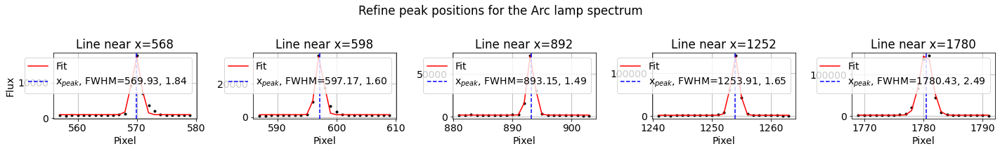

Converged at iteration 1


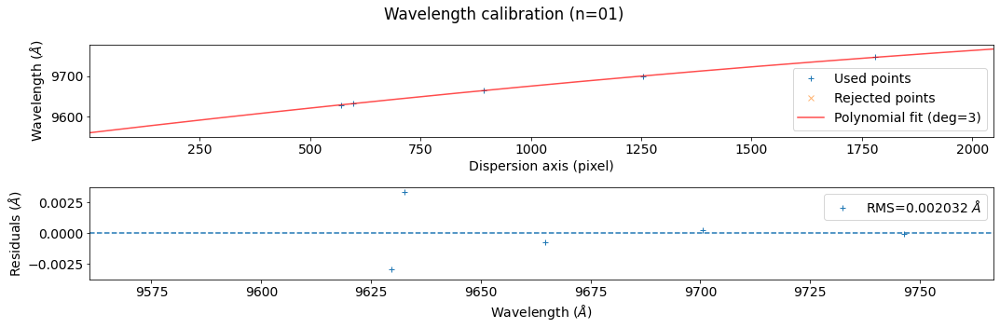

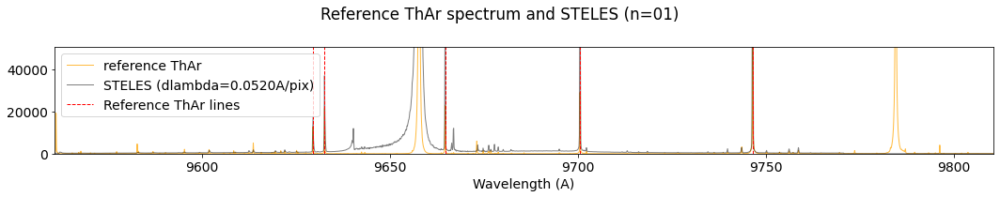

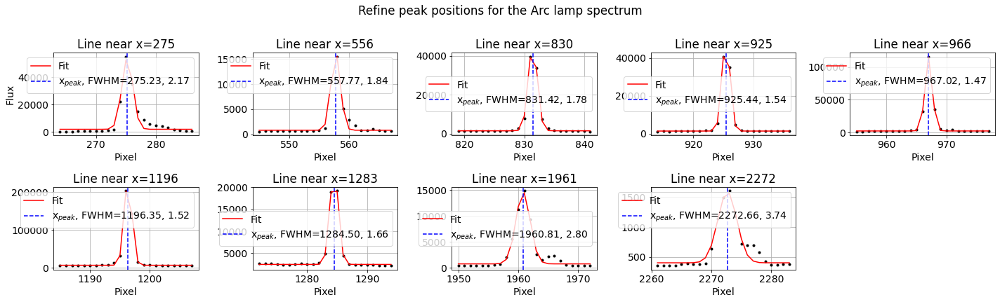

Converged at iteration 1


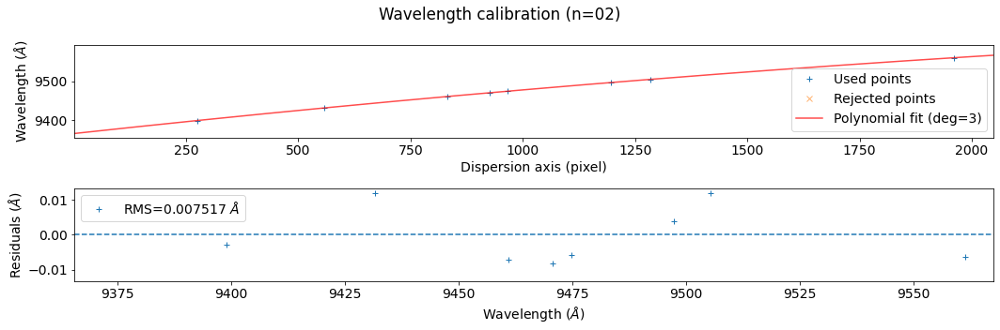

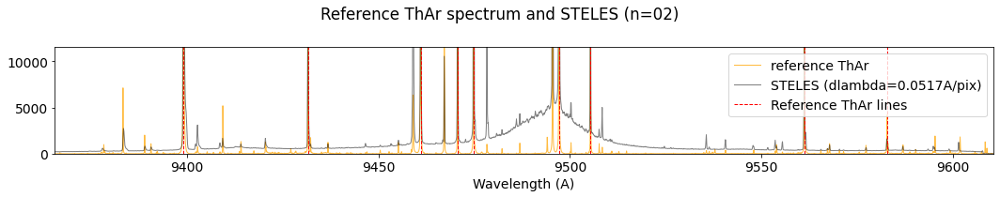

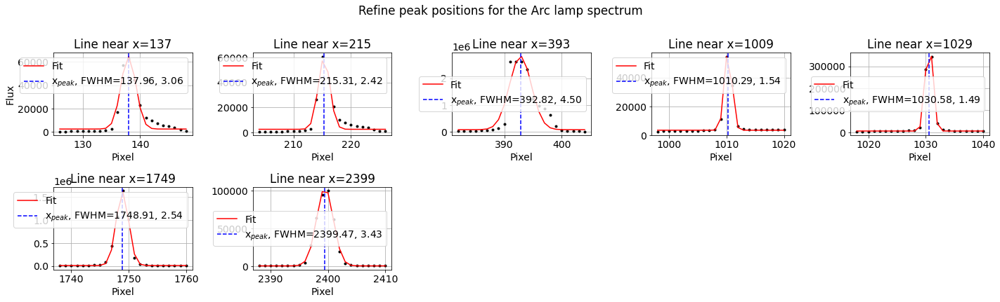

Converged at iteration 1


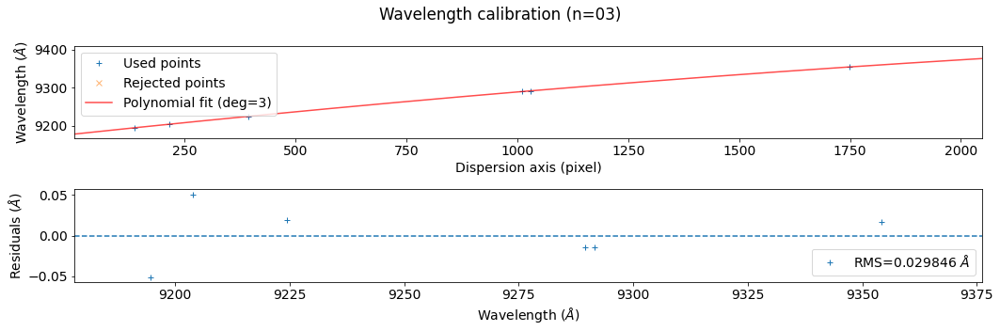

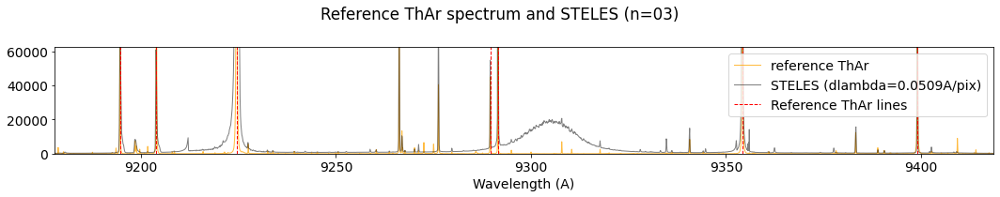

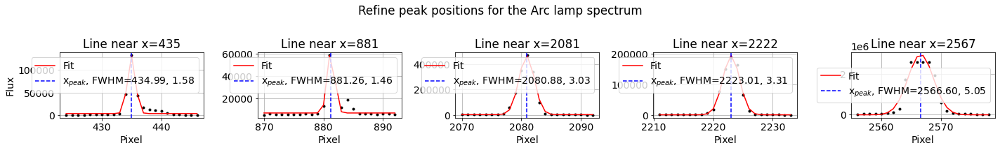

Converged at iteration 1


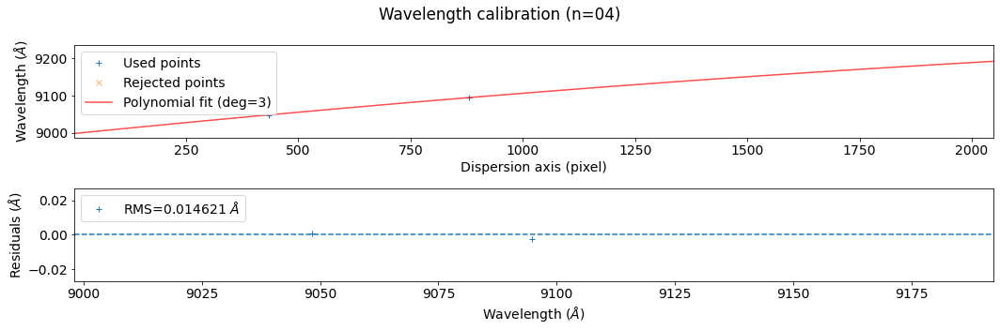

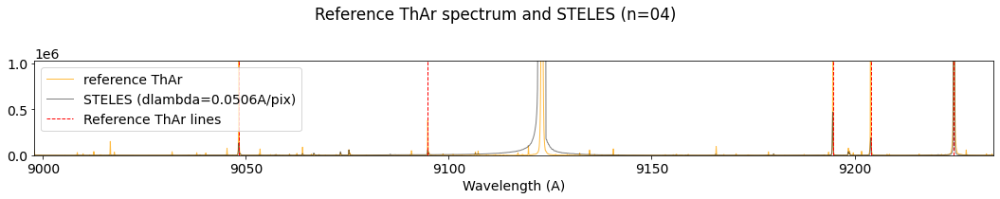

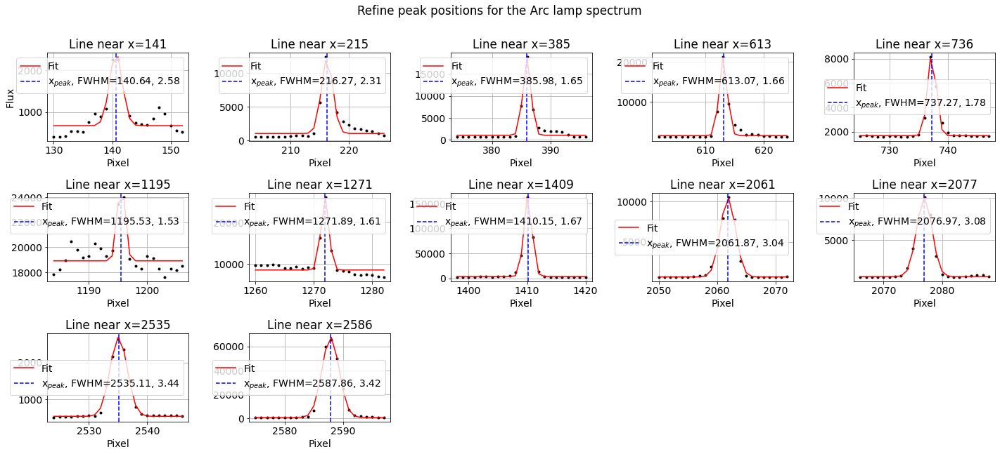

Converged at iteration 2


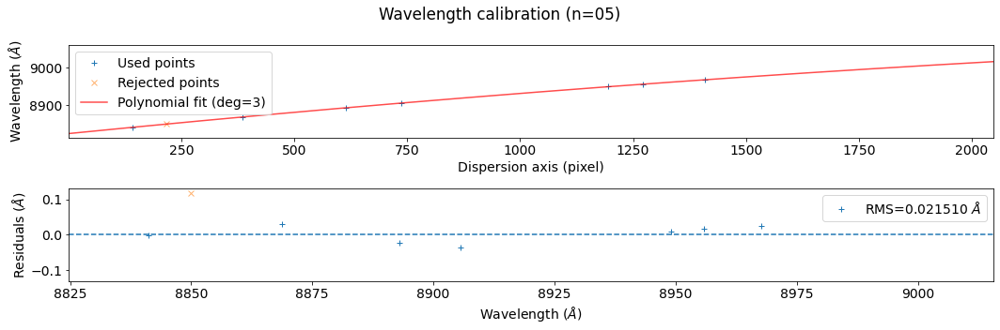

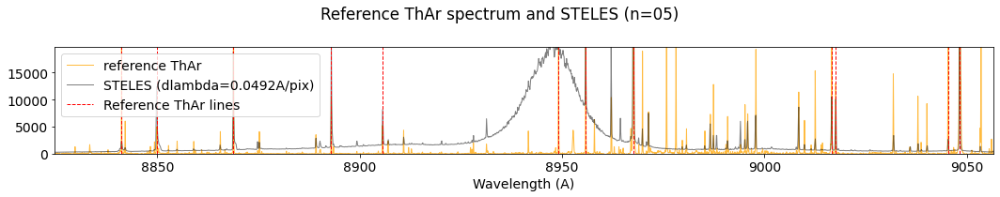

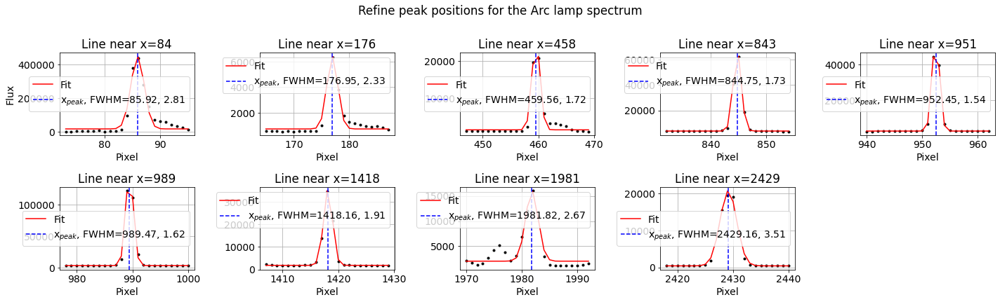

Converged at iteration 1


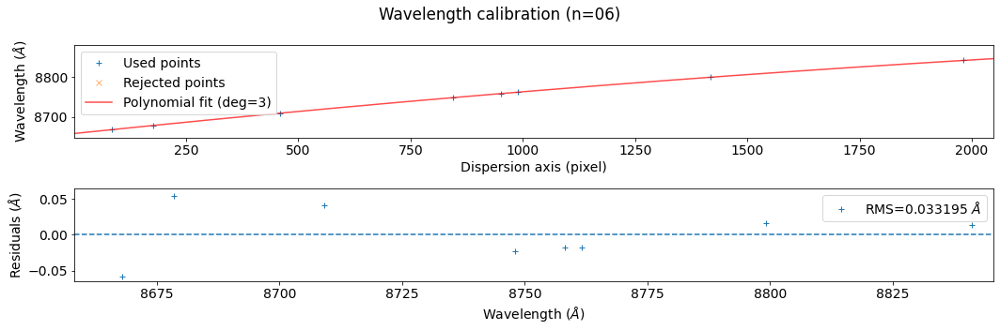

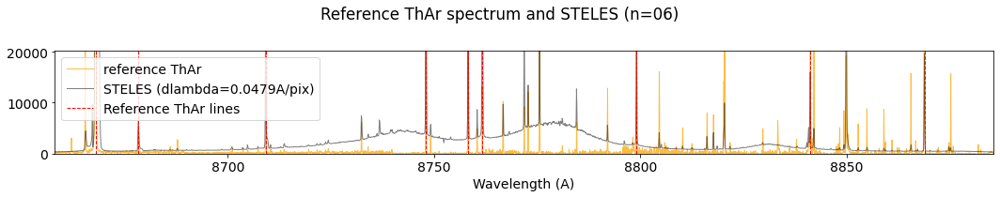

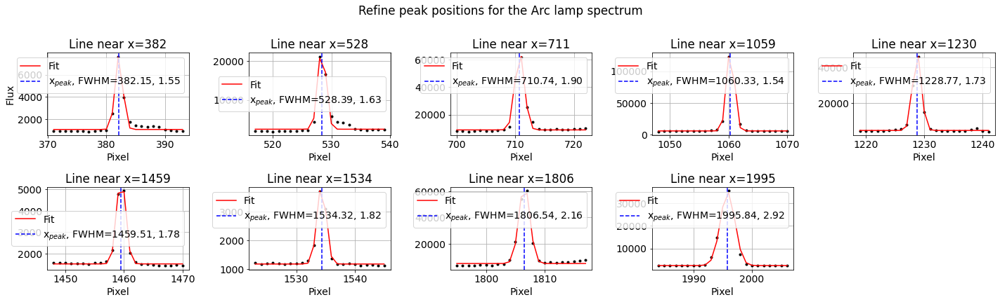

Converged at iteration 1


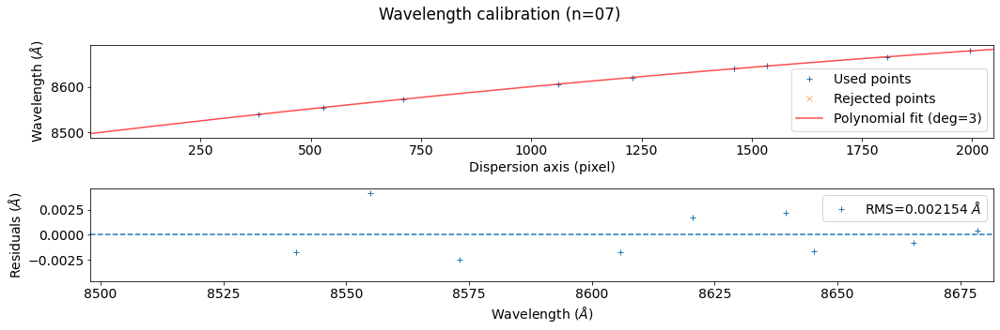

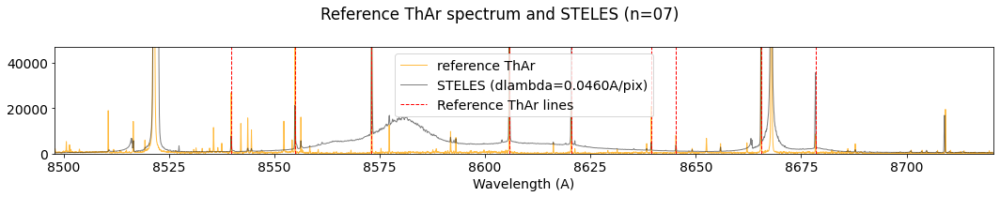

C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


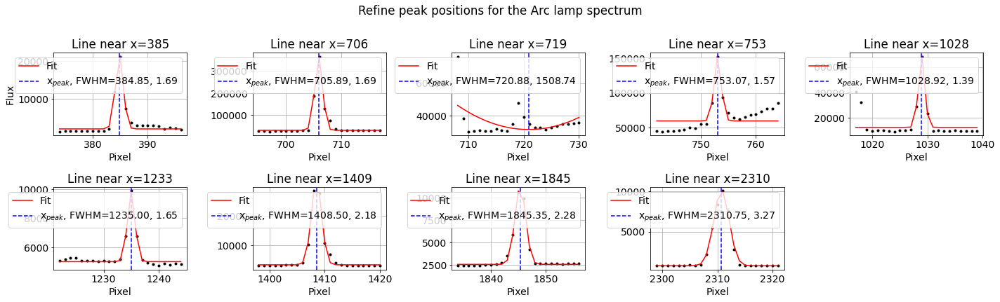

Converged at iteration 2


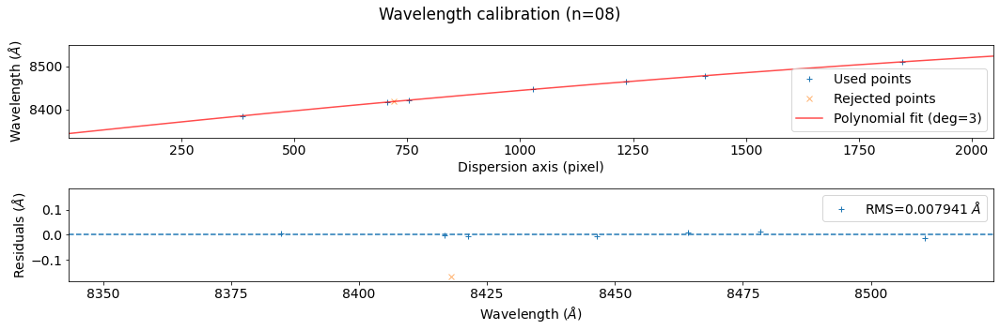

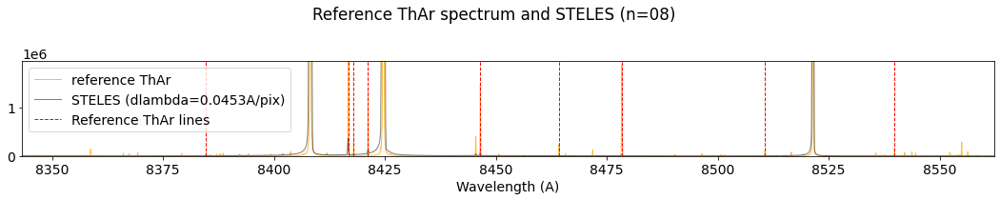

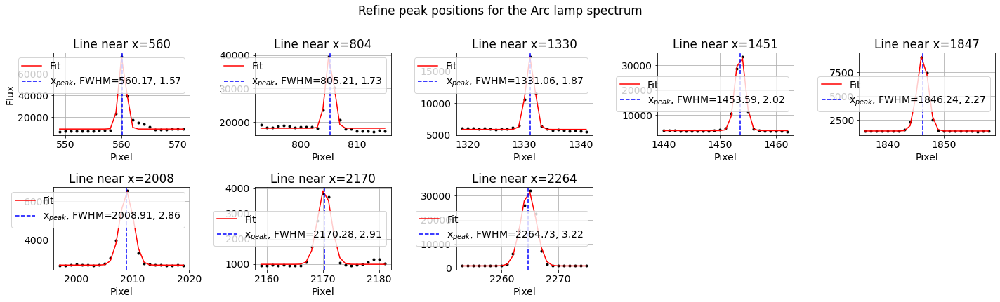

Converged at iteration 1


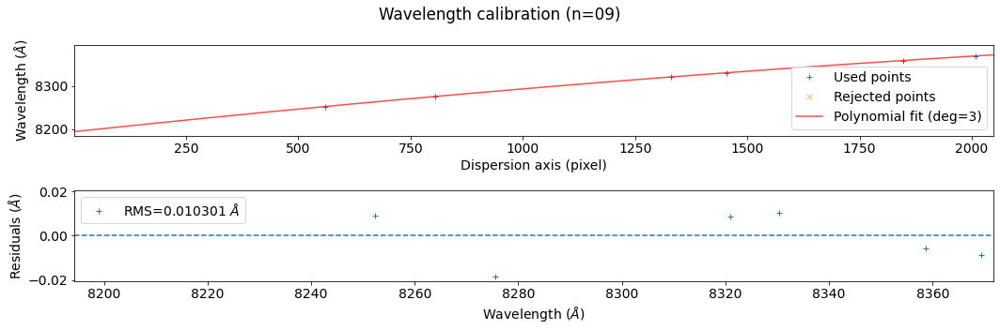

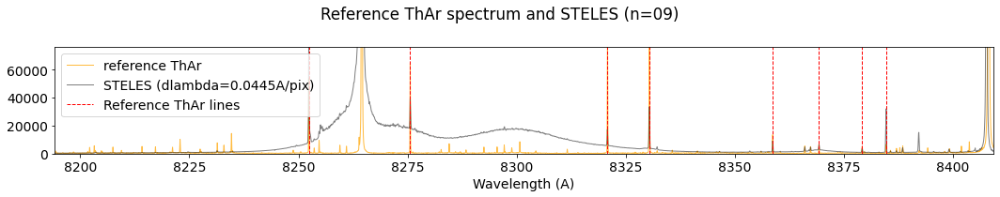

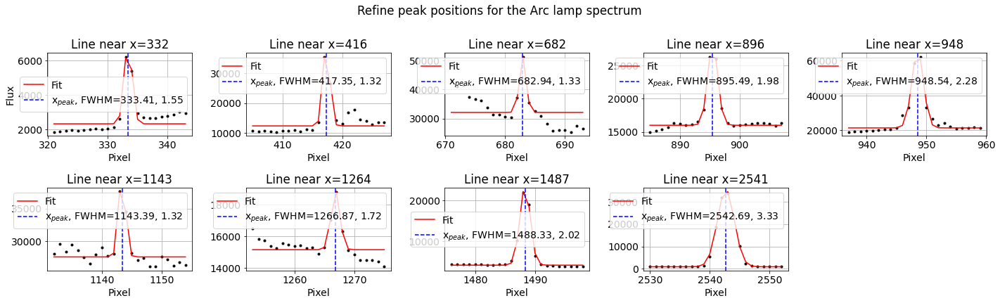

Converged at iteration 1


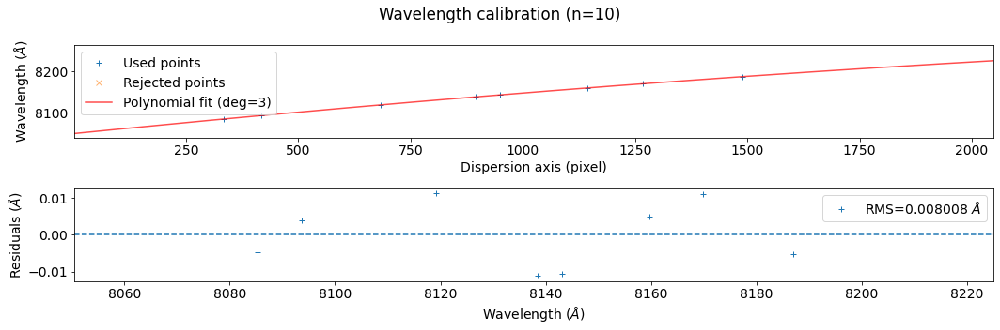

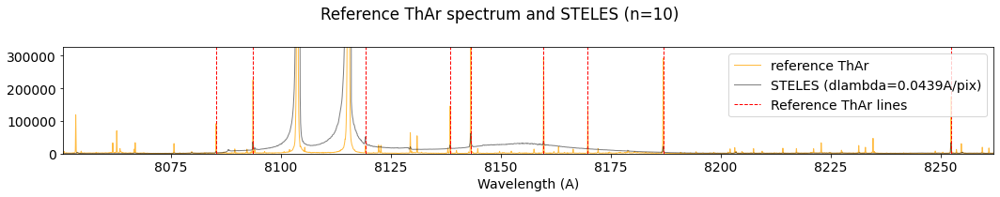

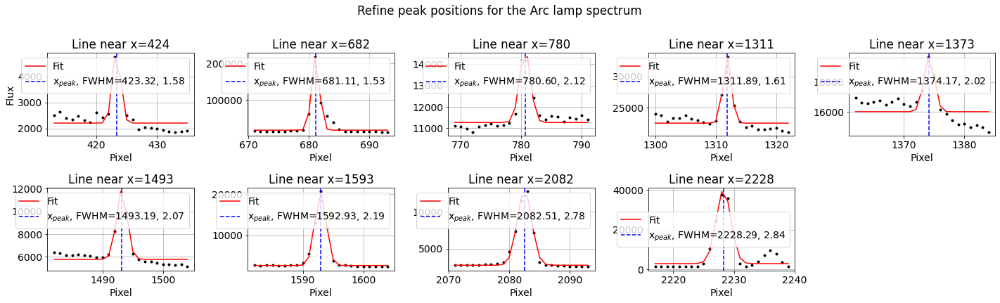

Converged at iteration 1


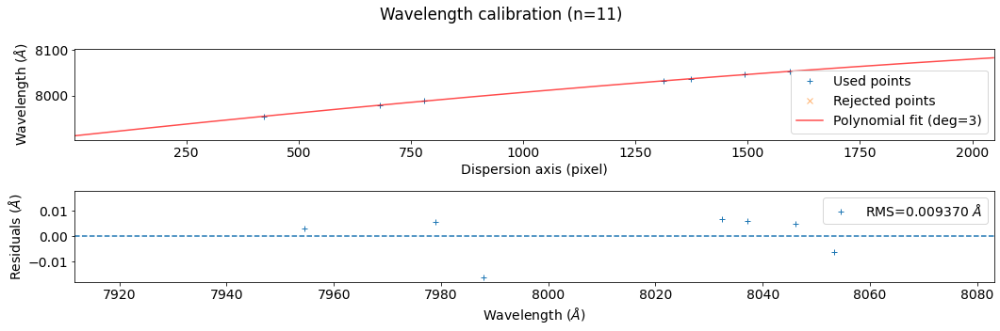

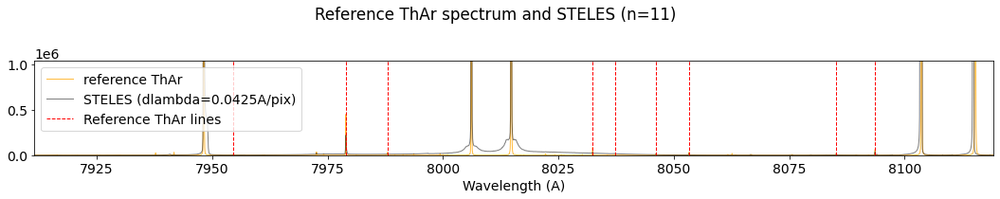

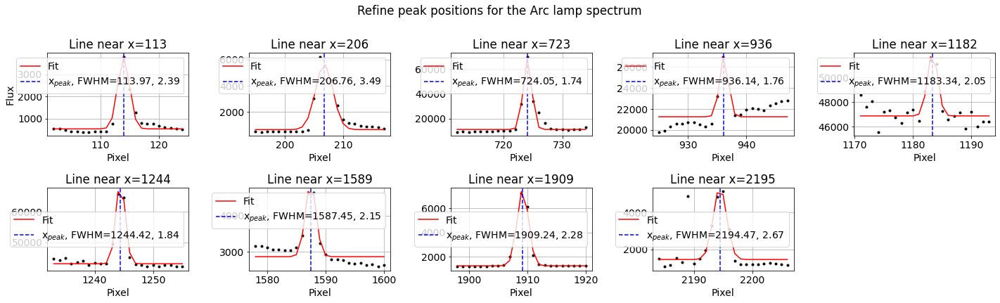

Converged at iteration 2


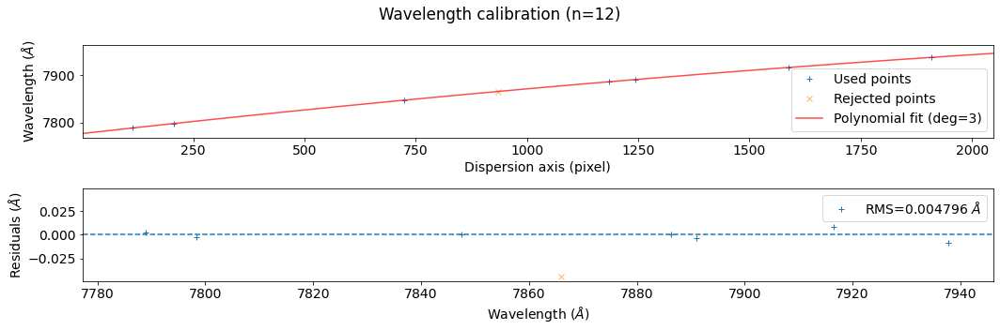

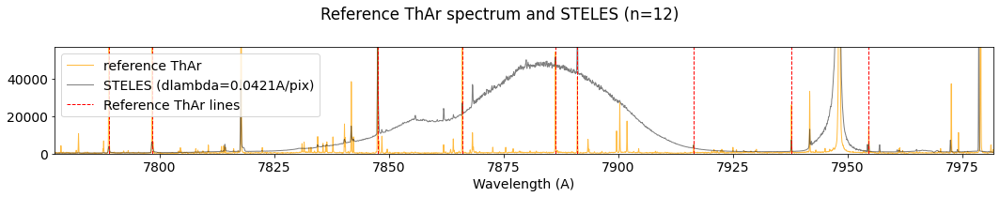

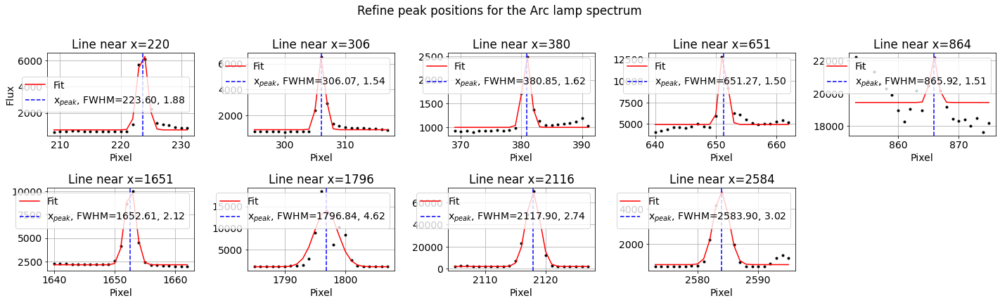

Converged at iteration 2


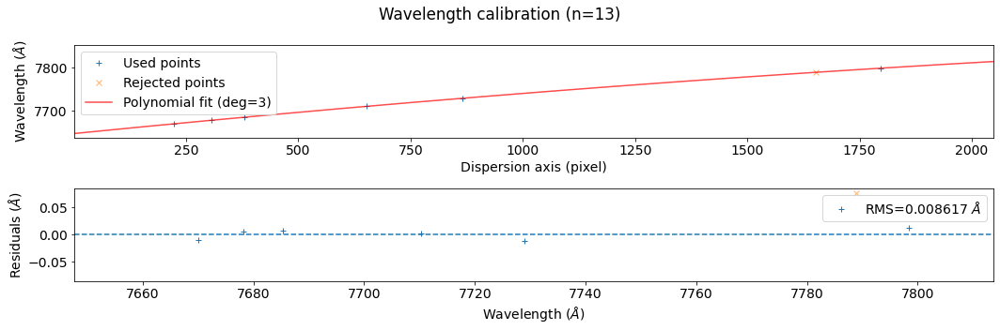

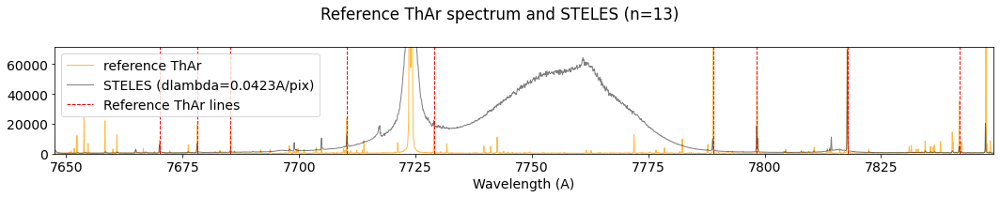

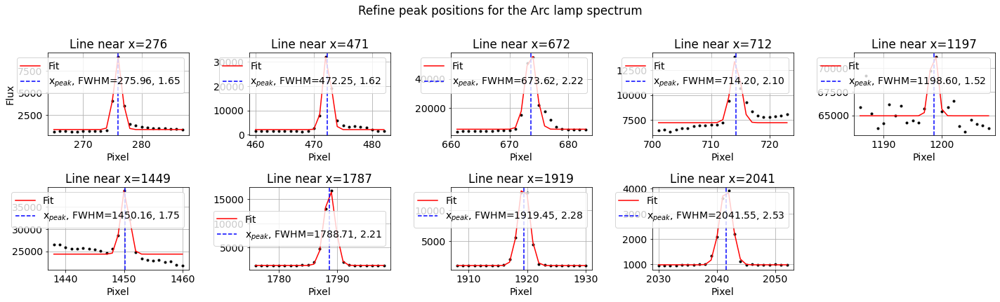

Converged at iteration 1


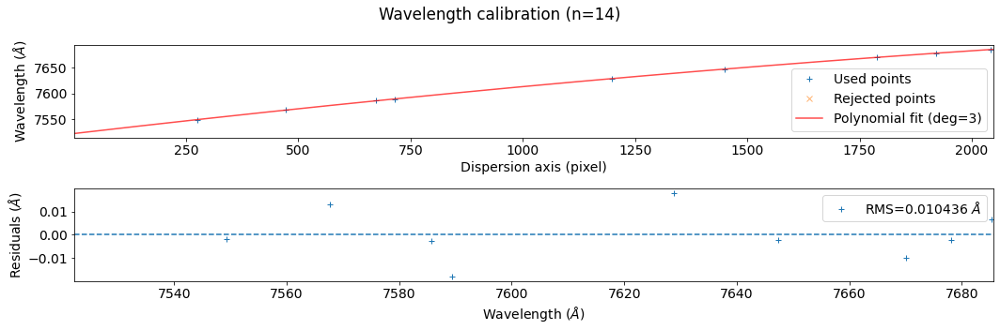

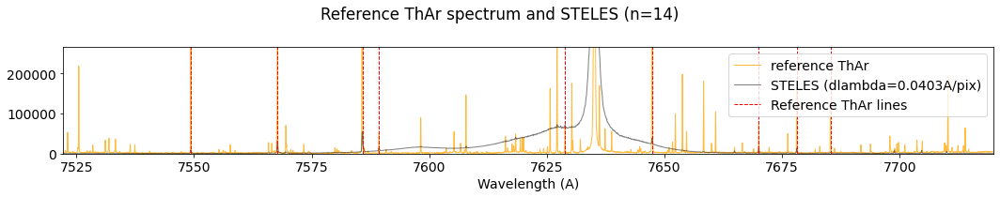

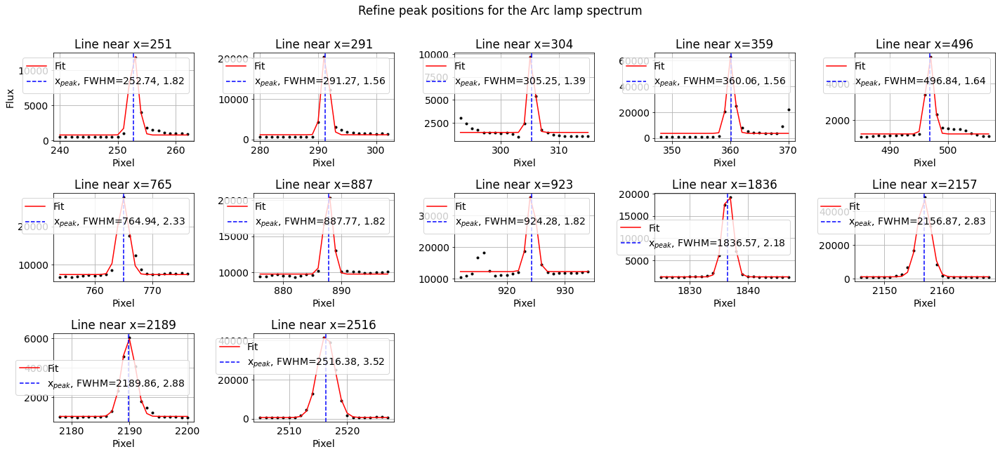

Converged at iteration 2


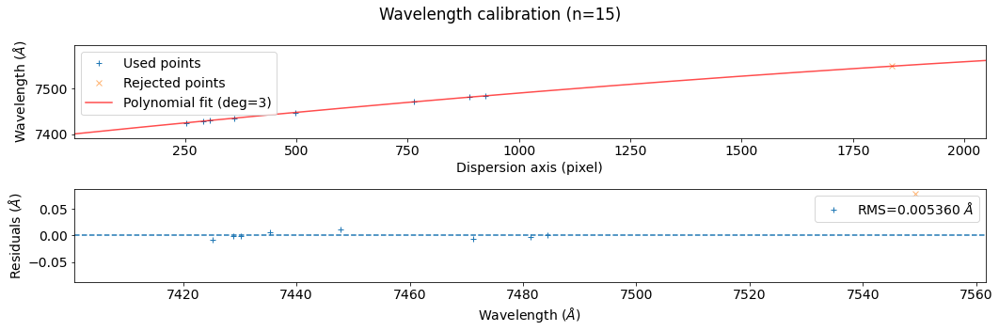

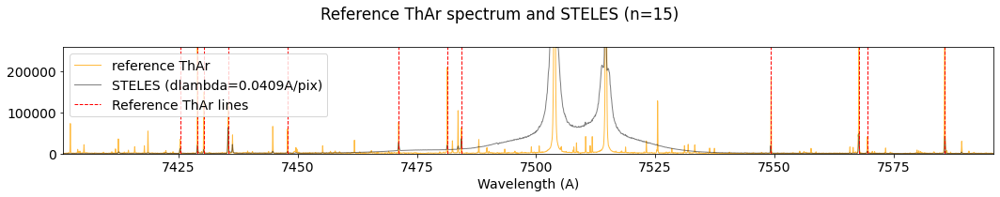

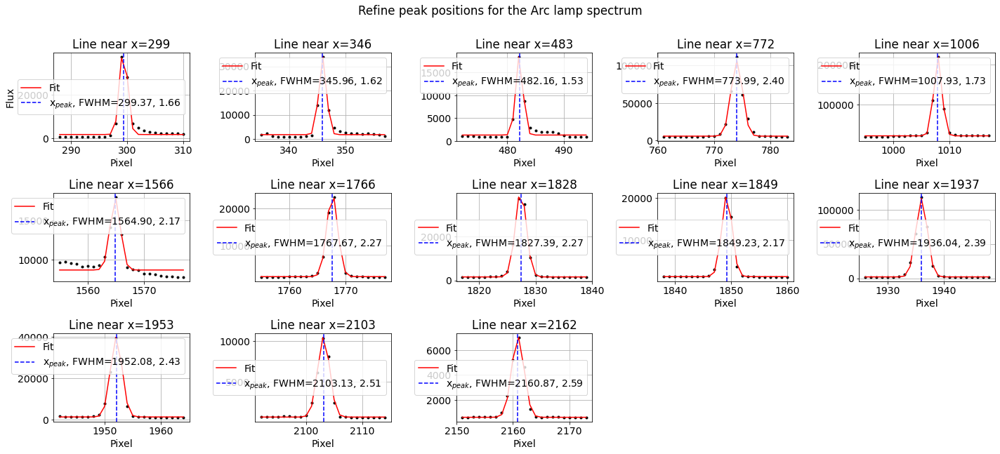

Converged at iteration 3


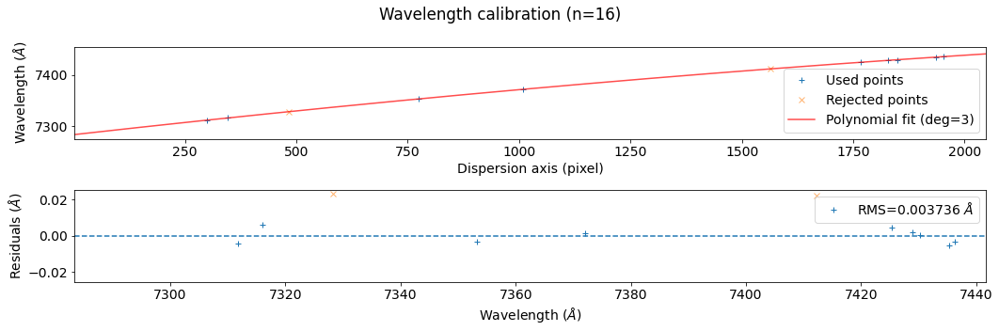

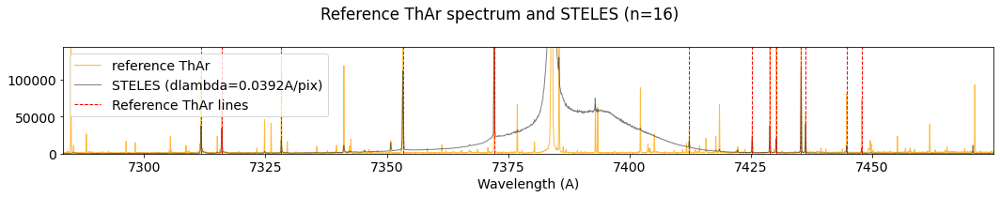

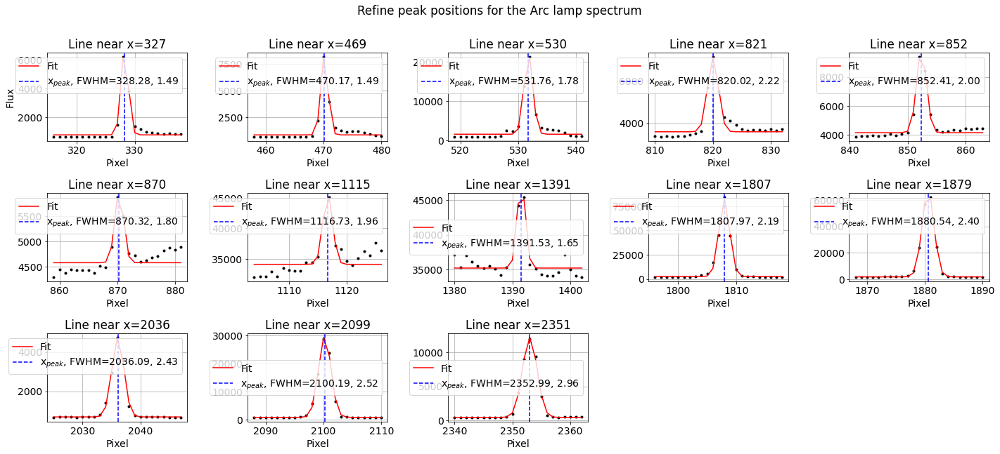

Converged at iteration 1


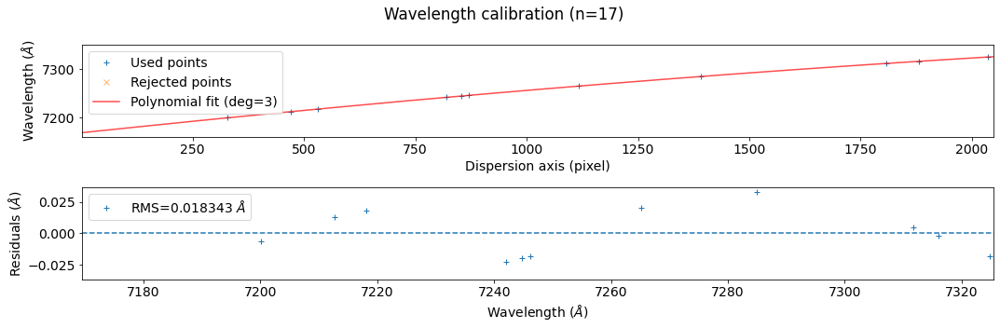

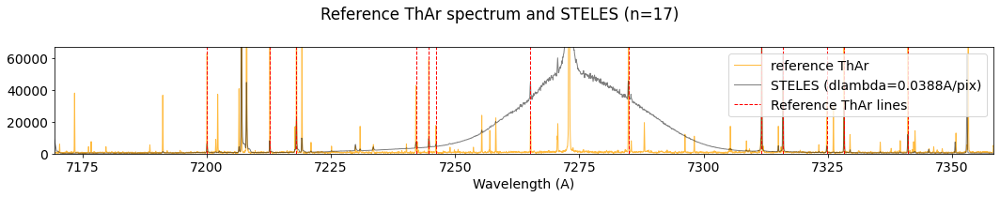

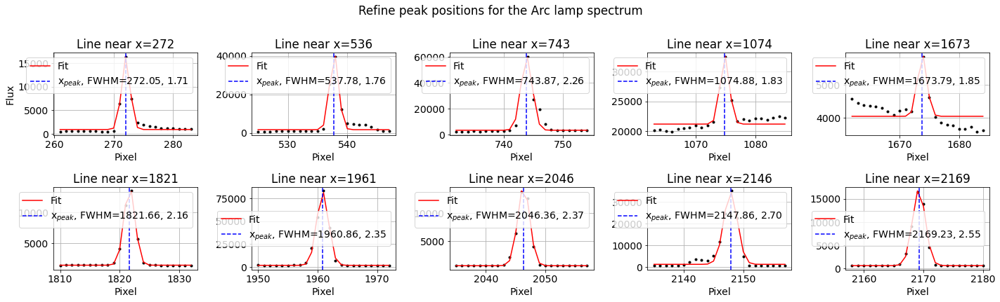

Converged at iteration 2


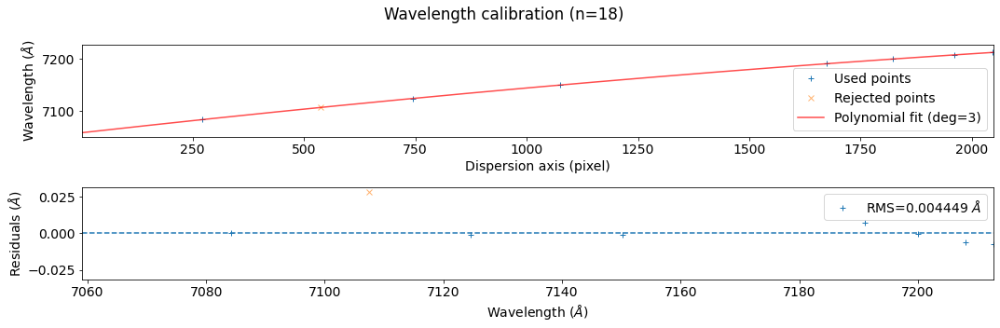

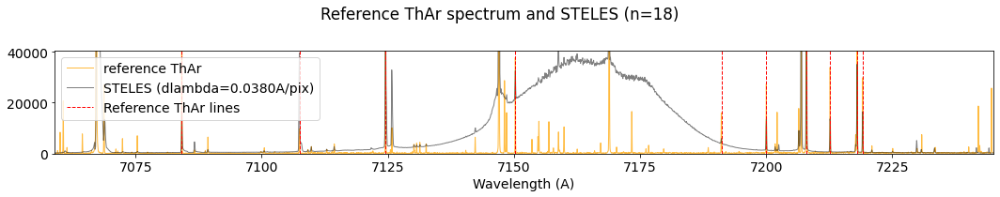

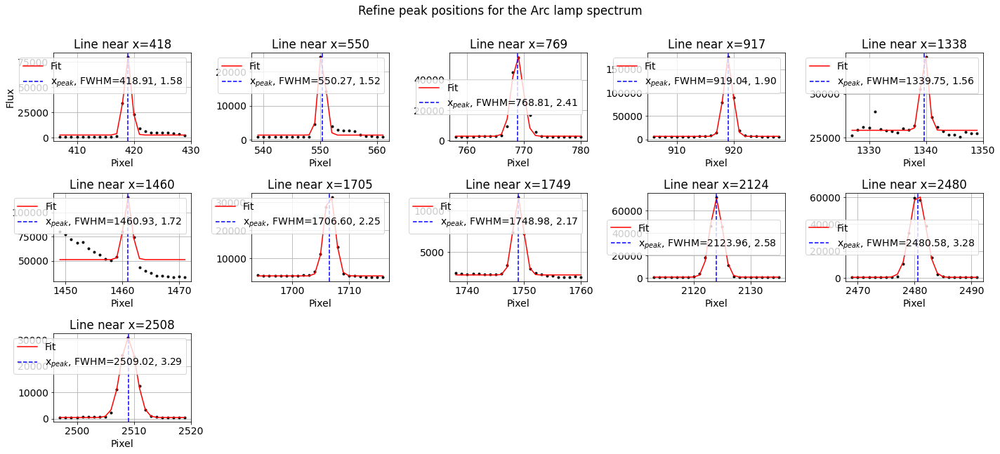

Converged at iteration 2


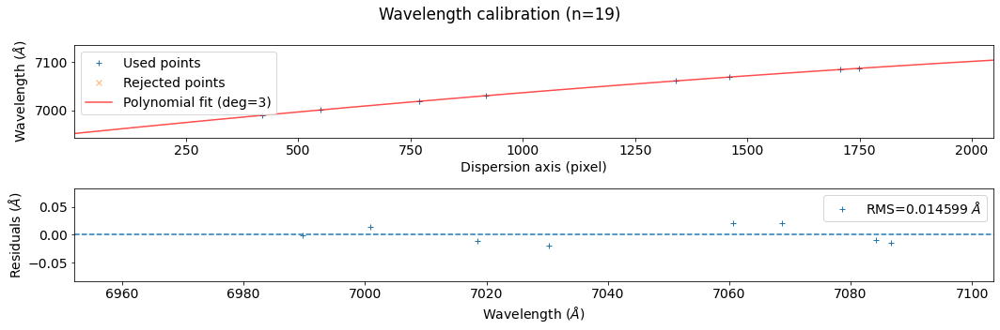

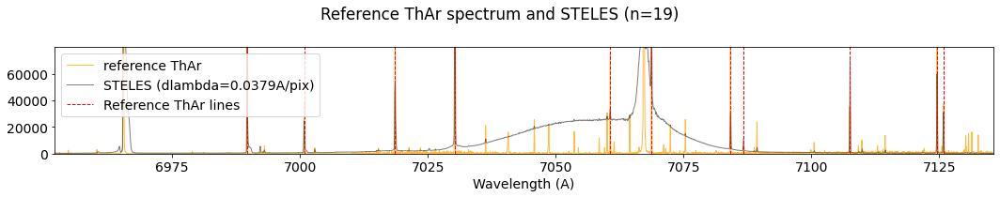

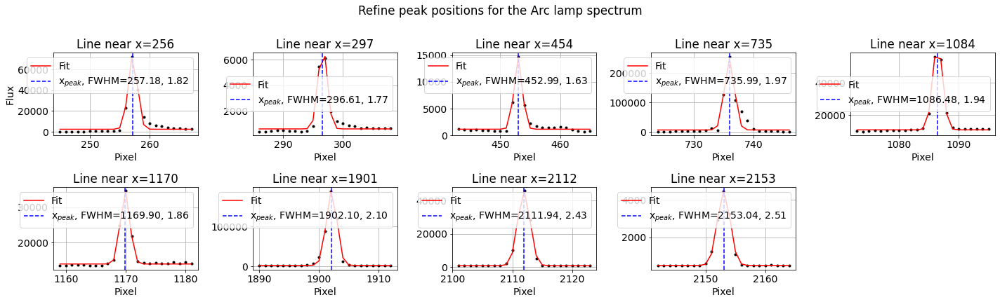

Converged at iteration 2


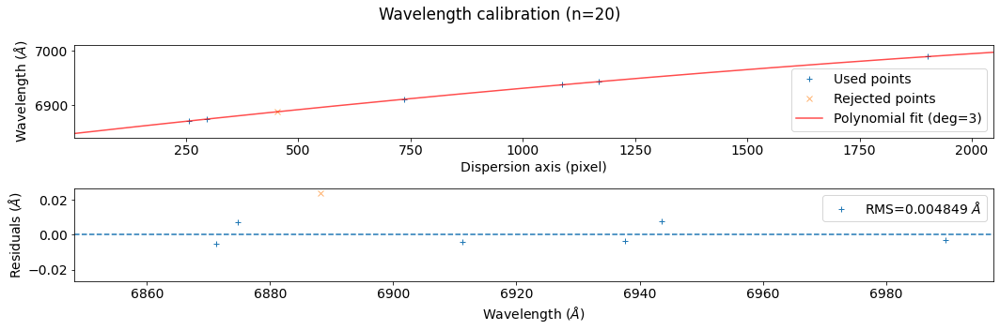

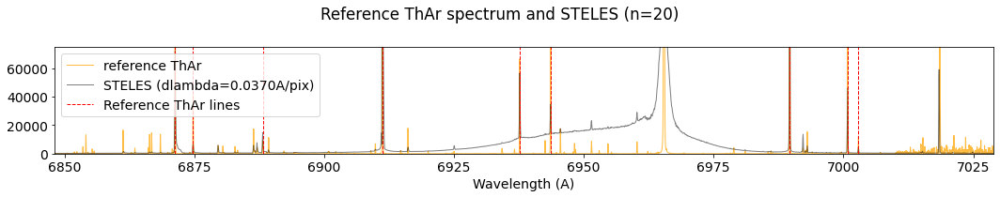

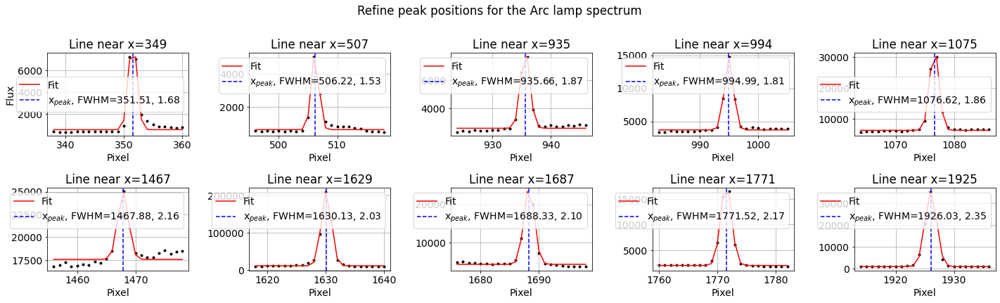

Converged at iteration 3


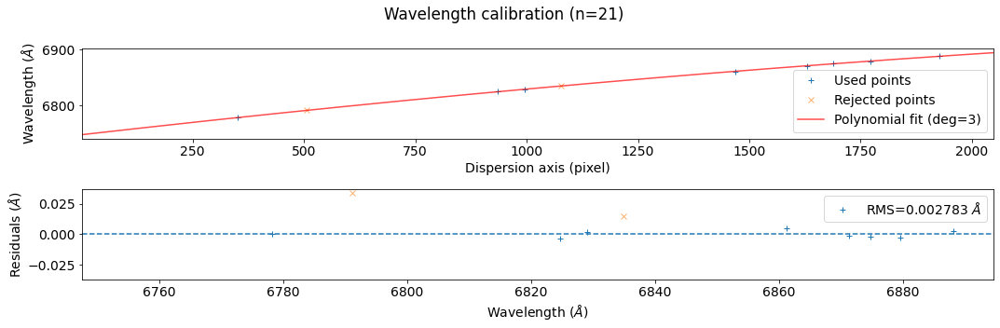

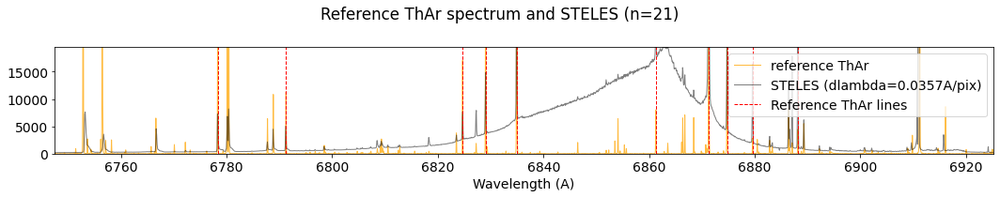

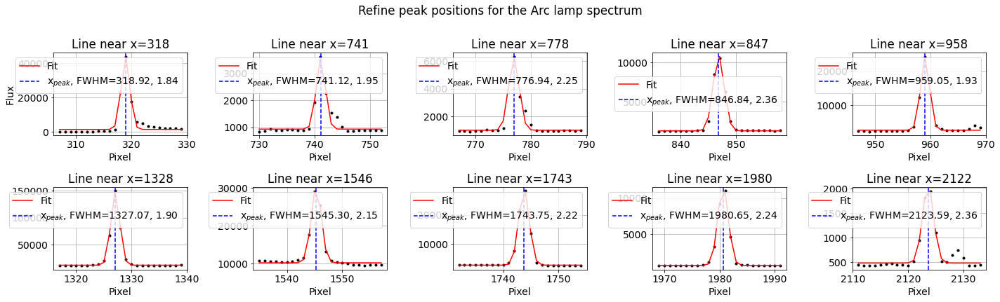

Converged at iteration 3


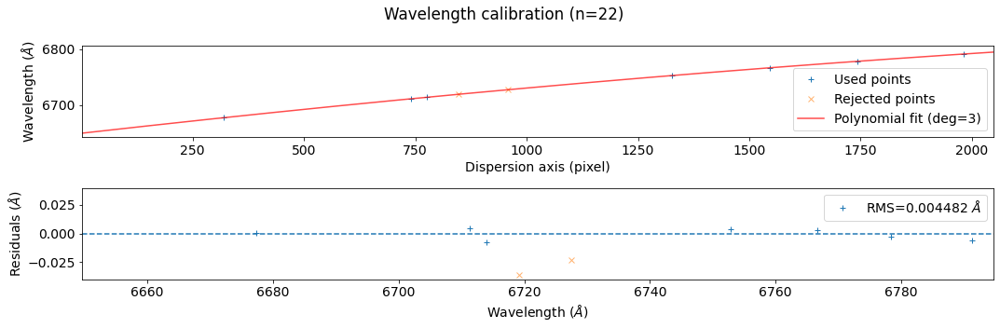

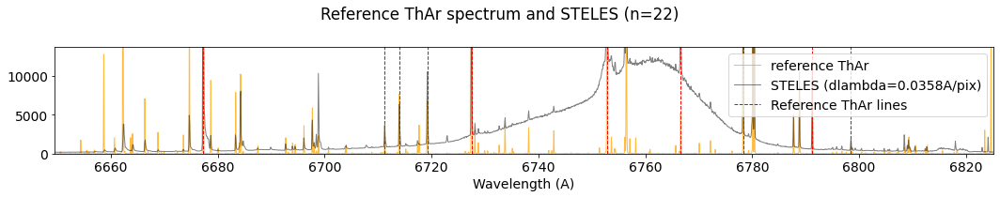

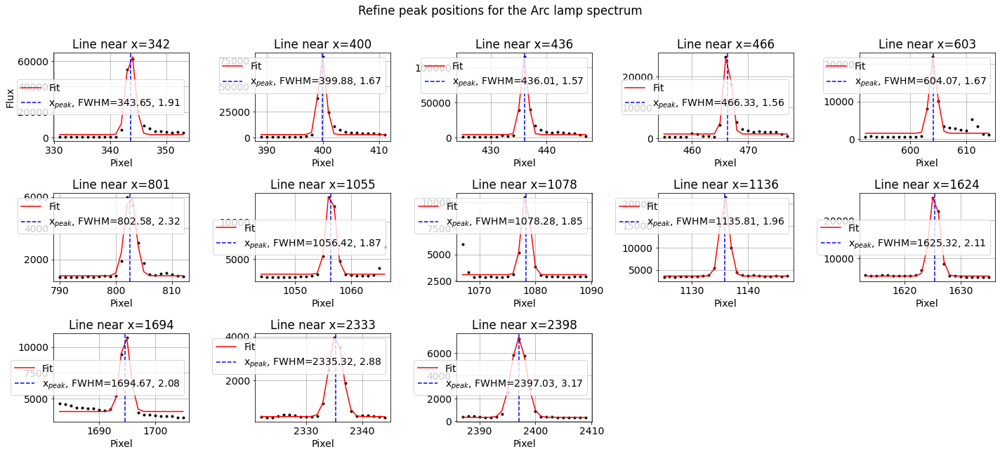

Converged at iteration 2


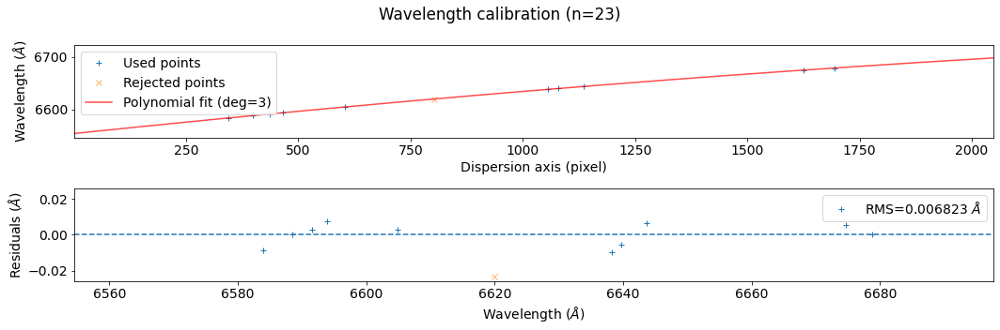

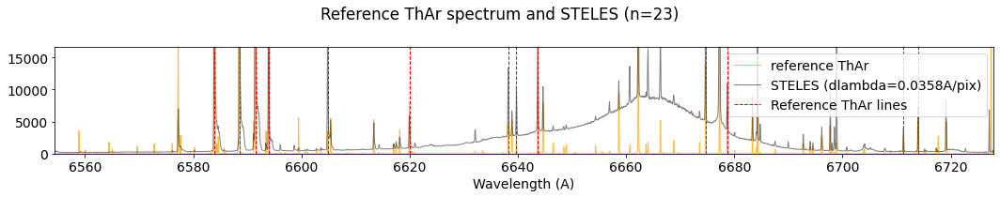

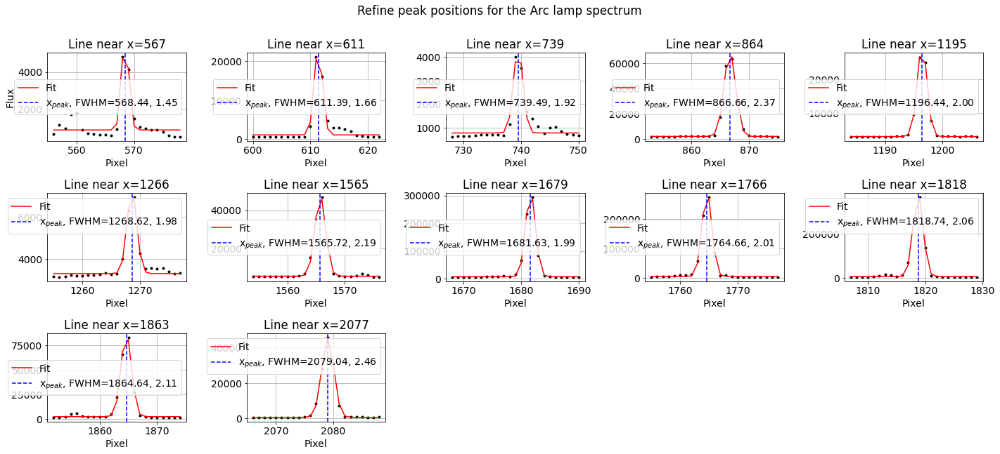

Converged at iteration 3


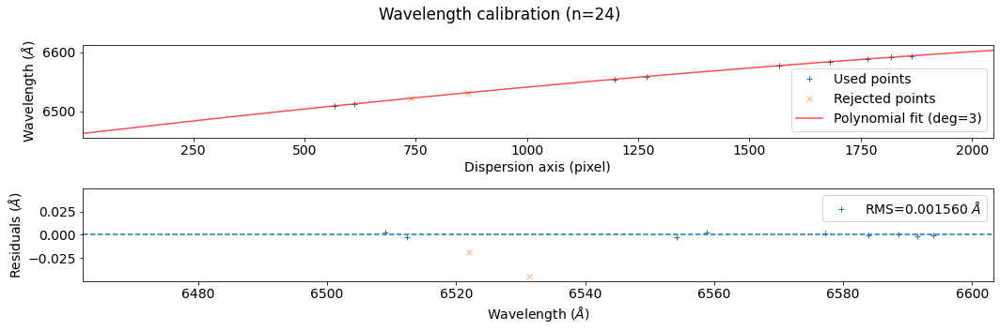

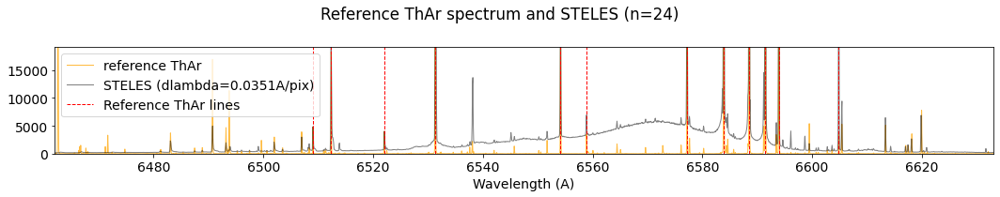

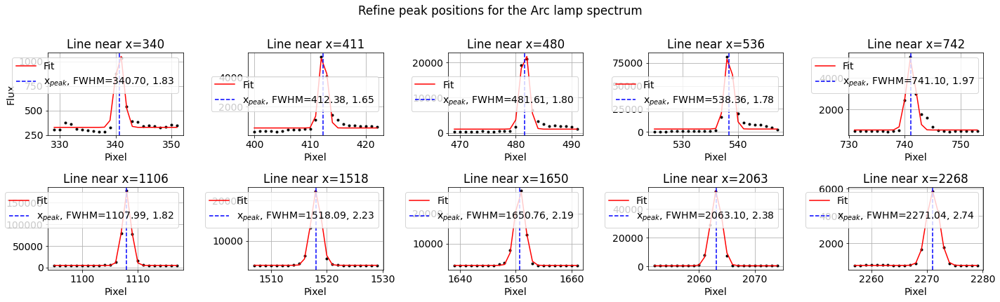

Converged at iteration 1


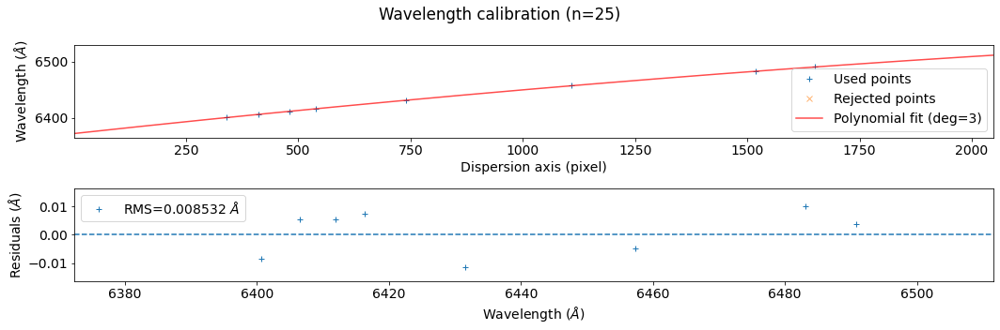

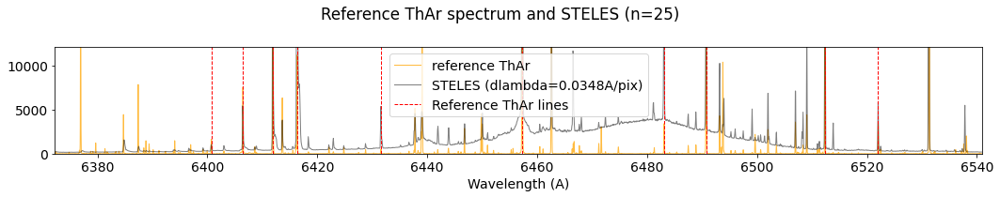

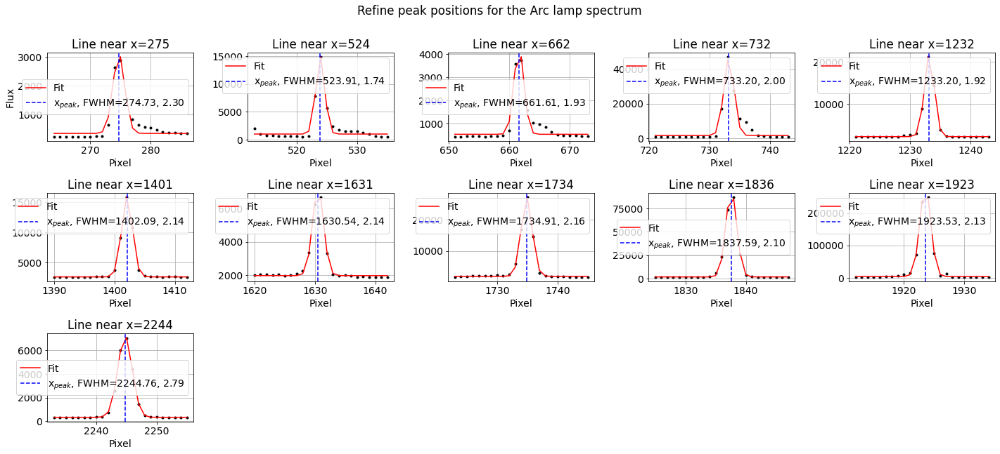

Converged at iteration 3


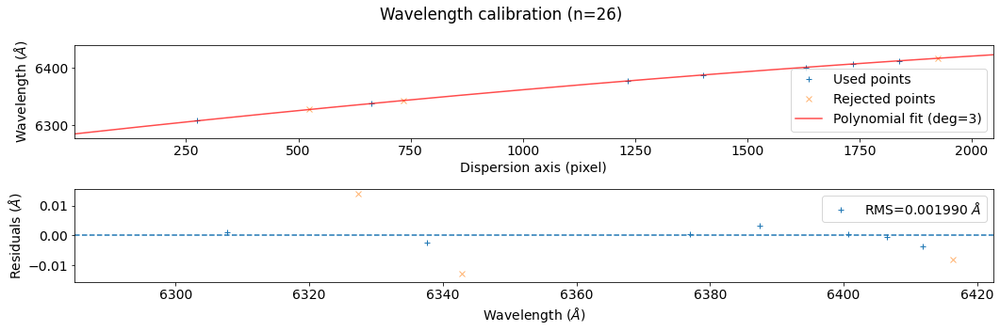

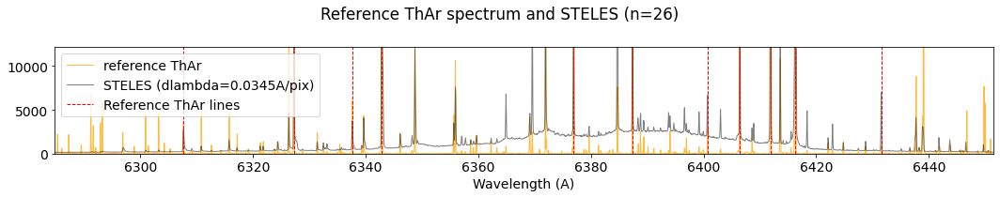

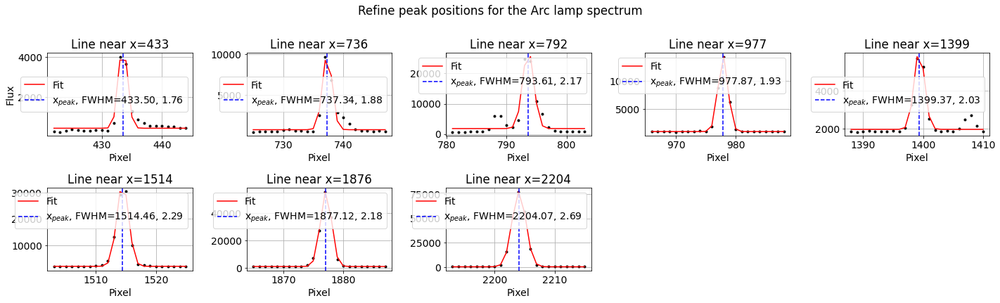

Converged at iteration 1


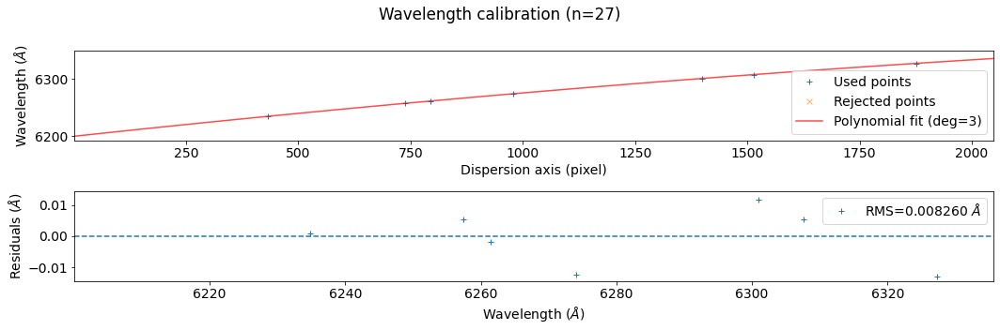

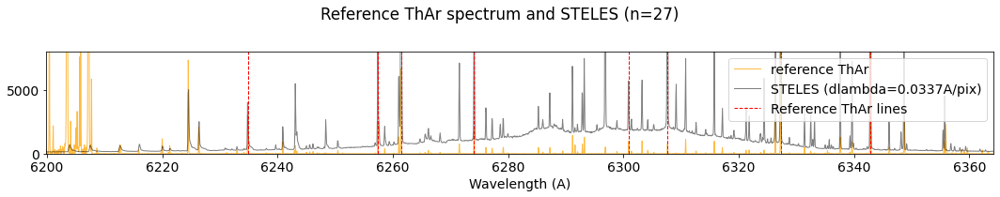

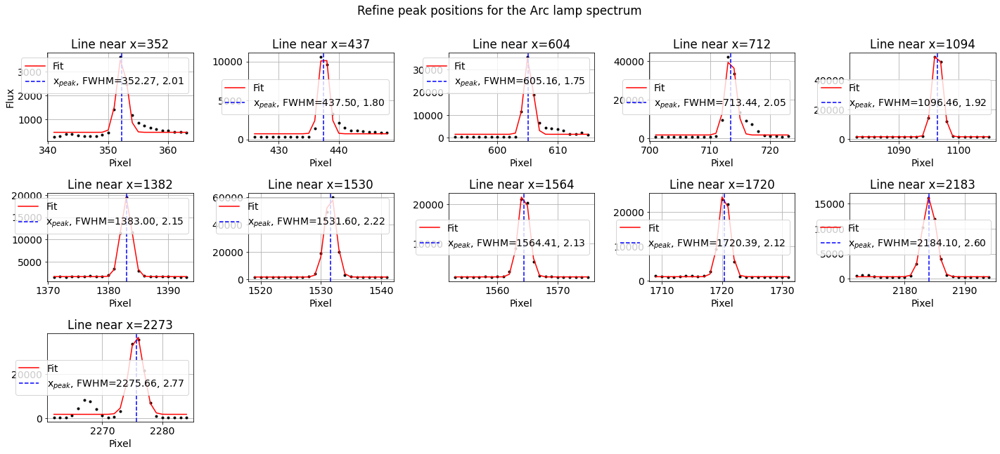

Converged at iteration 1


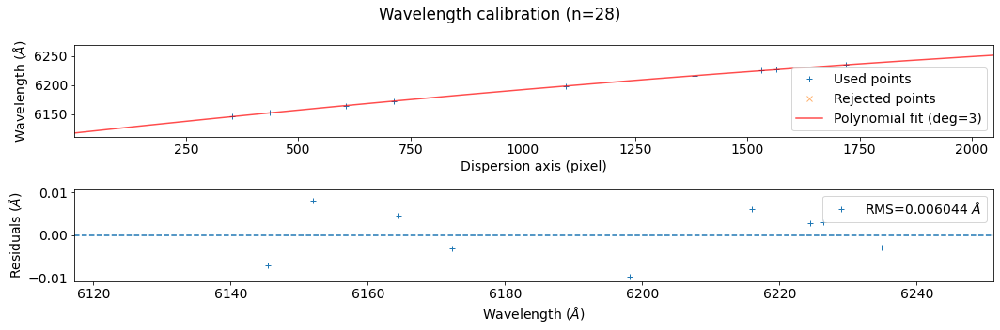

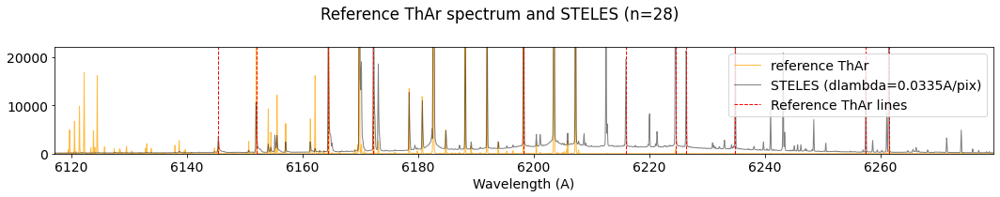

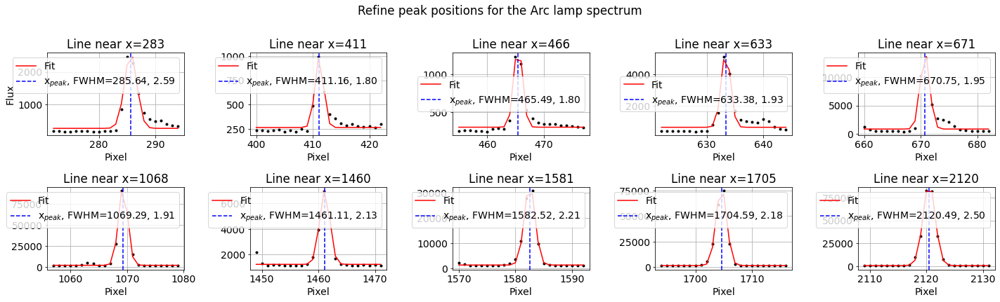

Converged at iteration 1


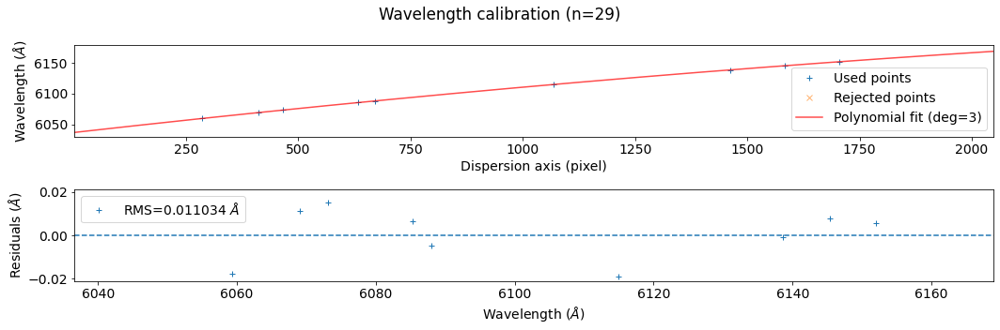

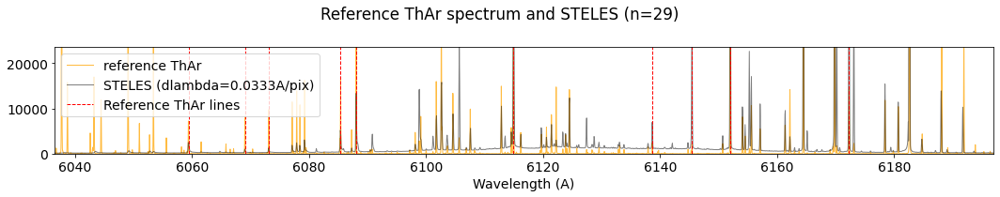

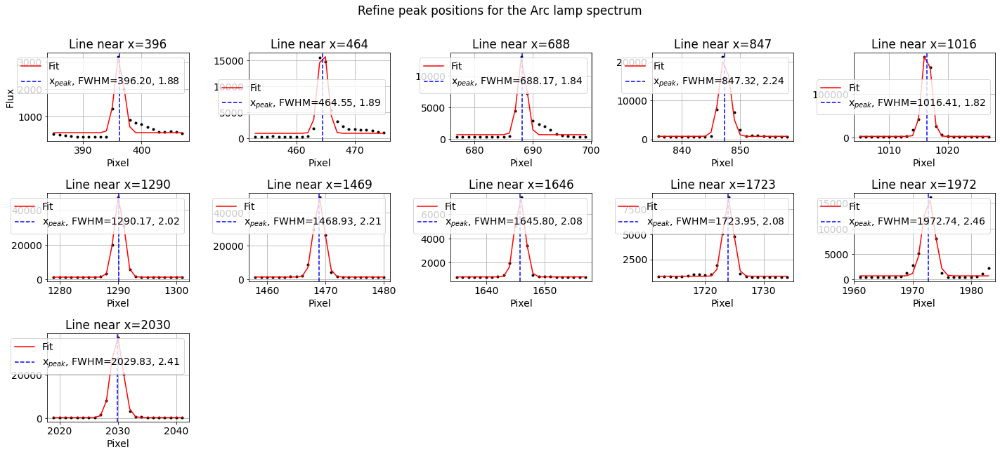

Converged at iteration 1


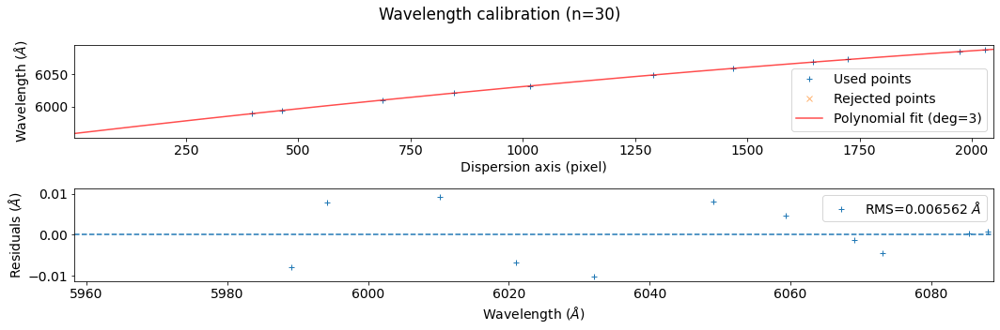

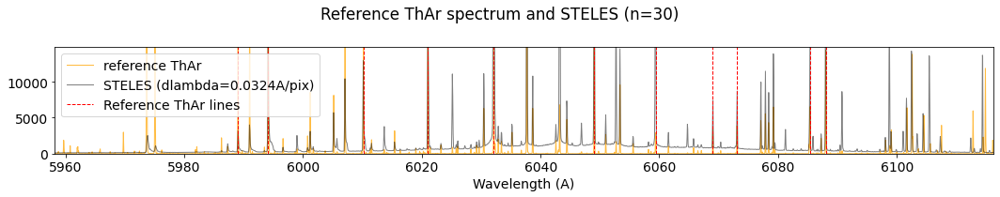

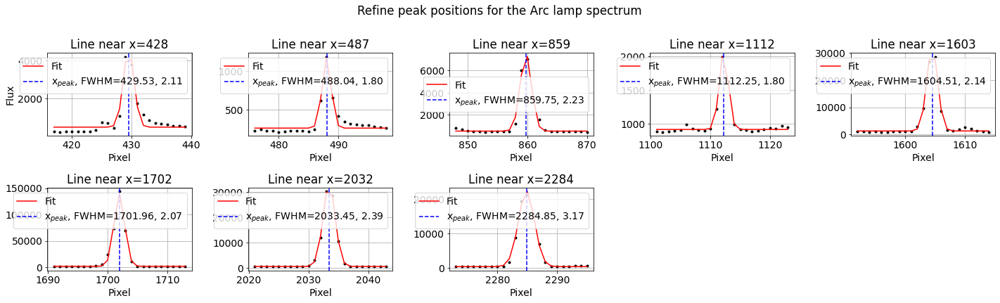

Converged at iteration 1


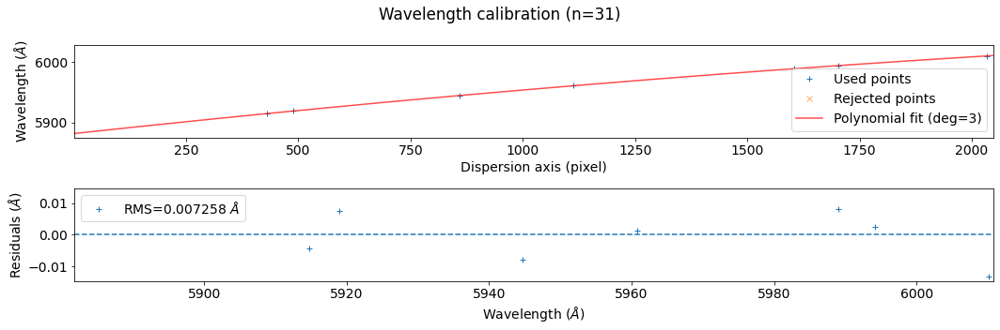

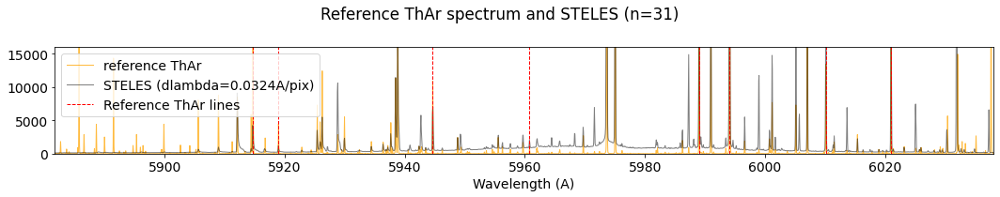

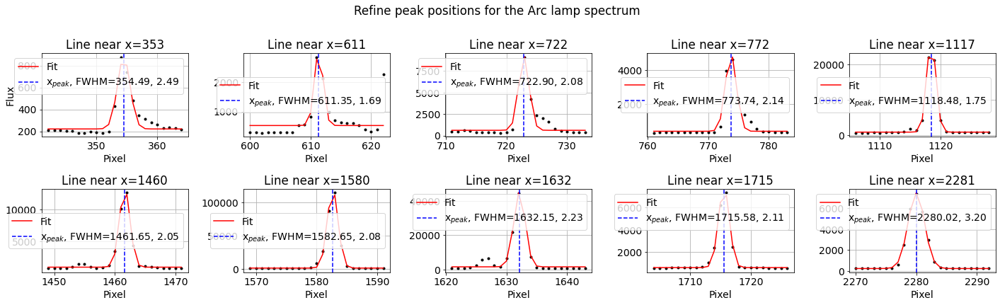

Converged at iteration 2


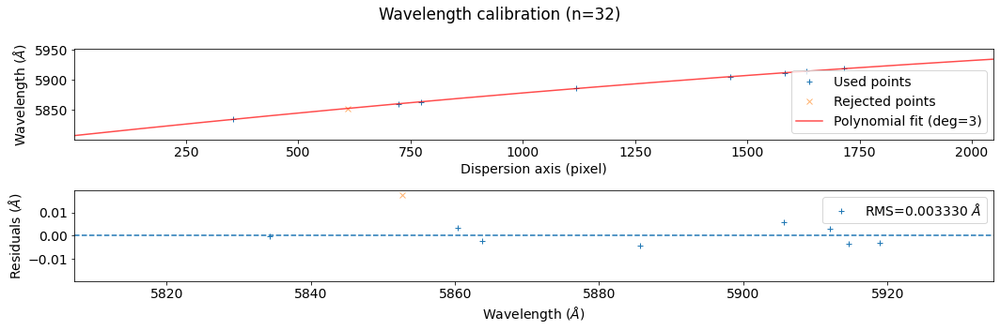

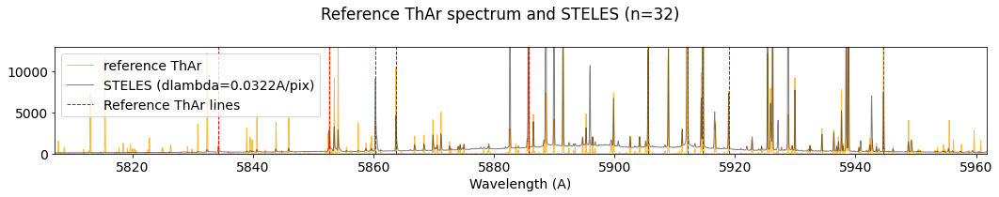

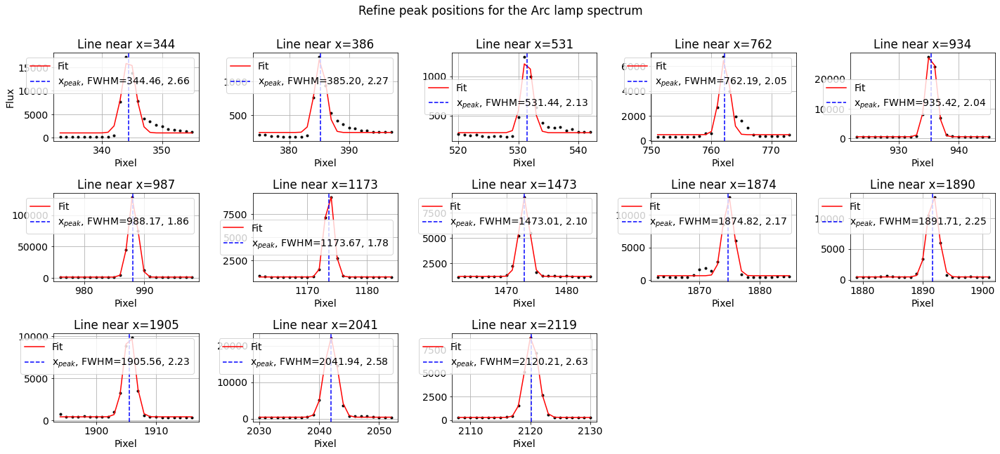

Converged at iteration 1


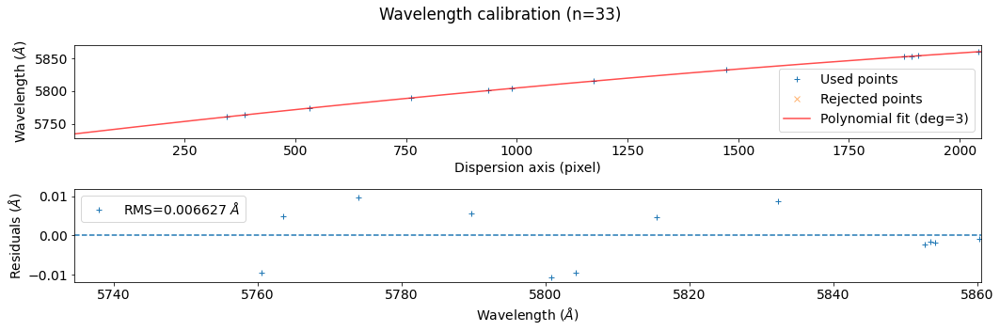

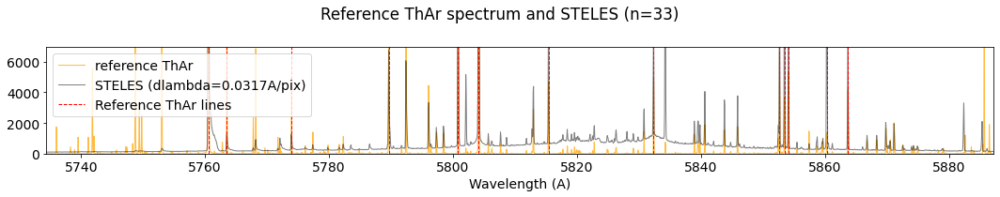

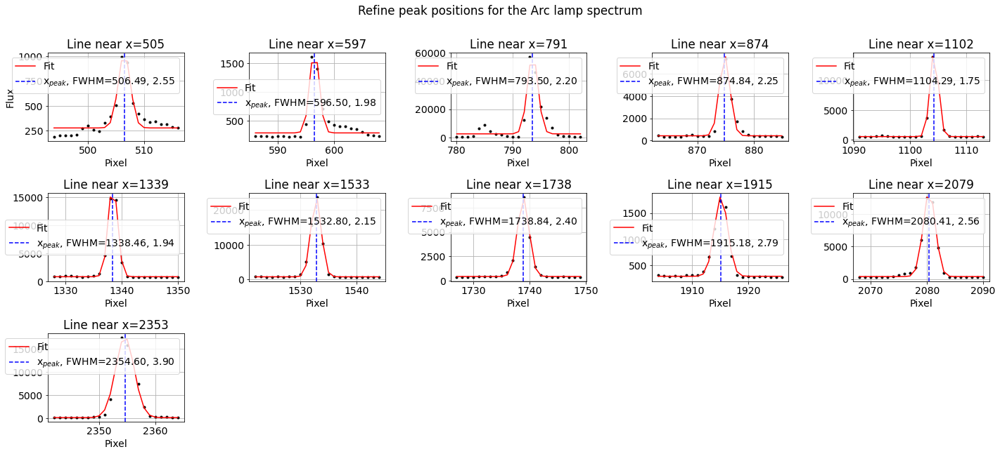

Converged at iteration 1


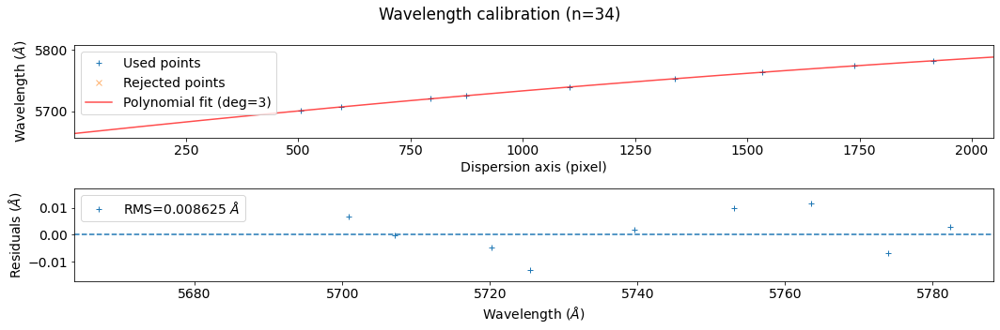

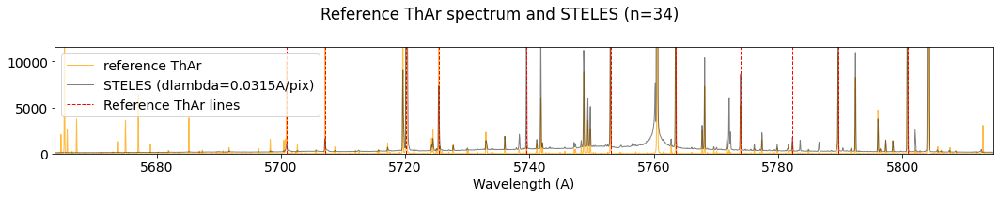

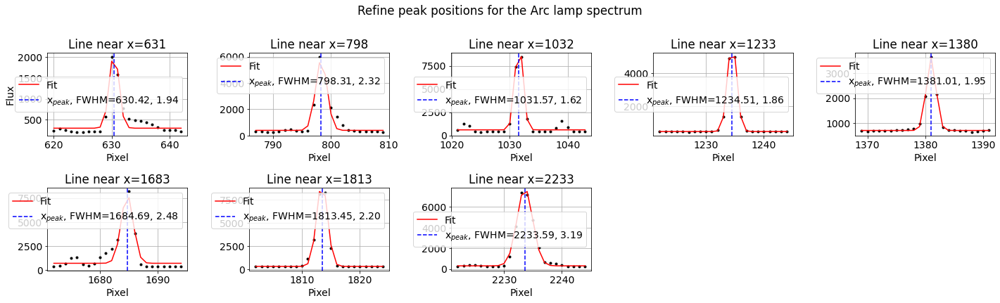

Converged at iteration 1


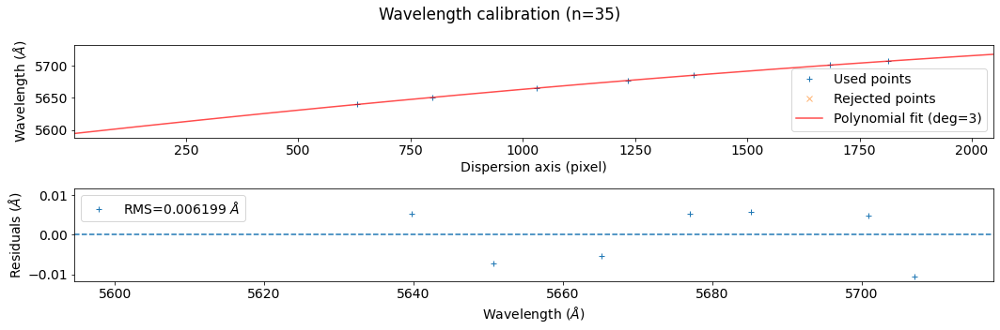

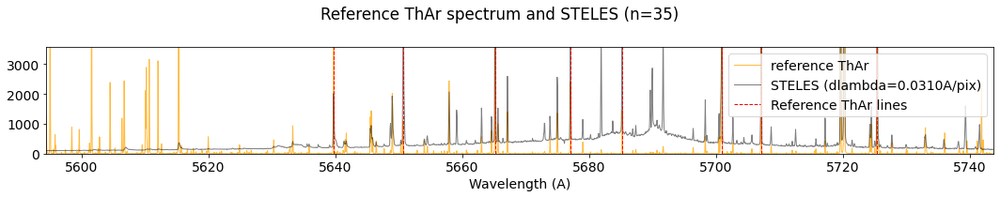

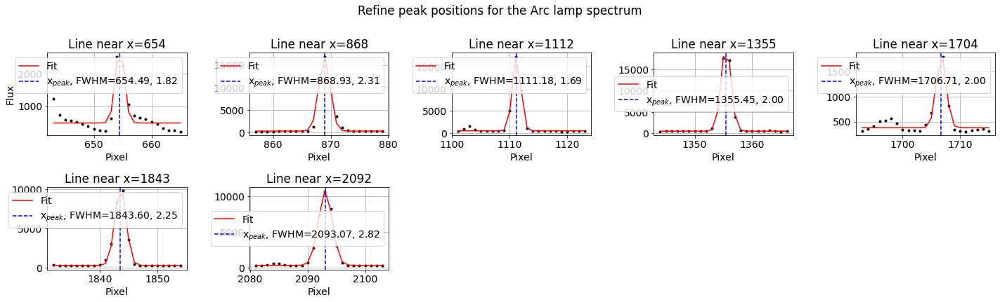

Converged at iteration 1


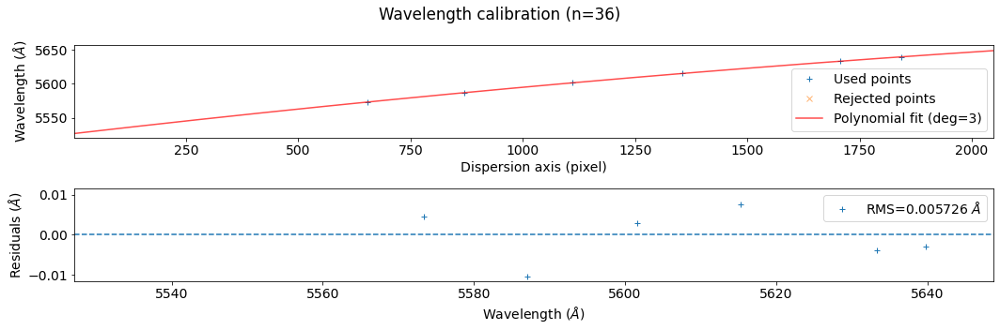

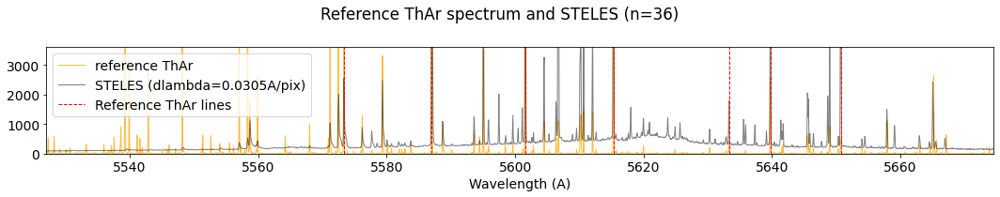

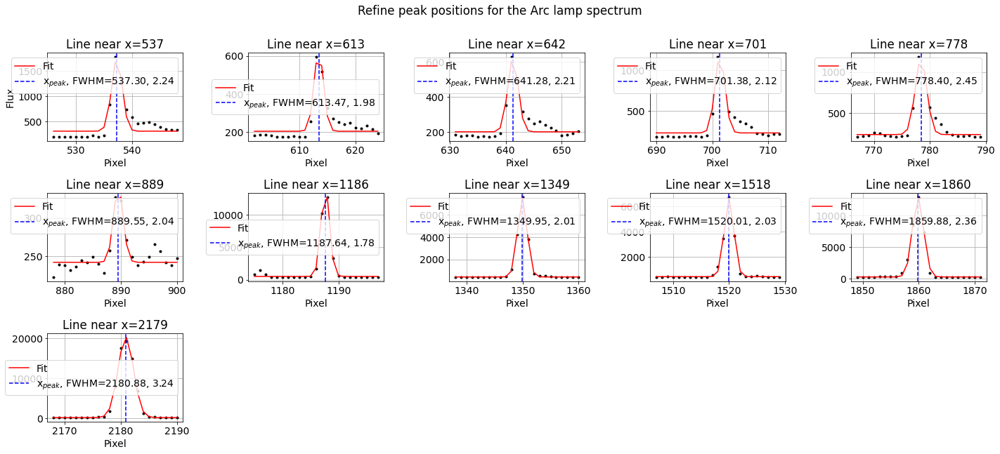

Converged at iteration 1


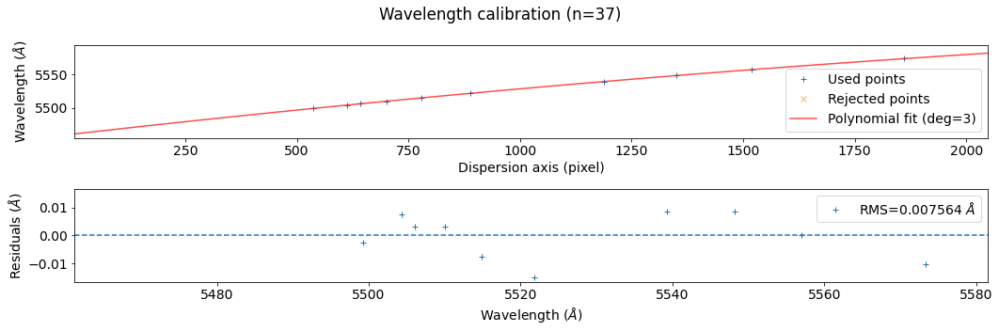

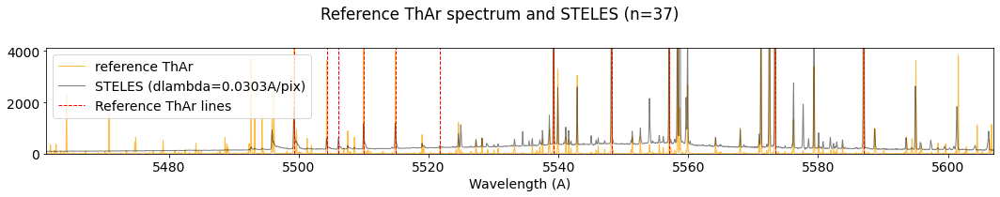

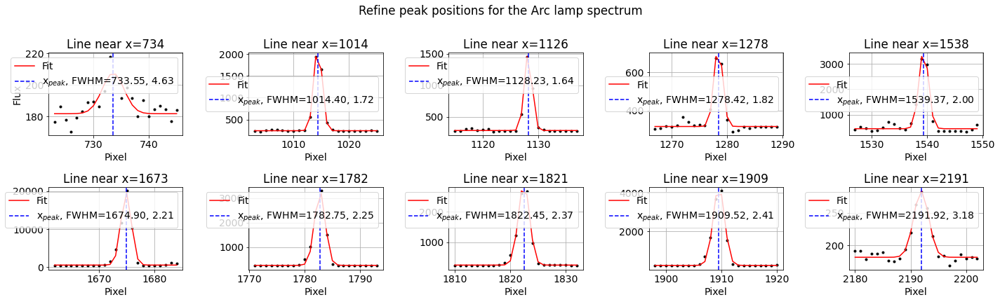

Converged at iteration 2


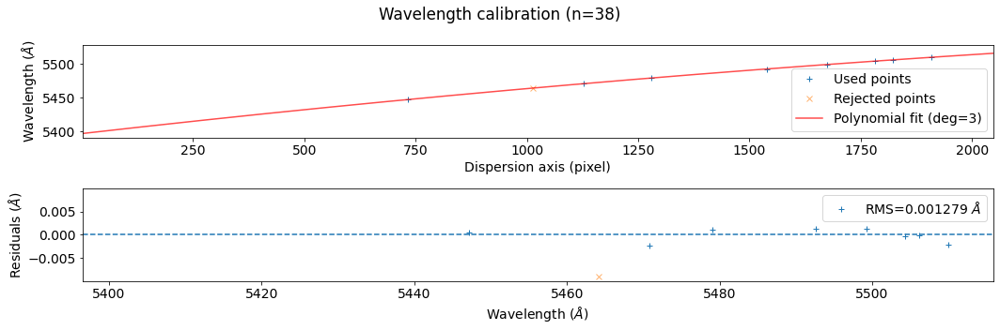

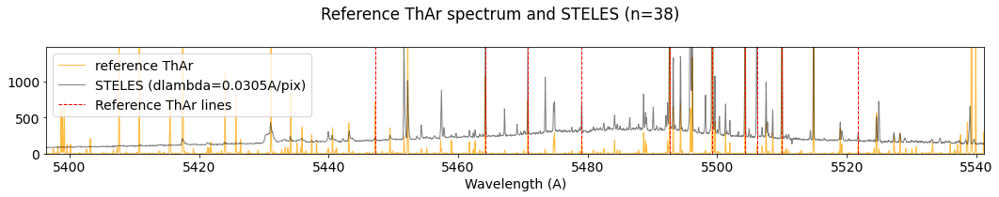

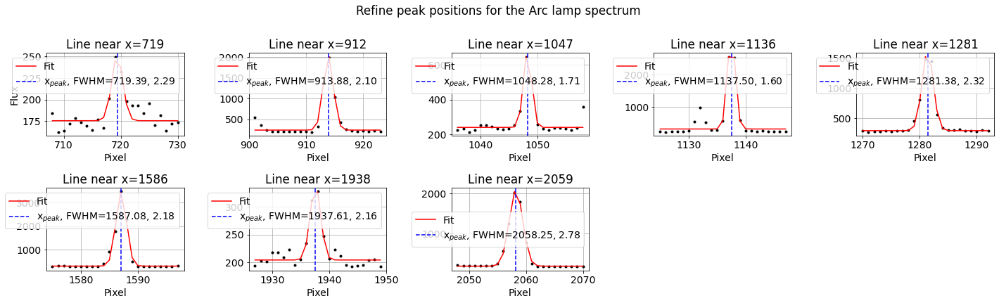

Converged at iteration 1


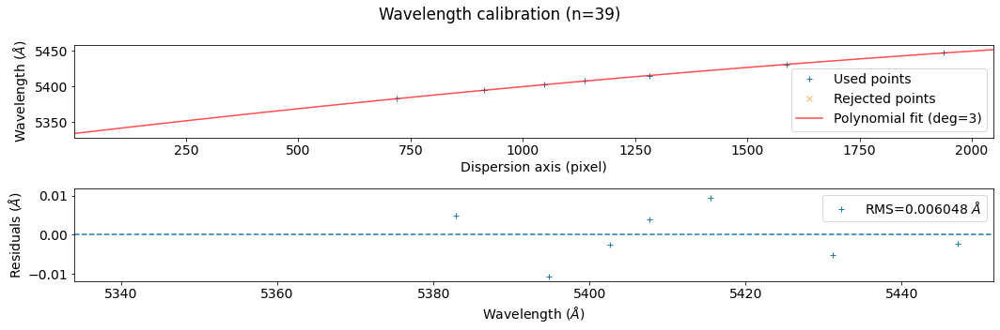

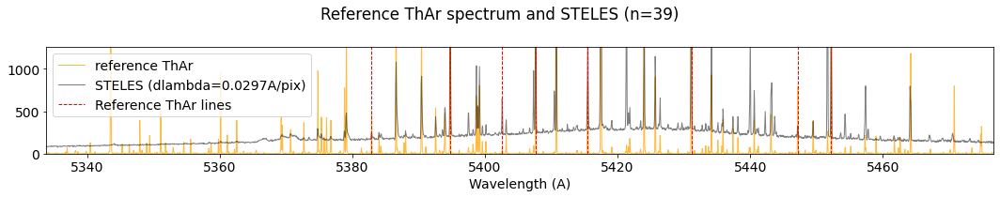

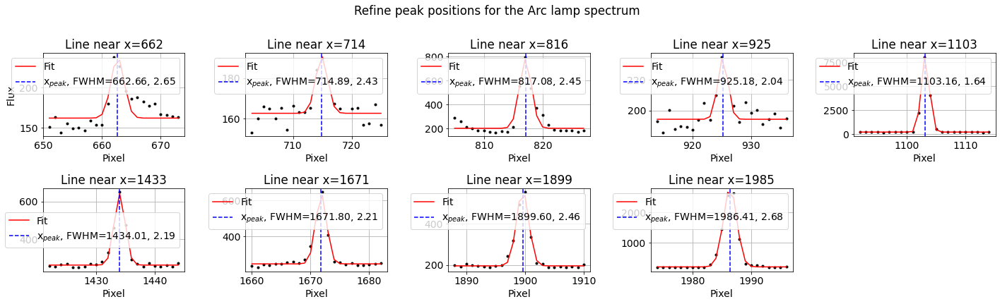

Converged at iteration 1


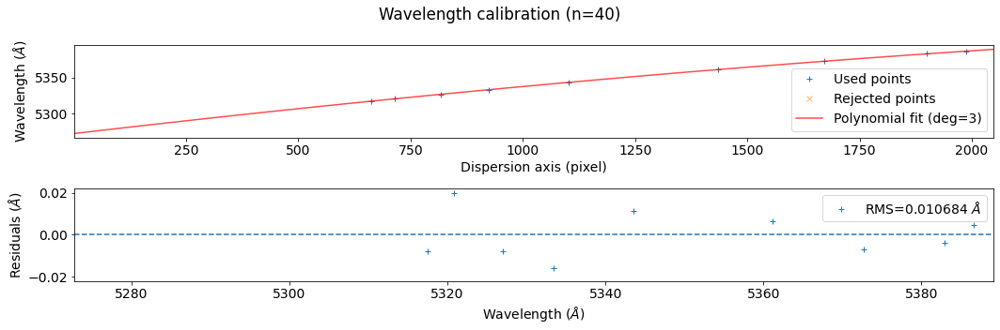

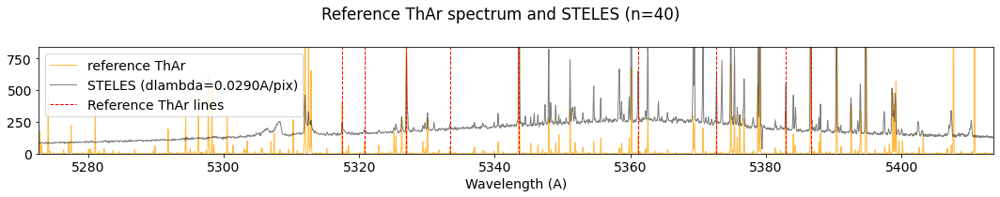

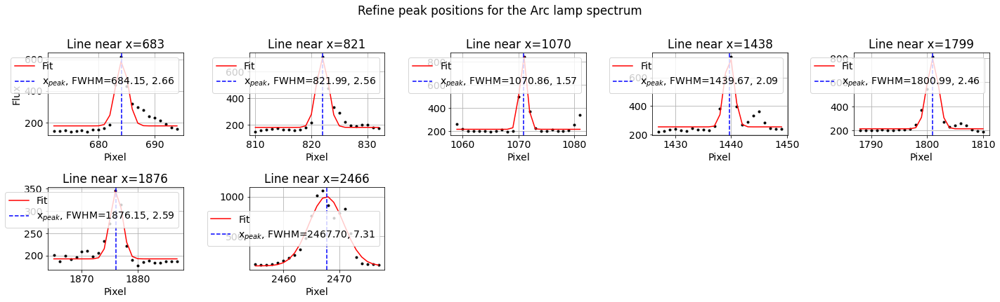

Converged at iteration 1


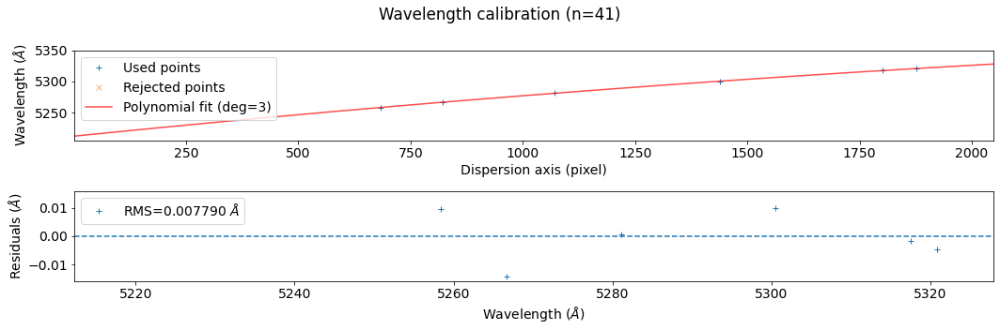

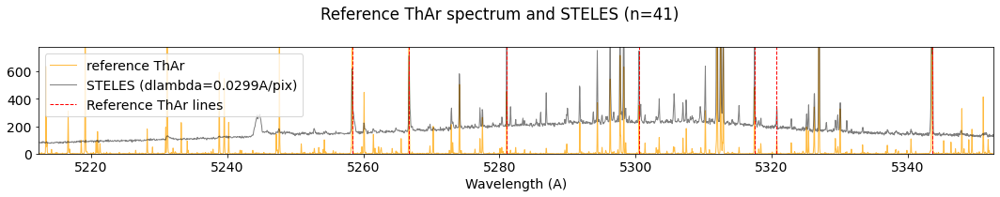

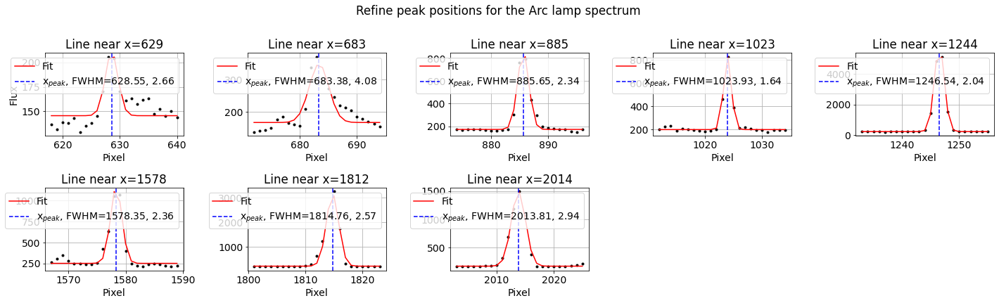

Converged at iteration 1


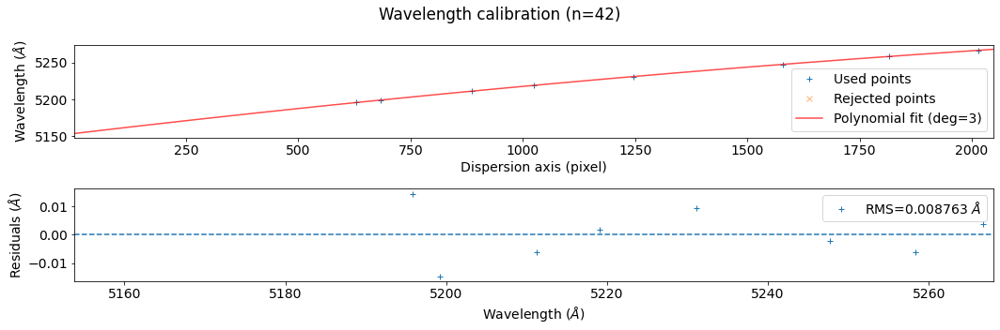

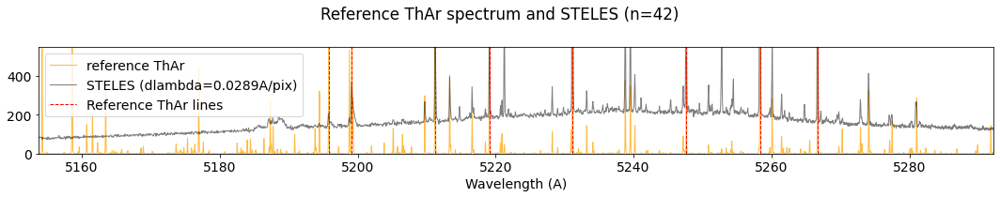

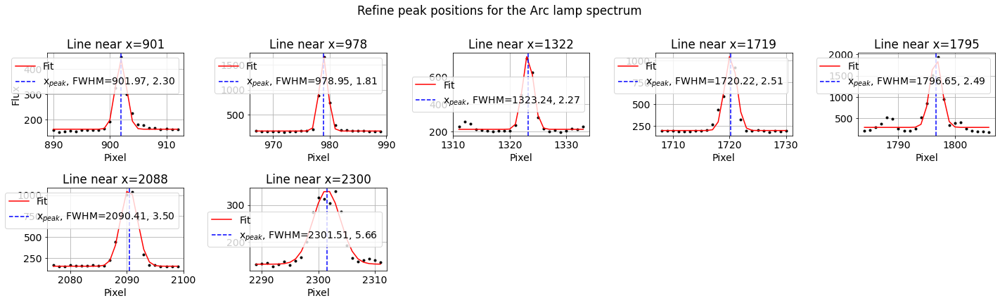

Converged at iteration 1


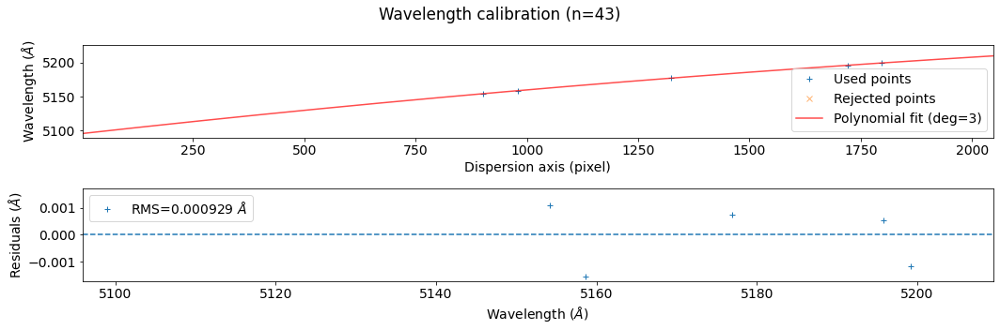

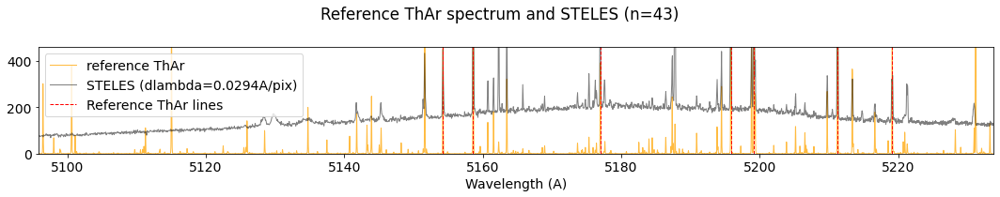

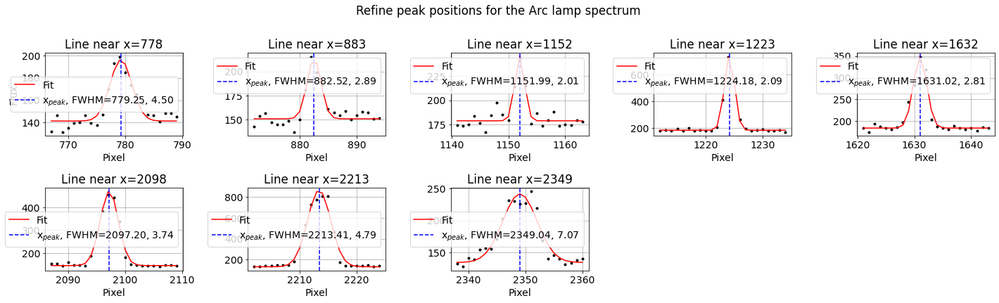

Converged at iteration 2


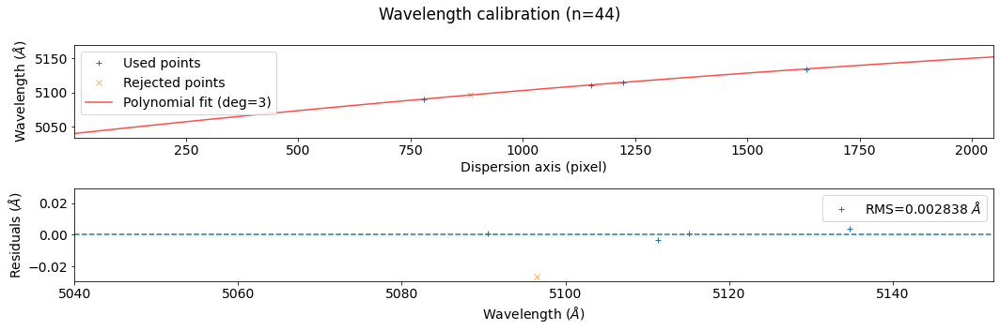

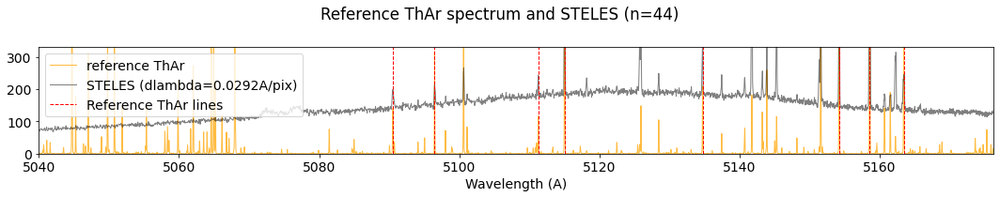

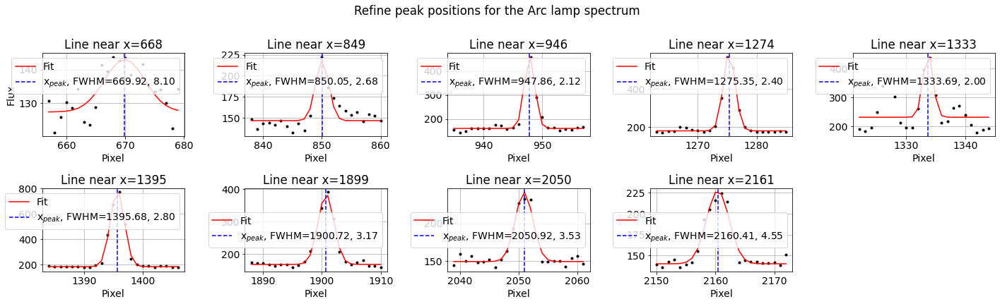

Converged at iteration 1


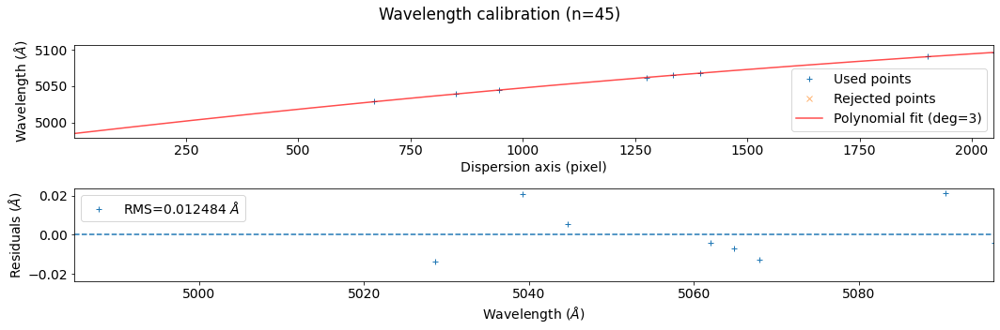

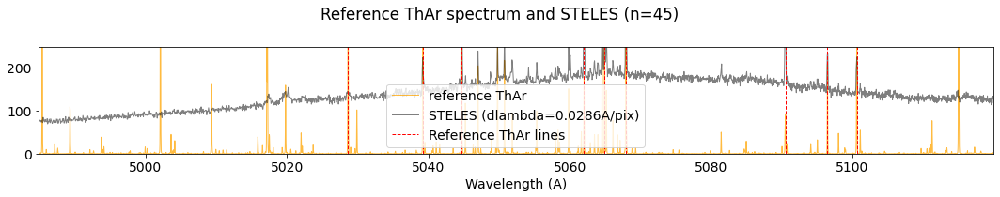

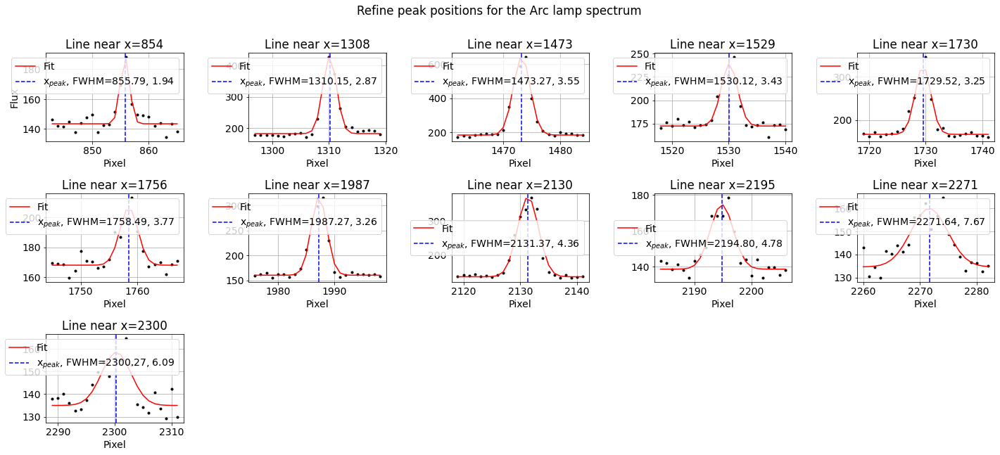

Converged at iteration 3


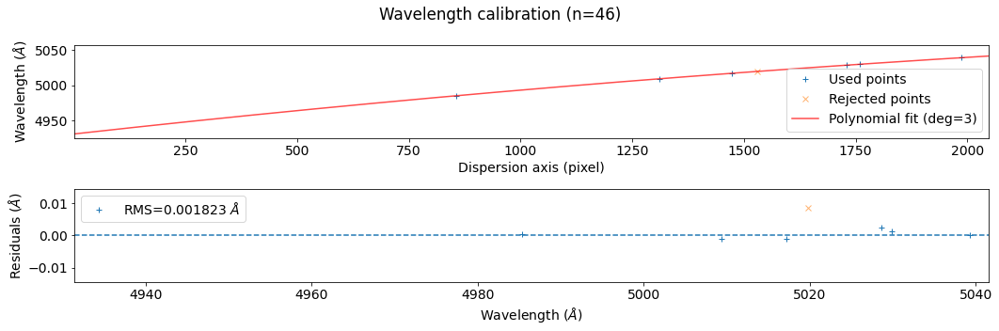

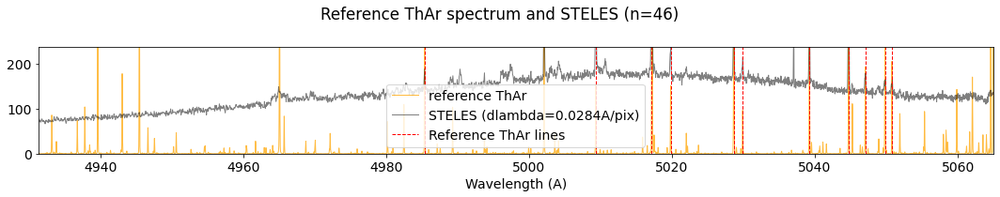

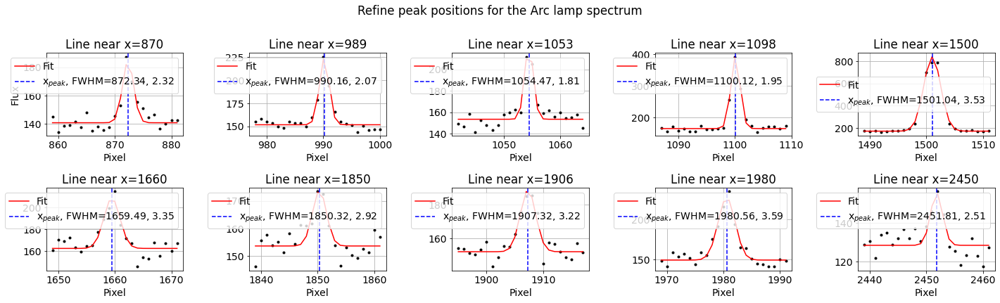

Converged at iteration 1


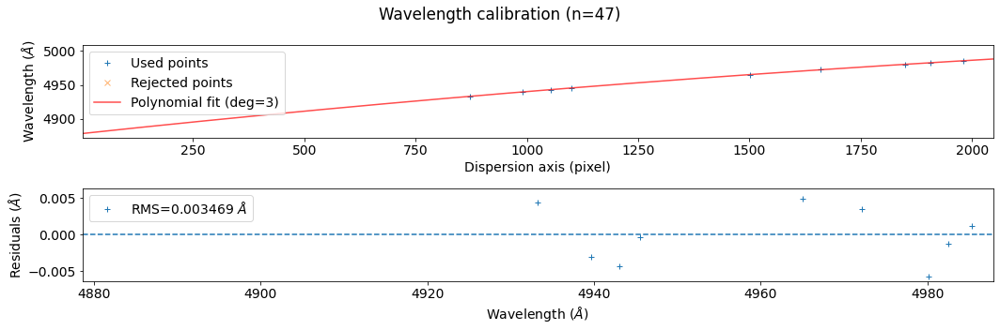

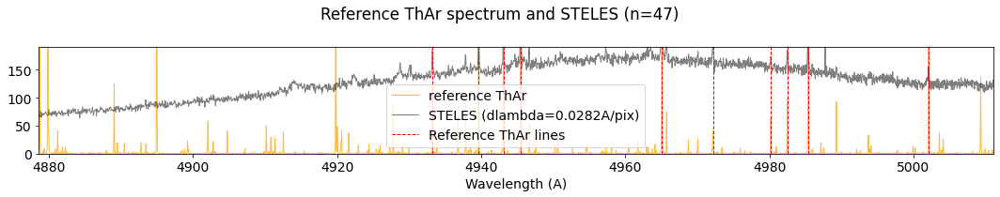

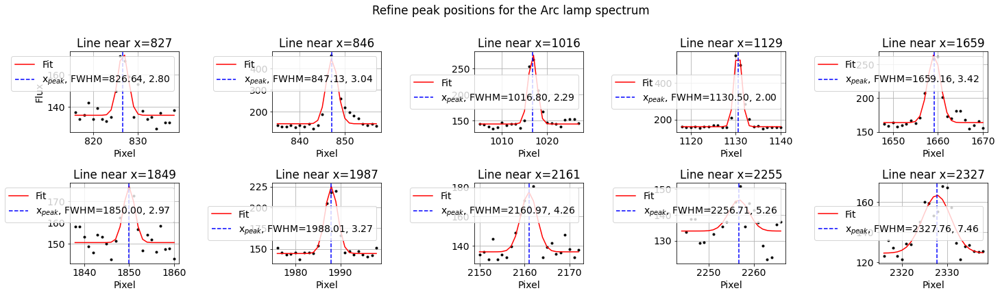

Converged at iteration 2


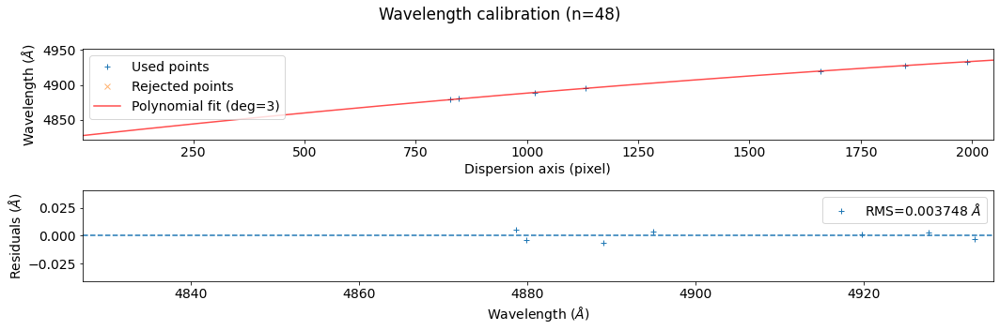

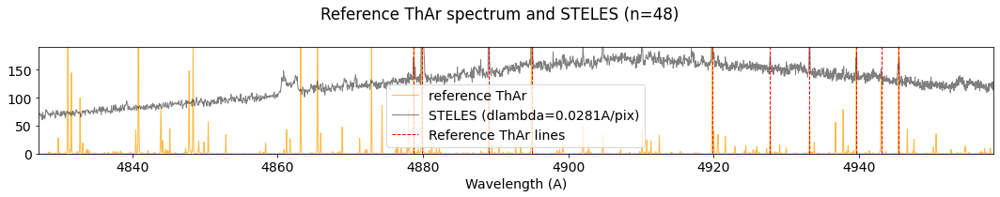

[INFO] Saved wavelength QC table: D:/SOAR/Steles/2026-01-29_red/RED/master_ThAr_600mas_wavelength_qc.csv
[INFO] Evaluating wavelength solution completed in 455.16s
[INFO] Saved RMS histogram: D:/SOAR/Steles/2026-01-29_red/RED/plots\qc_rms_hist.png
[INFO] Saved dispersion plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\qc_dispersion.png
[INFO] Saved residuals plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\qc_residuals.png
[INFO] Loading linearized products
[INFO] Loading wavelength solution file
[INFO] Fitting spatial distortion
[INFO] [1/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1950.74)
Using 75/75 measurements.


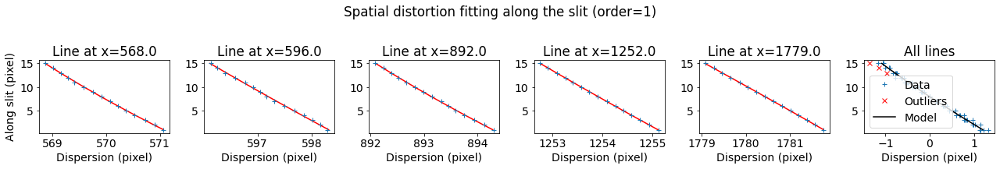

[INFO] [2/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<861.83)
Using 135/135 measurements.


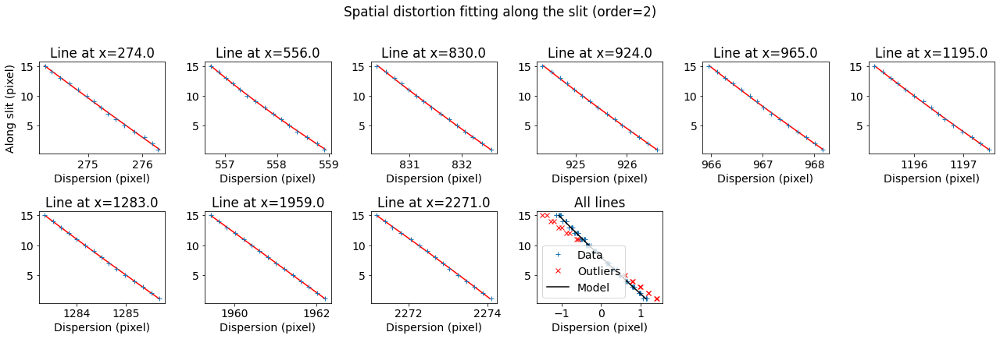

[INFO] [3/48] Fitting spatial distortion
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


 Excluding 45 saturated measurements (>1000000.0)
 Excluding 5 measurements below 3.00-sigma (<1765.25)
Using 55/105 measurements.


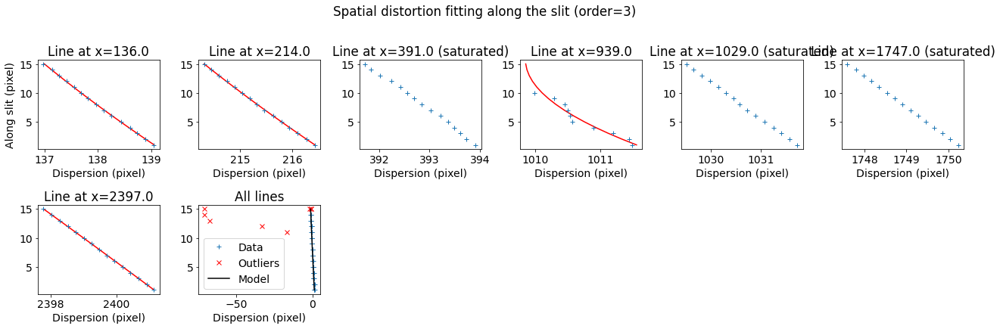

[INFO] [4/48] Fitting spatial distortion


 Excluding 30 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1967.19)
Using 45/75 measurements.


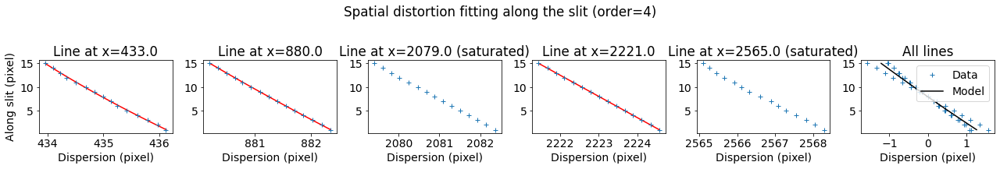

[INFO] [5/48] Fitting spatial distortion


 Excluding 2 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1705.18)
Using 178/180 measurements.


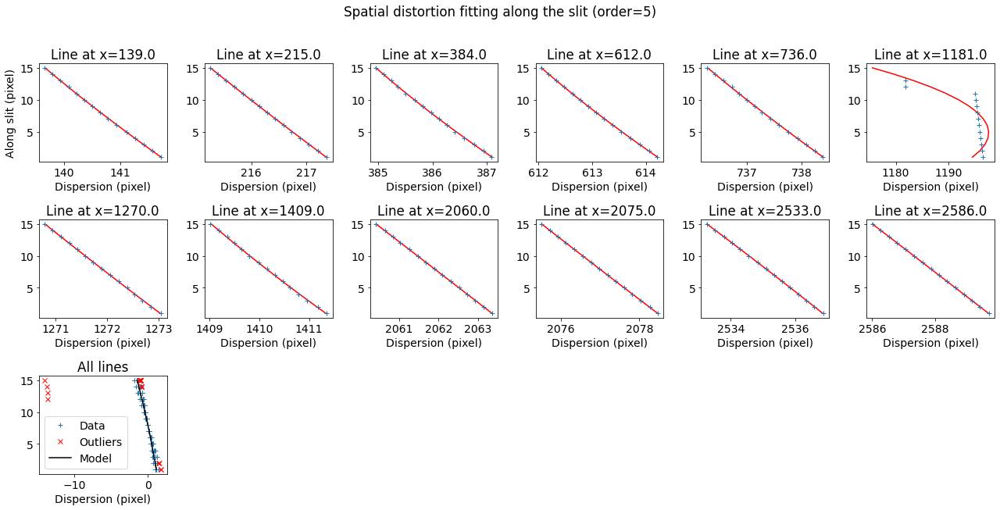

[INFO] [6/48] Fitting spatial distortion


 Excluding 15 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<2797.03)
Using 120/135 measurements.


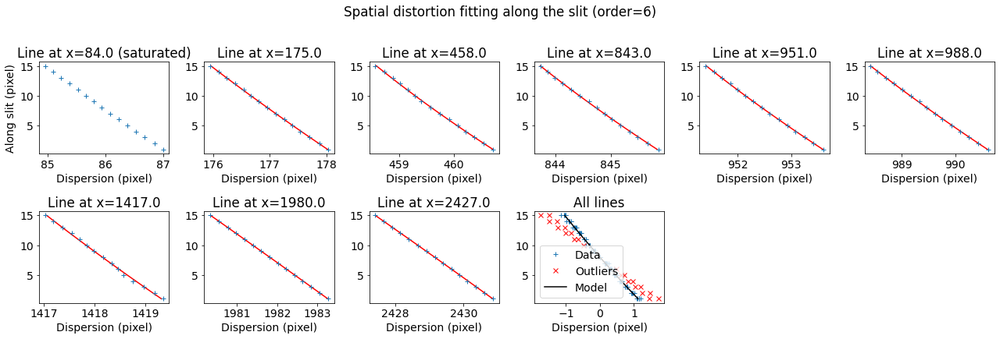

[INFO] [7/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<4544.01)
Using 135/135 measurements.


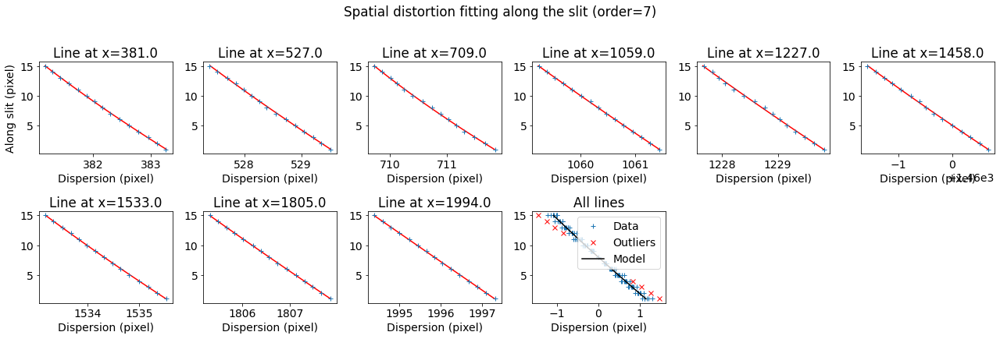

[INFO] [8/48] Fitting spatial distortion
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


 Excluding 9 saturated measurements (>1000000.0)
 Excluding 30 measurements below 3.00-sigma (<6069.57)
Using 96/135 measurements.


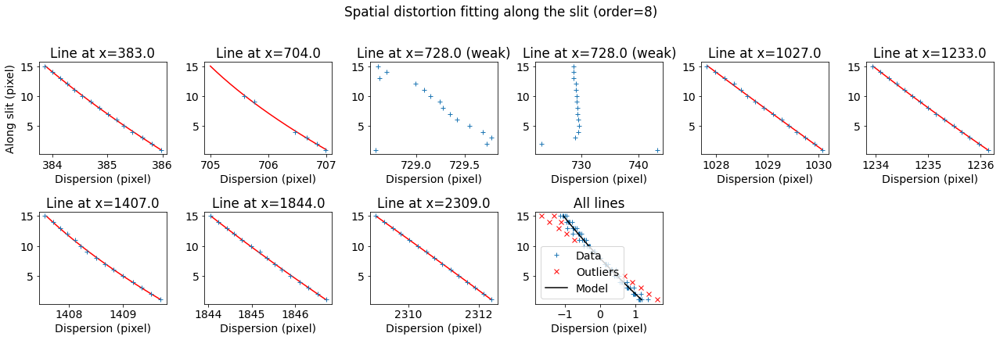

[INFO] [9/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<4336.34)
Using 120/120 measurements.


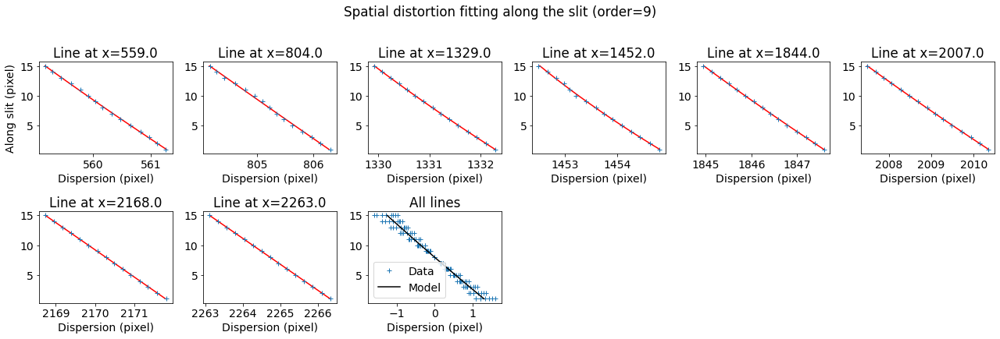

[INFO] [10/48] Fitting spatial distortion


Fit failed near x=1107
Fit failed near x=752
Fit failed near x=1126
Fit failed near x=1131
 Excluding 2 saturated measurements (>1000000.0)
 Excluding 45 measurements below 3.00-sigma (<4157.54)
Using 88/135 measurements.


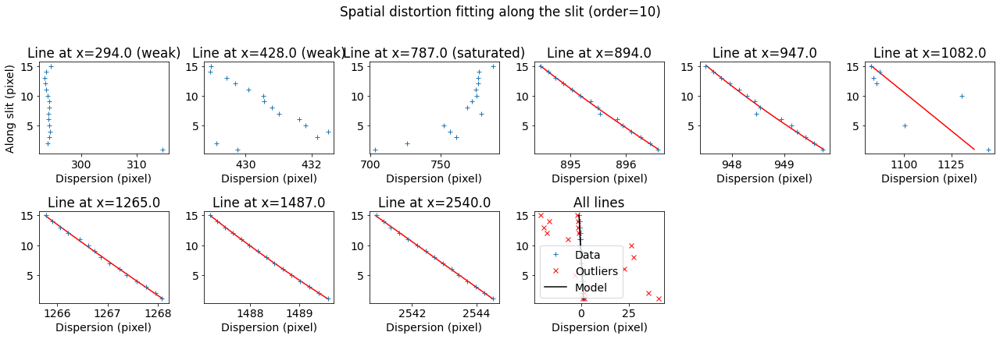

[INFO] [11/48] Fitting spatial distortion
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 34 measurements below 3.00-sigma (<12737.94)
Using 101/135 measurements.


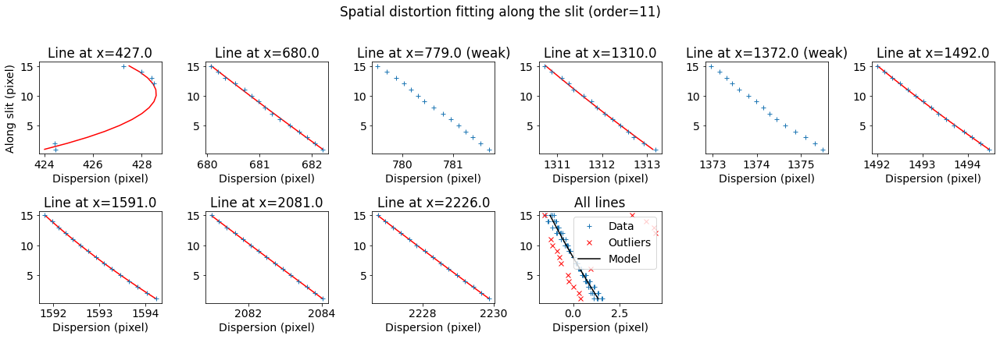

[INFO] [12/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 12 measurements below 3.00-sigma (<6480.80)
Using 123/135 measurements.


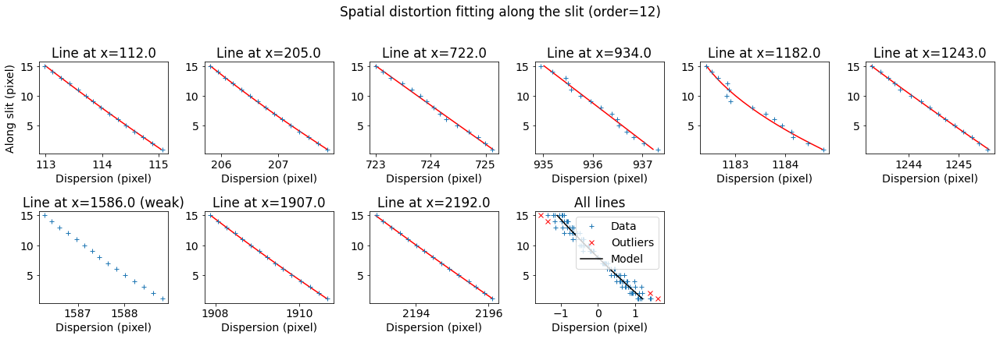

[INFO] [13/48] Fitting spatial distortion
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 15 measurements below 3.00-sigma (<3774.37)
Using 120/135 measurements.


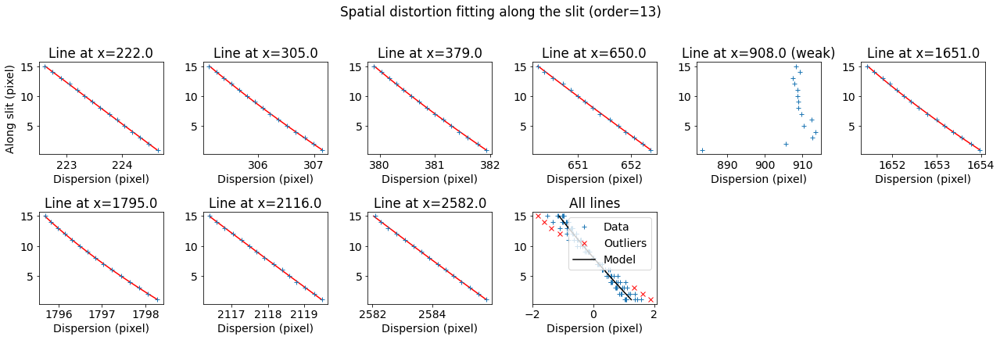

[INFO] [14/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<3441.95)
Using 135/135 measurements.


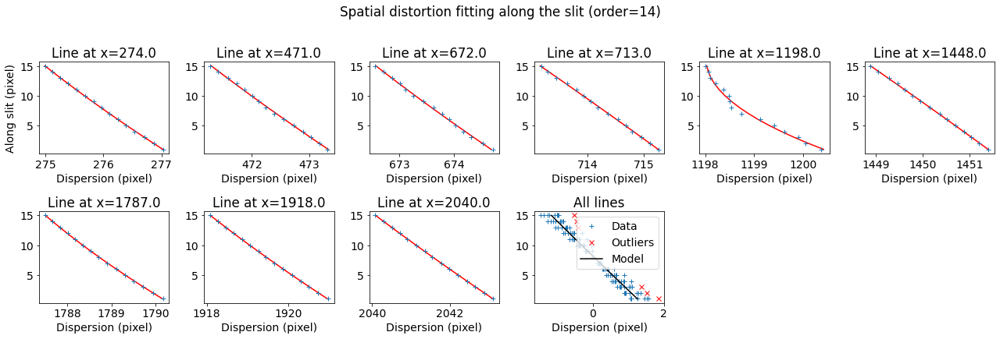

[INFO] [15/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<3840.62)
Using 180/180 measurements.


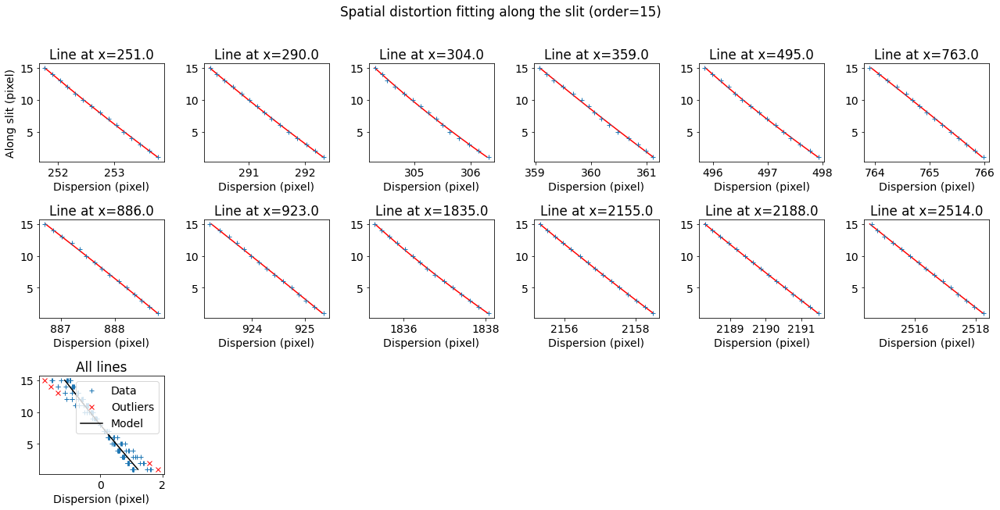

[INFO] [16/48] Fitting spatial distortion
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<3875.19)
Using 195/195 measurements.


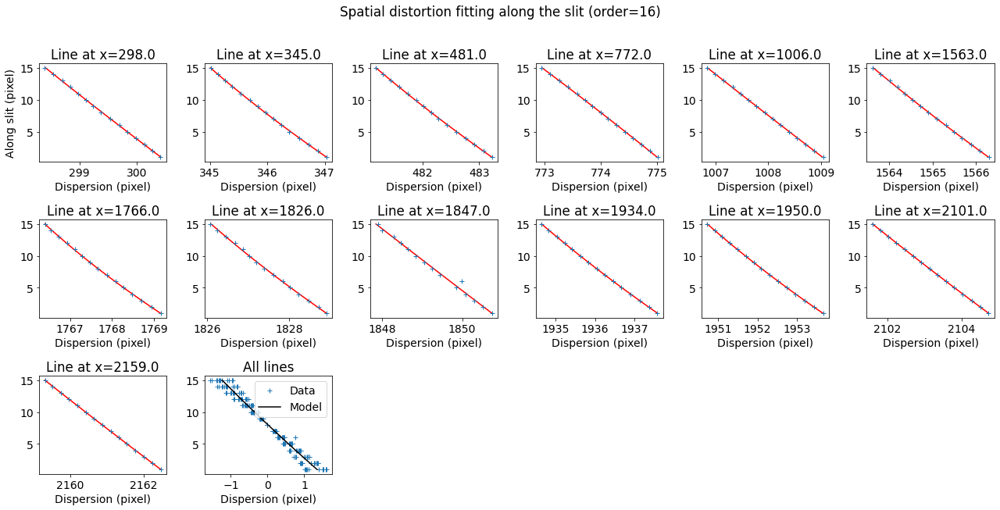

[INFO] [17/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 8 measurements below 3.00-sigma (<4096.14)
Using 187/195 measurements.


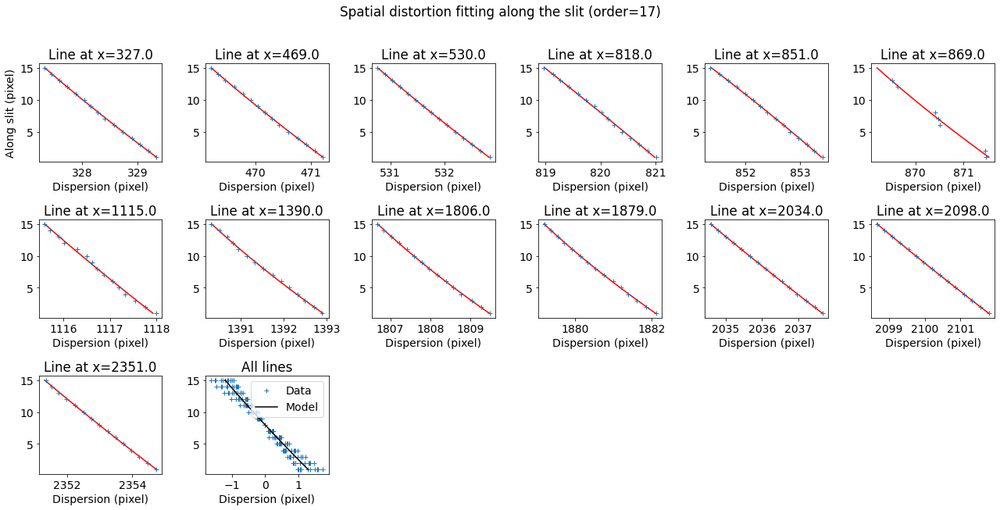

[INFO] [18/48] Fitting spatial distortion
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<4054.55)
Using 150/150 measurements.


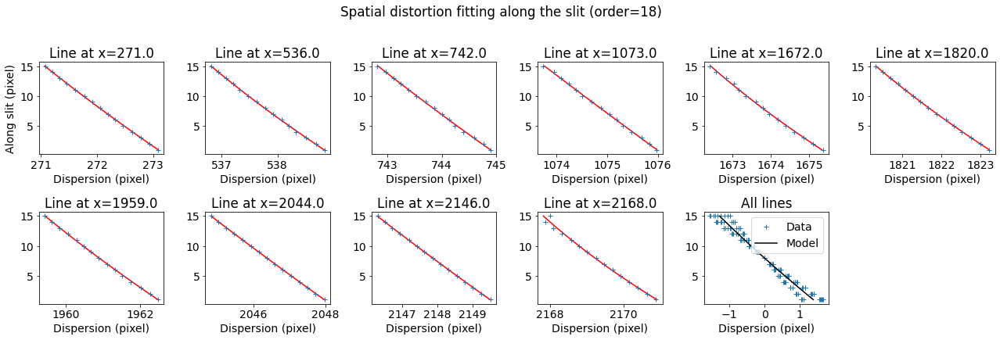

[INFO] [19/48] Fitting spatial distortion


Fit failed near x=1505
Fit failed near x=1505
Fit failed near x=1505
Fit failed near x=1505
Fit failed near x=1505
Fit failed near x=1505
Fit failed near x=1505
Fit failed near x=-893
 Excluding 1 saturated measurements (>1000000.0)
 Excluding 6 measurements below 3.00-sigma (<3185.11)
Using 158/165 measurements.


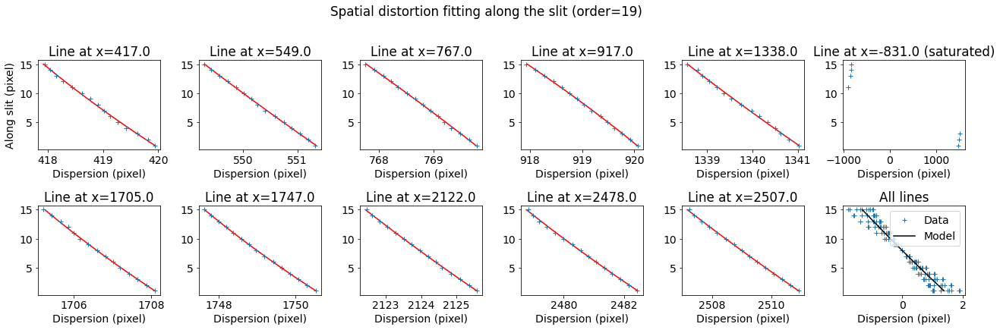

[INFO] [20/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<3144.35)
Using 135/135 measurements.


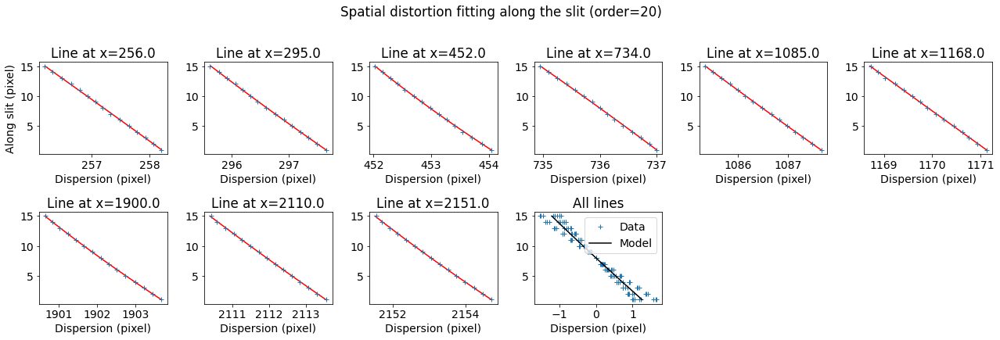

[INFO] [21/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<2615.41)
Using 150/150 measurements.


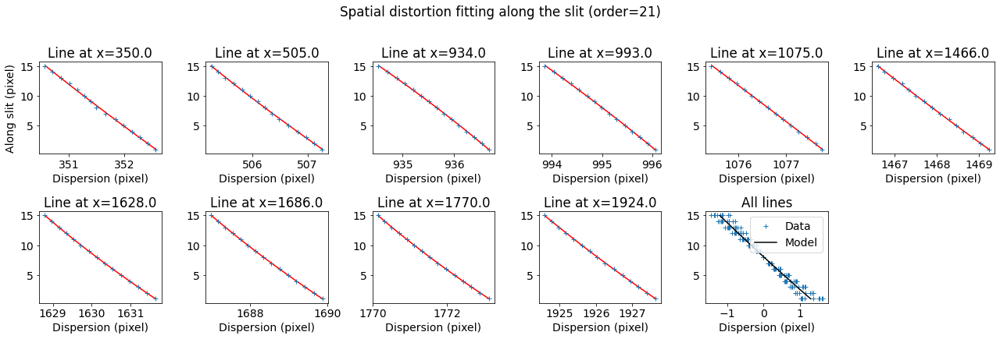

[INFO] [22/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<2209.72)
Using 150/150 measurements.


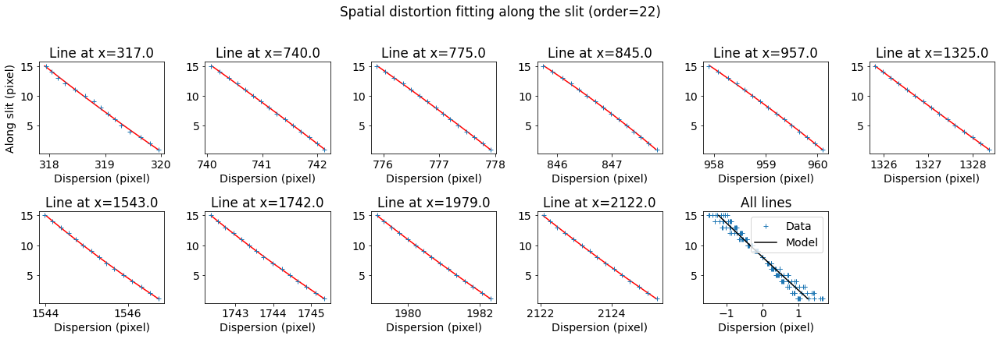

[INFO] [23/48] Fitting spatial distortion
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 15 measurements below 3.00-sigma (<2349.97)
Using 180/195 measurements.


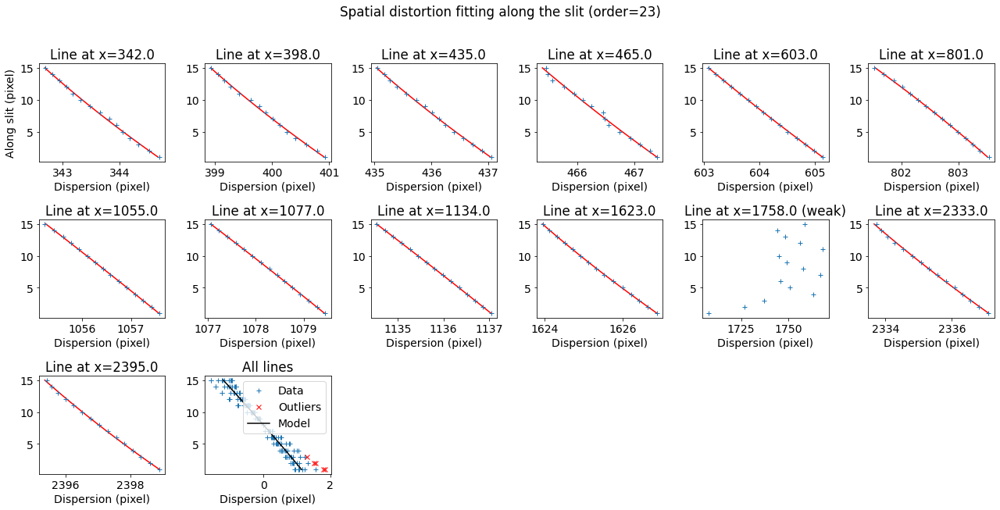

[INFO] [24/48] Fitting spatial distortion


 Excluding 17 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<2008.27)
Using 163/180 measurements.


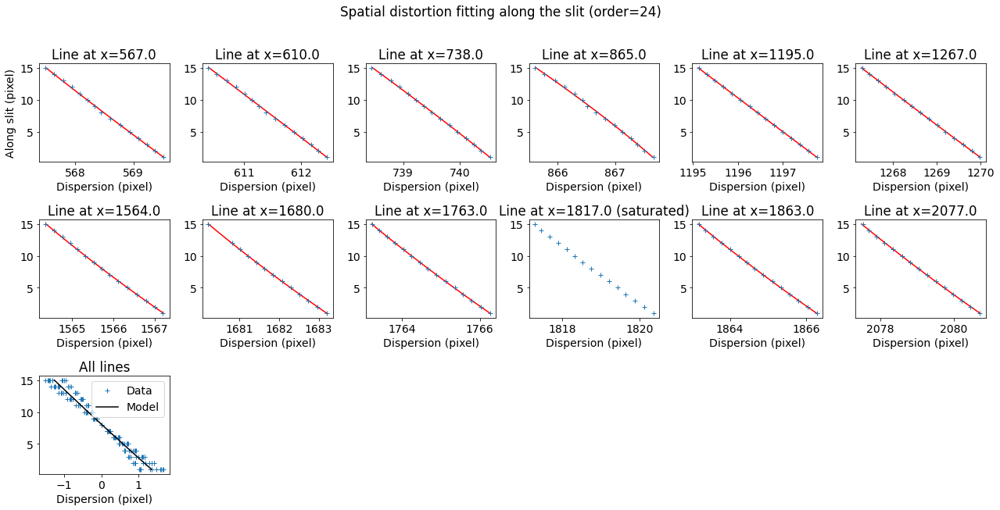

[INFO] [25/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1856.77)
Using 150/150 measurements.


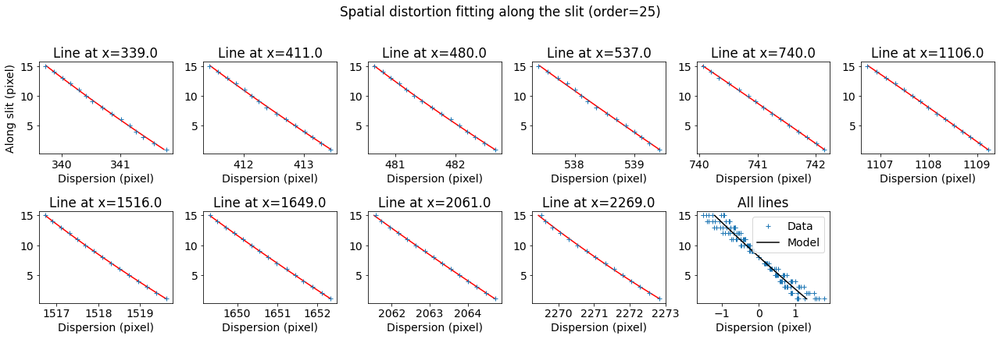

[INFO] [26/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1888.31)
Using 165/165 measurements.


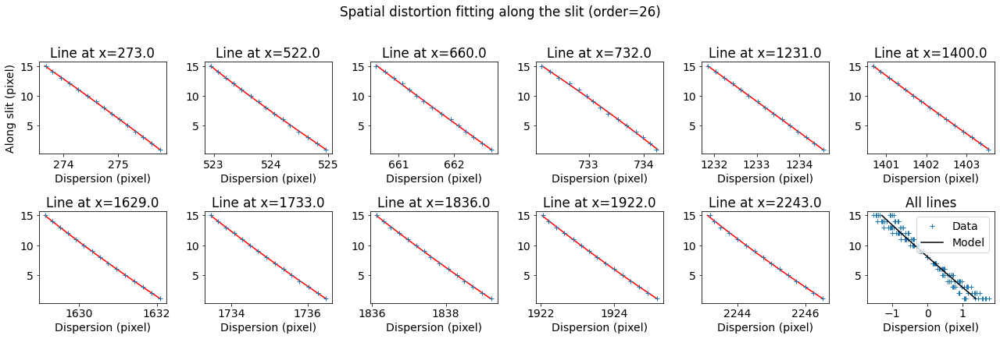

[INFO] [27/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1672.26)
Using 120/120 measurements.


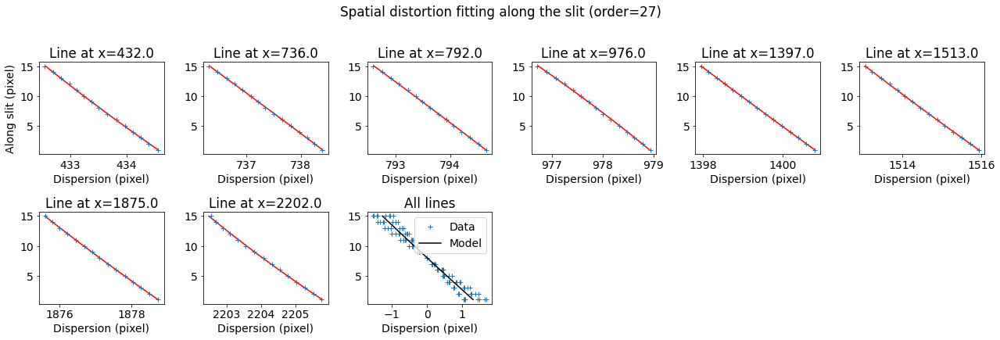

[INFO] [28/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1779.42)
Using 165/165 measurements.


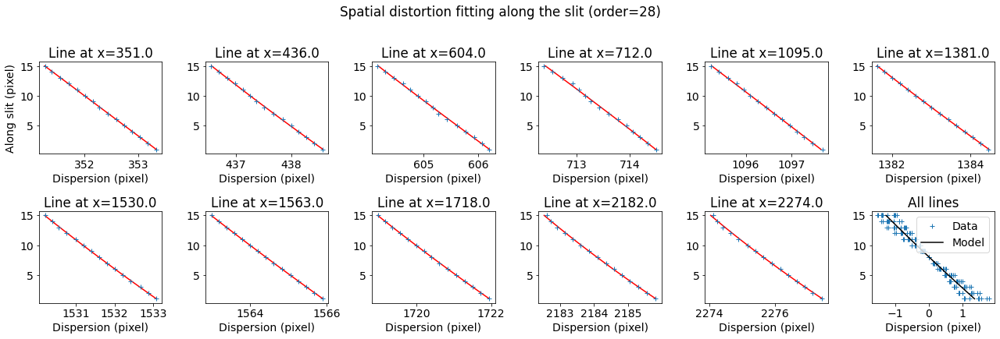

[INFO] [29/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1582.20)
Using 150/150 measurements.


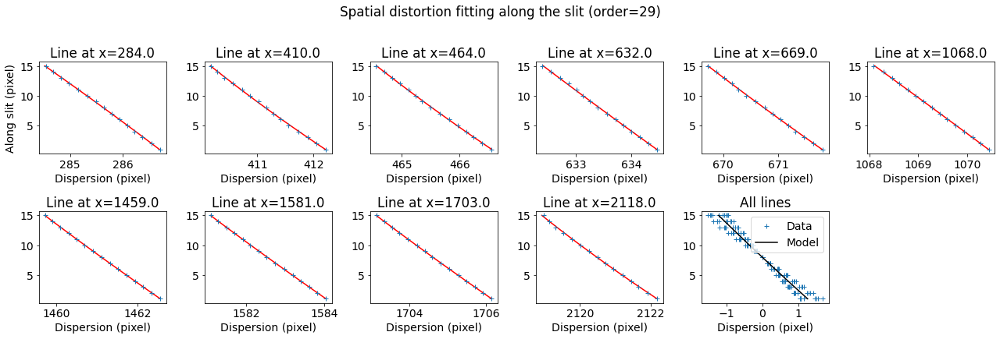

[INFO] [30/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1288.76)
Using 165/165 measurements.


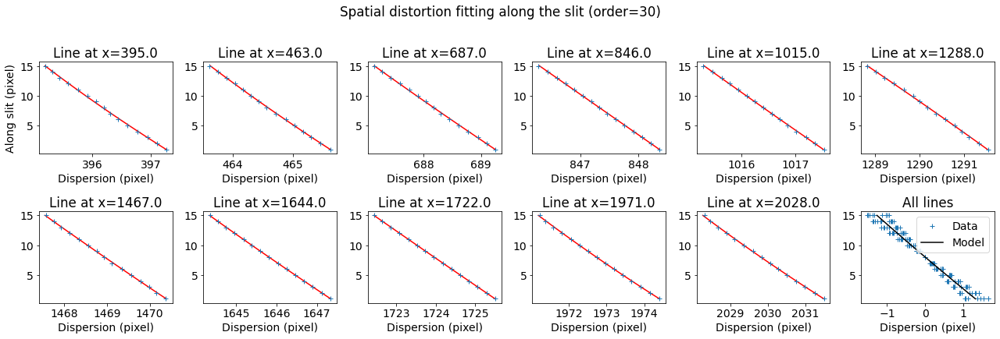

[INFO] [31/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<1159.97)
Using 120/120 measurements.


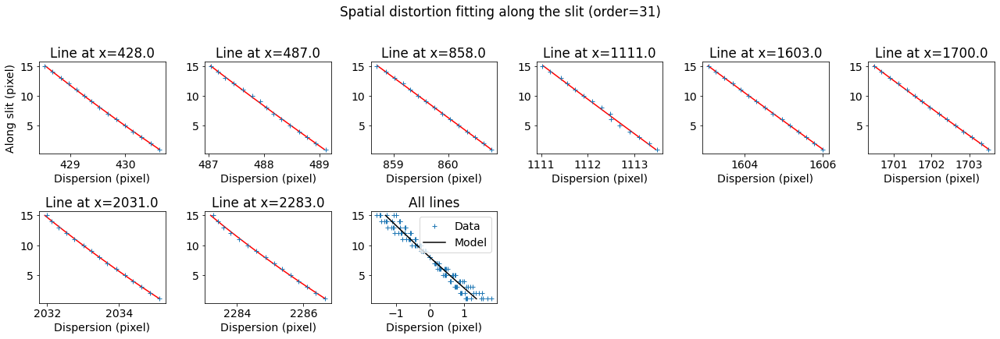

[INFO] [32/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<864.12)
Using 150/150 measurements.


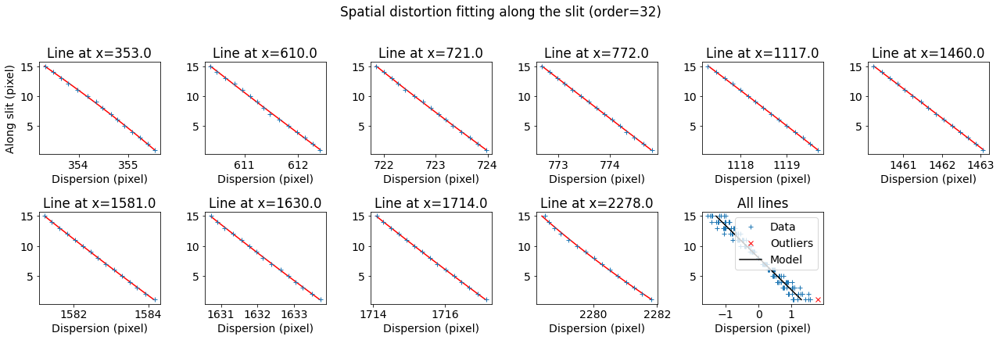

[INFO] [33/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<714.19)
Using 195/195 measurements.


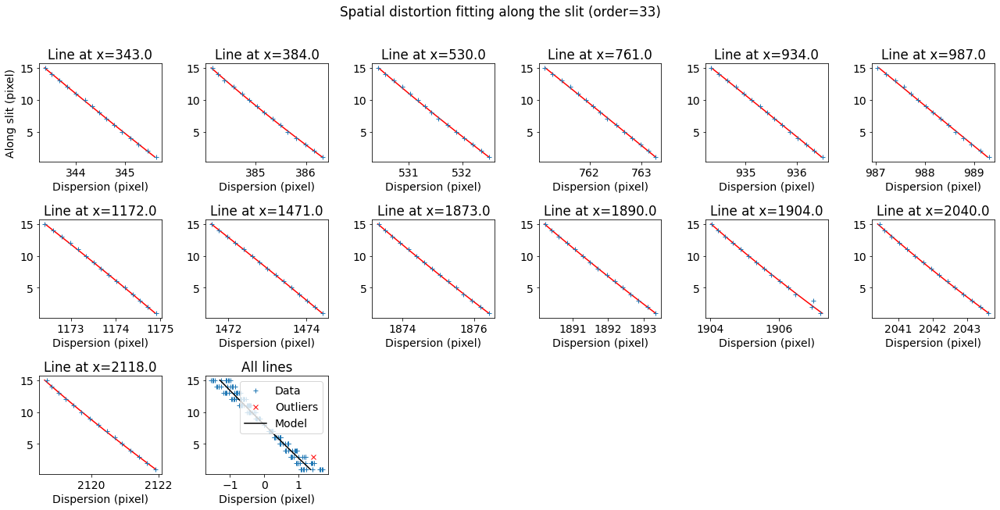

[INFO] [34/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<556.43)
Using 165/165 measurements.


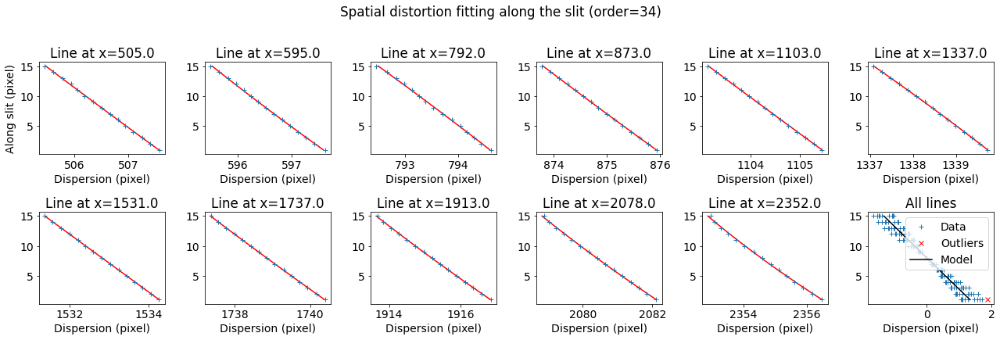

[INFO] [35/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<467.97)
Using 120/120 measurements.


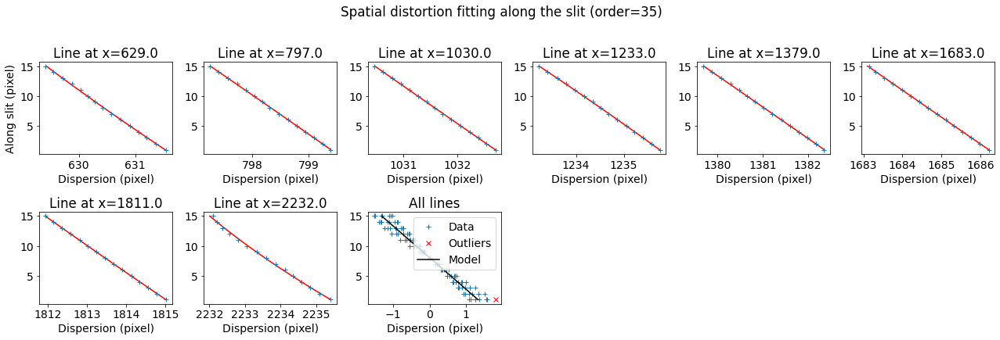

[INFO] [36/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<399.01)
Using 105/105 measurements.


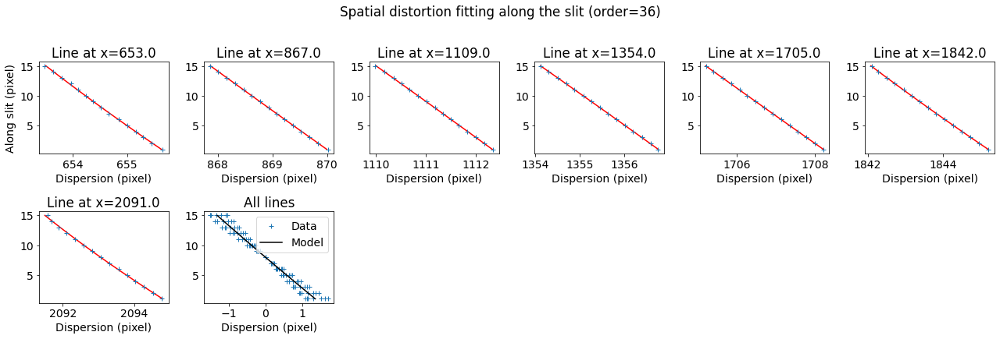

[INFO] [37/48] Fitting spatial distortion
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 13 measurements below 3.00-sigma (<321.23)
Using 152/165 measurements.


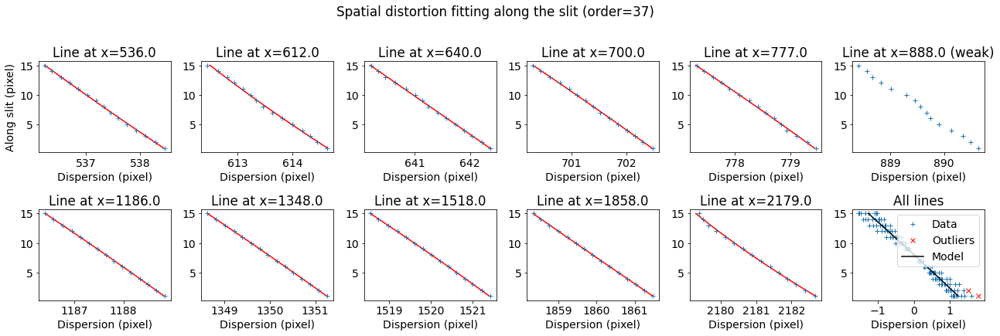

[INFO] [38/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 15 measurements below 3.00-sigma (<240.64)
Using 135/150 measurements.


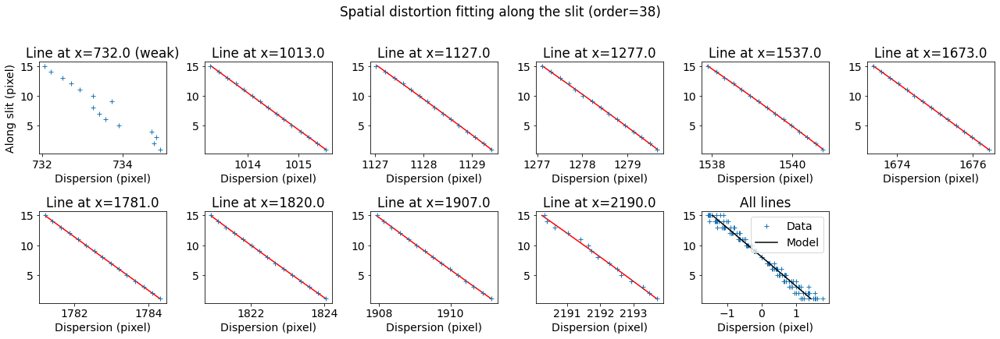

[INFO] [39/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 7 measurements below 3.00-sigma (<219.58)
Using 113/120 measurements.


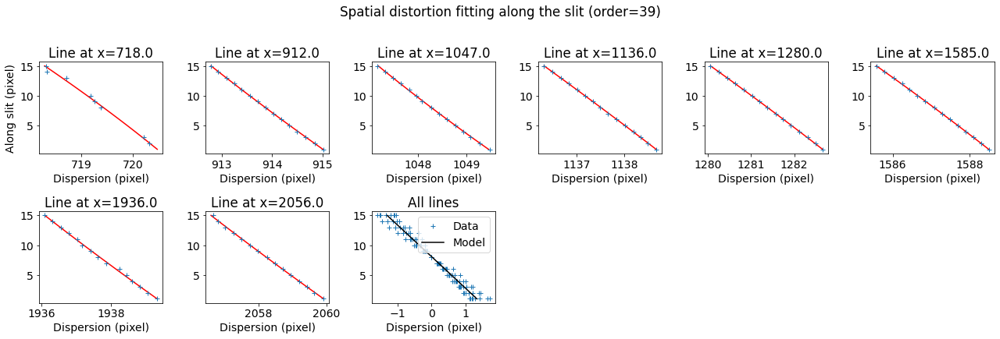

[INFO] [40/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 34 measurements below 3.00-sigma (<198.65)
Using 101/135 measurements.


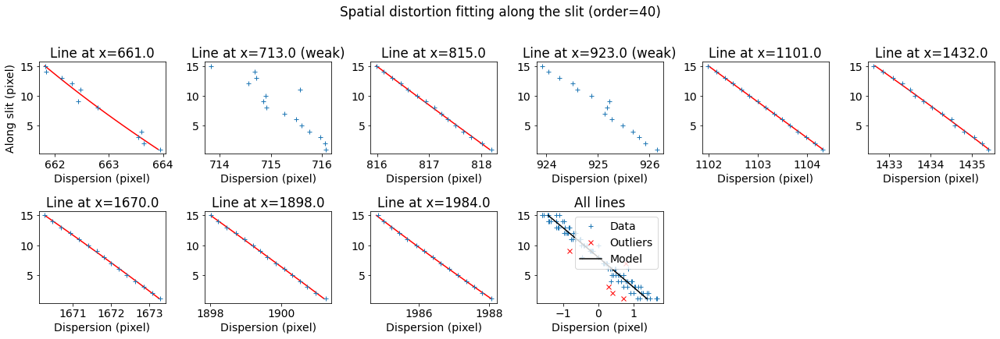

[INFO] [41/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<163.94)
Using 105/105 measurements.


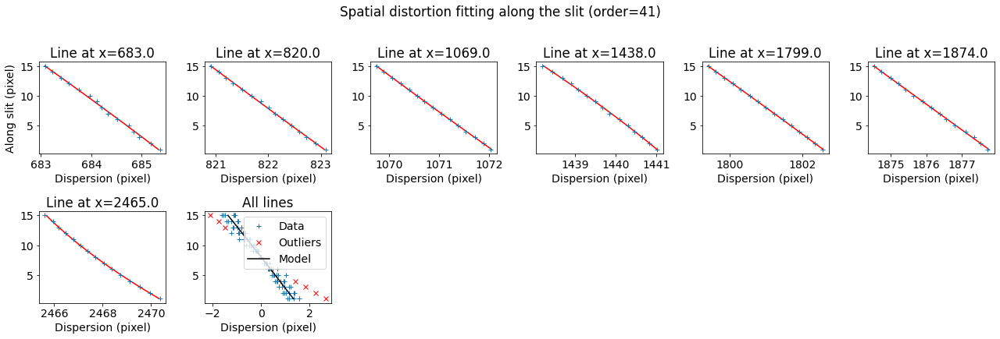

[INFO] [42/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<148.49)
Using 120/120 measurements.


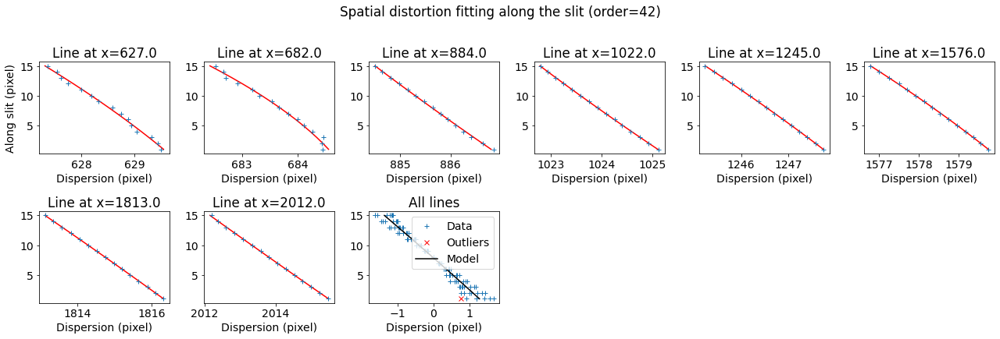

[INFO] [43/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<135.06)
Using 105/105 measurements.


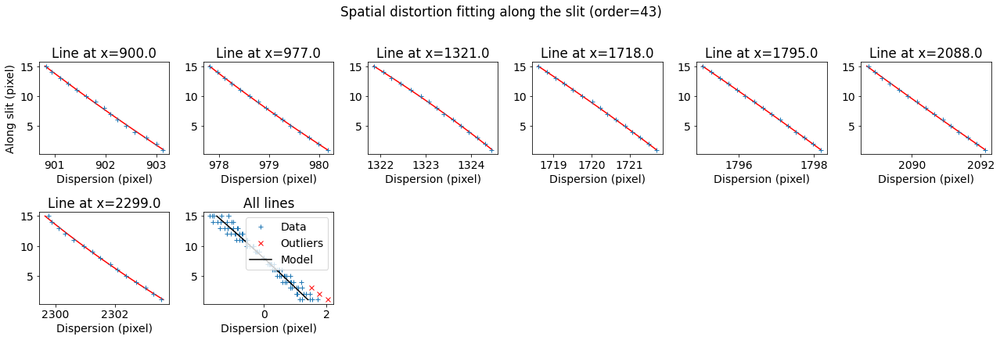

[INFO] [44/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 0 measurements below 3.00-sigma (<117.13)
Using 120/120 measurements.


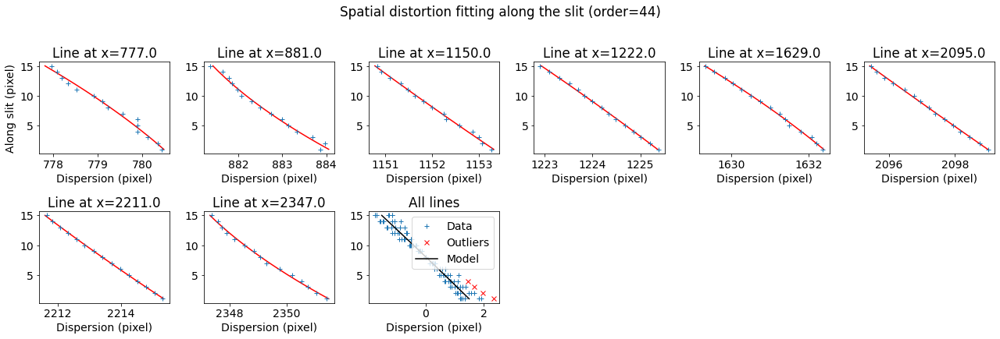

[INFO] [45/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 15 measurements below 3.00-sigma (<104.23)
Using 120/135 measurements.


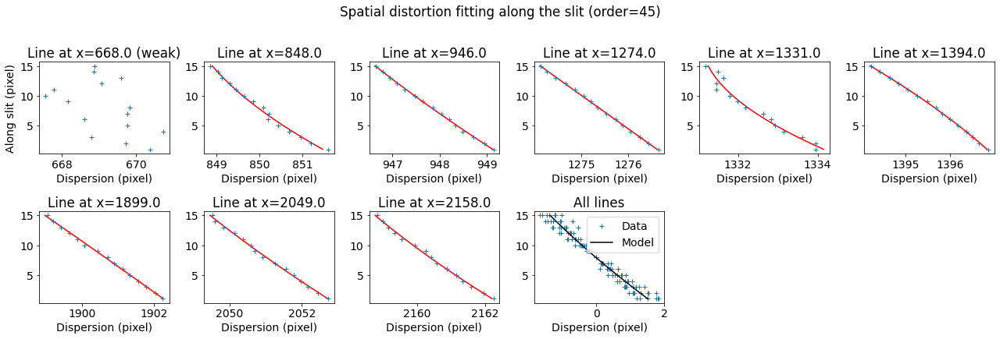

[INFO] [46/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 32 measurements below 3.00-sigma (<97.02)
Using 133/165 measurements.


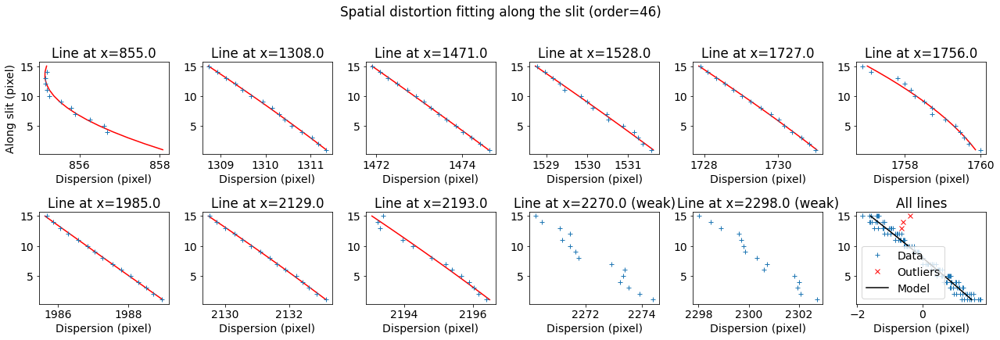

[INFO] [47/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 30 measurements below 3.00-sigma (<89.86)
Using 120/150 measurements.


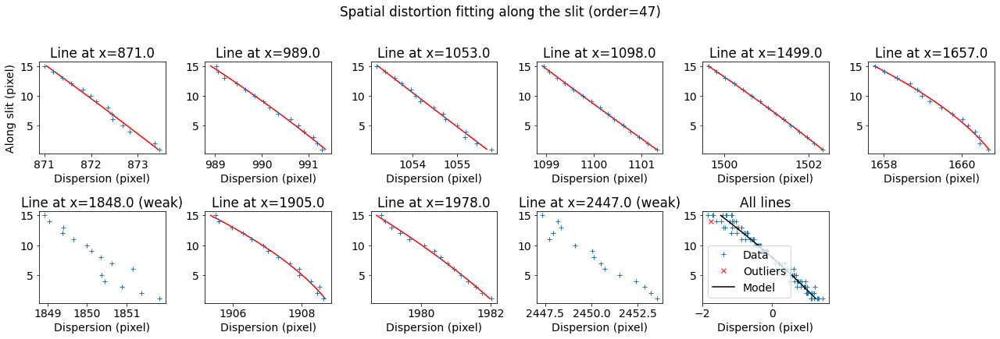

[INFO] [48/48] Fitting spatial distortion


 Excluding 0 saturated measurements (>1000000.0)
 Excluding 41 measurements below 3.00-sigma (<86.27)
Using 109/150 measurements.


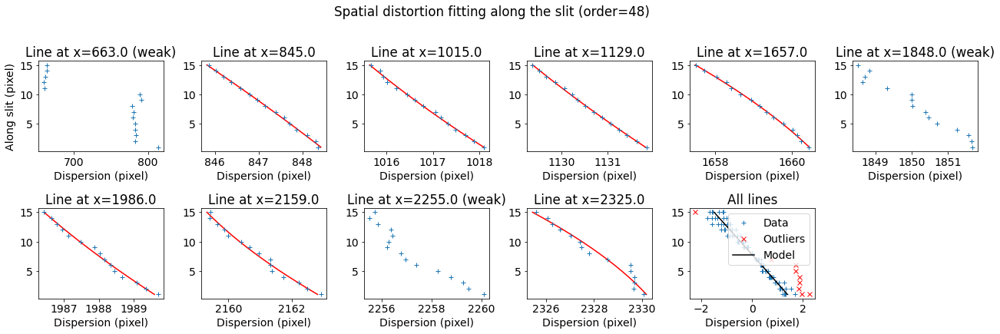

[INFO] Evaluating spatial distortion solution completed in 156.81s
[INFO] Applying wavelength + distortion solution
[INFO] Applying calibration to flat
[INFO] Applying calibration to arc
[INFO] Applying calibration to sci
[INFO] Computing blaze function


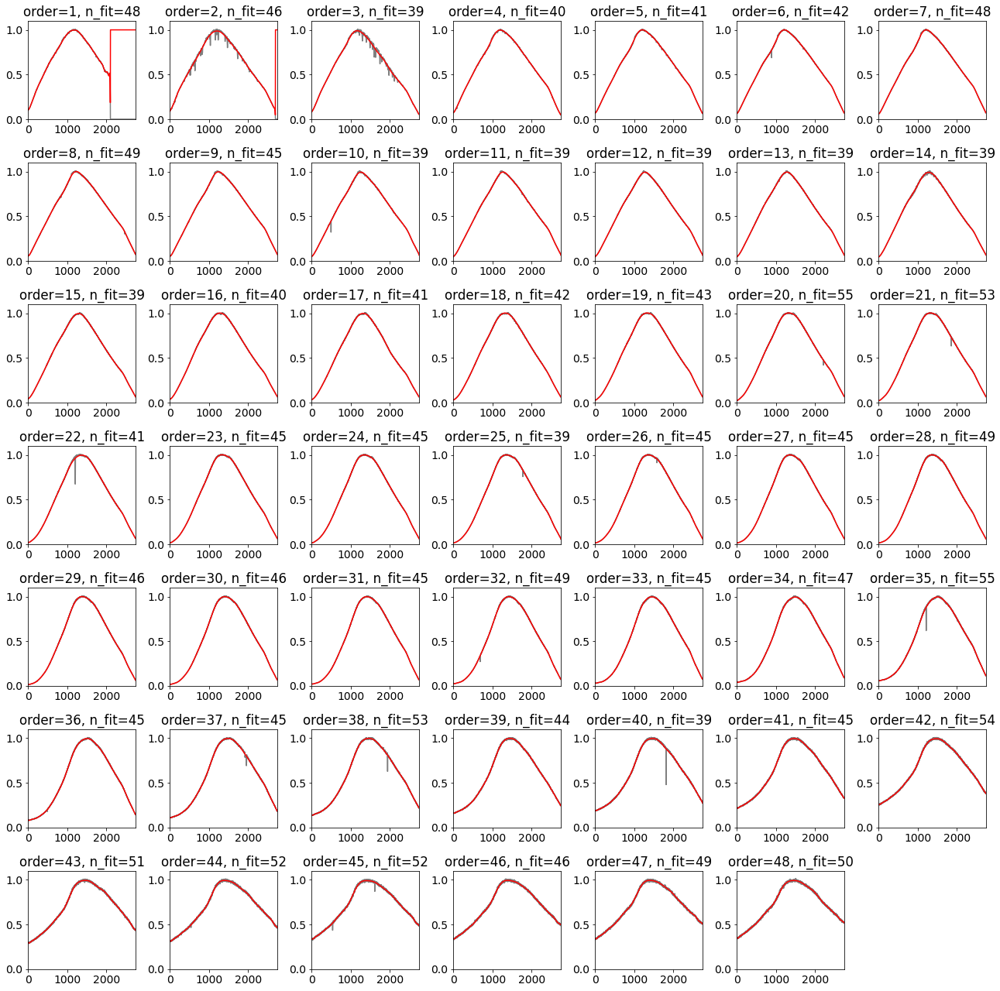

[INFO] Evaluating blaze function completed in 25.68s
[INFO] Extracting final spectra
[INFO] Loading blaze solution
[INFO] Loading blaze solution file
[INFO] Extracting one-dimensional spectrum completed in 0.10s
[INFO] Loading extracted spectrum
[INFO] Loading linearized products


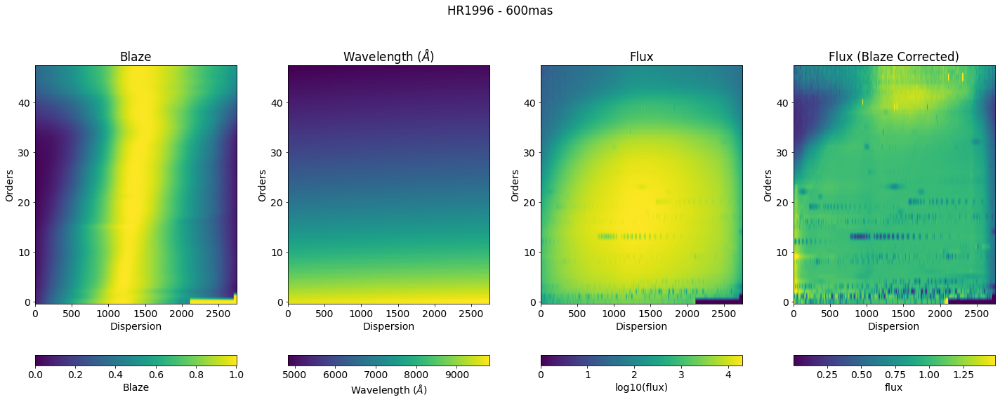

[INFO] Generating blaze vs spectrum QC plots
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:1485: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
[INFO] Saved QC plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_blaze_qc_panel1.png
[INFO] Saved QC plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_blaze_qc_panel2.png
[INFO] Saved QC plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_blaze_qc_panel3.png
[INFO] Saved QC plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_blaze_qc_panel4.png
[INFO] Saved QC plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_blaze_qc_panel5.png
[INFO] Saved QC plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_blaze_qc_panel6.png
[INFO] Saved QC plot: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_blaze_qc_panel7.png
[INFO] Saved QC plot: D:/SOAR/Steles/2026-01-29_re

In [21]:
#pipeline_partII_blue = STELES_Pipeline_PartII(config_blue)
#pipeline_partII_blue.run()

pipeline_partII_red = STELES_Pipeline_PartII(config_red)
pipeline_partII_red.run()